**Architecture comparison environment audit**

In [ ]:
# ============================================================
# CELL 1 — ARCHITECTURE COMPARISON ENVIRONMENT AUDIT
# ============================================================

import os
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

KAGGLE_INPUT = "/kaggle/input"

print("=" * 70)
print("ARCHITECTURE COMPARISON — ENVIRONMENT AUDIT")
print("=" * 70)

print(f"\nPyTorch version : {torch.__version__}")
print(f"CUDA available : {torch.cuda.is_available()}")
print(f"Device         : {DEVICE}")

if torch.cuda.is_available():
    print(f"GPU            : {torch.cuda.get_device_name(0)}")

print("\nKaggle inputs:")

for item in sorted(os.listdir(KAGGLE_INPUT)):
    print(f"  - {item}")

print("\n" + "=" * 70)
print("ENVIRONMENT AUDIT COMPLETE")
print("=" * 70)

ARCHITECTURE COMPARISON — ENVIRONMENT AUDIT

PyTorch version : 2.10.0+cu128
CUDA available : True
Device         : cuda
GPU            : Tesla T4

Kaggle inputs:
  - datasets

ENVIRONMENT AUDIT COMPLETE


In [ ]:
# ============================================================
# CELL 2 — DATASET AND SPLIT PATH AUDIT
# ============================================================

from pathlib import Path

KAGGLE_INPUT = Path("/kaggle/input")

print("=" * 70)
print("PLANTVILLAGE + SPLIT PATH AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# Search for relevant dataset directories
# ------------------------------------------------------------

print("\nKaggle input directories:")

for path in sorted(KAGGLE_INPUT.rglob("*")):

    if not path.is_dir():
        continue

    name = path.name.lower()

    if (
        "plantvillage" in name
        or "split" in name
        or "robust-crop-disease" in name
    ):
        print(f"  {path}")

# ------------------------------------------------------------
# Locate exact split files
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("Split files:")
print("-" * 70)

split_files = []

for filename in [
    "color_train.txt",
    "color_test.txt",
    "train_validation_split.npz"
]:

    matches = list(KAGGLE_INPUT.rglob(filename))

    if matches:
        for match in matches:
            split_files.append(match)
            print(f"  {match}")
    else:
        print(f"  NOT FOUND: {filename}")

# ------------------------------------------------------------
# Locate PlantVillage RGB directory
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("PlantVillage RGB candidates:")
print("-" * 70)

rgb_candidates = []

for path in KAGGLE_INPUT.rglob("color"):

    if path.is_dir():
        rgb_candidates.append(path)
        print(f"  {path}")

print("\n" + "=" * 70)
print("PATH AUDIT COMPLETE")
print("=" * 70)

PLANTVILLAGE + SPLIT PATH AUDIT

Kaggle input directories:
  /kaggle/input/datasets/mahmudnadim/robust-crop-disease-plantvillage
  /kaggle/input/datasets/mahmudnadim/robust-crop-disease-splits
  /kaggle/input/datasets/mahmudnadim/robust-crop-disease-splits/splits-20260929T040001Z-1-001
  /kaggle/input/datasets/mahmudnadim/robust-crop-disease-splits/splits-20260929T040001Z-1-001/splits

----------------------------------------------------------------------
Split files:
----------------------------------------------------------------------
  /kaggle/input/datasets/mahmudnadim/robust-crop-disease-splits/splits-20260929T040001Z-1-001/splits/color_train.txt
  /kaggle/input/datasets/mahmudnadim/robust-crop-disease-splits/splits-20260929T040001Z-1-001/splits/color_test.txt
  /kaggle/input/datasets/mahmudnadim/robust-crop-disease-splits/train_validation_split.npz

----------------------------------------------------------------------
PlantVillage RGB candidates:
-------------------------------

**Build the exact PlantVillage split**

In [ ]:
# ============================================================
# CELL 3 — RECONSTRUCT EXACT PLANTVILLAGE SPLITS
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

PLANTVILLAGE_ROOT = Path(
    "/kaggle/input/datasets/mahmudnadim/"
    "robust-crop-disease-plantvillage/color"
)

SPLIT_ROOT = Path(
    "/kaggle/input/datasets/mahmudnadim/"
    "robust-crop-disease-splits/"
    "splits-20260929T040001Z-1-001/splits"
)

TRAIN_SPLIT_FILE = SPLIT_ROOT / "color_train.txt"
TEST_SPLIT_FILE = SPLIT_ROOT / "color_test.txt"

TRAIN_VAL_FILE = Path(
    "/kaggle/input/datasets/mahmudnadim/"
    "robust-crop-disease-splits/"
    "train_validation_split.npz"
)

print("=" * 70)
print("RECONSTRUCTING EXACT PLANTVILLAGE SPLITS")
print("=" * 70)

# ------------------------------------------------------------
# Read official train/test split files
# ------------------------------------------------------------

with open(TRAIN_SPLIT_FILE, "r", encoding="utf-8") as f:
    official_train_paths = [
        line.strip()
        for line in f
        if line.strip()
    ]

with open(TEST_SPLIT_FILE, "r", encoding="utf-8") as f:
    official_test_paths = [
        line.strip()
        for line in f
        if line.strip()
    ]

# ------------------------------------------------------------
# Load saved train/validation indices
# ------------------------------------------------------------

split_data = np.load(TRAIN_VAL_FILE)

print("\nNPZ contents:")
for key in split_data.files:
    print(f"  {key}: shape={split_data[key].shape}")

train_idx = split_data["train_idx"]
val_idx = split_data["val_idx"]

# ------------------------------------------------------------
# Verify exact sizes
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("SPLIT SIZES")
print("-" * 70)

print(f"Official training images : {len(official_train_paths)}")
print(f"Reconstructed train      : {len(train_idx)}")
print(f"Validation images        : {len(val_idx)}")
print(f"Official test images     : {len(official_test_paths)}")

assert len(official_train_paths) == 43_596
assert len(official_test_paths) == 10_709
assert len(train_idx) == 39_207
assert len(val_idx) == 4_389

assert len(train_idx) + len(val_idx) == len(official_train_paths)

# ------------------------------------------------------------
# Reconstruct relative paths
# ------------------------------------------------------------

train_paths = [
    official_train_paths[i]
    for i in train_idx
]

val_paths = [
    official_train_paths[i]
    for i in val_idx
]

test_paths = official_test_paths.copy()

# ------------------------------------------------------------
# Verify no train/validation/test overlap
# ------------------------------------------------------------

train_set = set(train_paths)
val_set = set(val_paths)
test_set = set(test_paths)

assert len(train_set & val_set) == 0
assert len(train_set & test_set) == 0
assert len(val_set & test_set) == 0

print("\nOverlap verification:")
print(f"  Train ∩ Validation : {len(train_set & val_set)}")
print(f"  Train ∩ Test       : {len(train_set & test_set)}")
print(f"  Validation ∩ Test  : {len(val_set & test_set)}")

print("\n" + "-" * 70)
print("EXACT SPLIT VERIFICATION")
print("-" * 70)

print(f"Train      : {len(train_paths):,}")
print(f"Validation : {len(val_paths):,}")
print(f"Test       : {len(test_paths):,}")
print(f"Total      : {len(train_paths) + len(val_paths) + len(test_paths):,}")

print("\nSplit reconstruction: PASS")
print("=" * 70)

RECONSTRUCTING EXACT PLANTVILLAGE SPLITS

NPZ contents:
  train_idx: shape=(39207,)
  val_idx: shape=(4389,)

----------------------------------------------------------------------
SPLIT SIZES
----------------------------------------------------------------------
Official training images : 43596
Reconstructed train      : 39207
Validation images        : 4389
Official test images     : 10709

Overlap verification:
  Train ∩ Validation : 0
  Train ∩ Test       : 0
  Validation ∩ Test  : 0

----------------------------------------------------------------------
EXACT SPLIT VERIFICATION
----------------------------------------------------------------------
Train      : 39,207
Validation : 4,389
Test       : 10,709
Total      : 54,305

Split reconstruction: PASS


**Build dataset index and verify all 38 classes**

In [ ]:
# ============================================================
# CELL 4A — SAFE PLANTVILLAGE PATH RESOLUTION
# ============================================================

from pathlib import Path
import re
import pandas as pd

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("=" * 70)
print("SAFE PLANTVILLAGE PATH RESOLUTION")
print("=" * 70)

# ------------------------------------------------------------
# Build filename lookup
# ------------------------------------------------------------

image_lookup = {}

for class_dir in sorted(PLANTVILLAGE_ROOT.iterdir()):

    if not class_dir.is_dir():
        continue

    for image_path in class_dir.iterdir():

        if (
            image_path.is_file()
            and image_path.suffix.lower() in IMAGE_EXTENSIONS
        ):
            image_lookup[image_path.name] = str(image_path)

print(f"\nImages indexed : {len(image_lookup):,}")

# ------------------------------------------------------------
# Safe resolver
# ------------------------------------------------------------

def resolve_split_path(split_path):

    filename = Path(split_path).name

    # Exact filename
    if filename in image_lookup:
        return image_lookup[filename]

    # Correct filenames with whitespace before extension
    corrected_filename = re.sub(
        r"\s+(\.[^.]+)$",
        r"\1",
        filename
    )

    if corrected_filename in image_lookup:
        return image_lookup[corrected_filename]

    raise FileNotFoundError(
        f"Unable to resolve image: {split_path}"
    )


# ------------------------------------------------------------
# Build records
# ------------------------------------------------------------

records = []
resolved_with_correction = []

for split_name, split_paths in [
    ("train", train_paths),
    ("validation", val_paths),
    ("test", test_paths)
]:

    for relative_path in split_paths:

        filename = Path(relative_path).name

        full_path = resolve_split_path(relative_path)

        if filename != Path(full_path).name:
            resolved_with_correction.append(
                (relative_path, full_path)
            )

        class_name = Path(relative_path).parent.name

        records.append({
            "path": full_path,
            "relative_path": relative_path,
            "class_name": class_name,
            "split": split_name
        })

plantvillage_df = pd.DataFrame(records)

# ------------------------------------------------------------
# Class mapping
# ------------------------------------------------------------

CLASS_NAMES = sorted(
    plantvillage_df["class_name"].unique()
)

CLASS_TO_INDEX = {
    class_name: index
    for index, class_name in enumerate(CLASS_NAMES)
}

plantvillage_df["label"] = plantvillage_df[
    "class_name"
].map(CLASS_TO_INDEX)

# ------------------------------------------------------------
# Audit
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("PATH RESOLUTION")
print("-" * 70)

print(
    f"Images resolved with filename correction : "
    f"{len(resolved_with_correction)}"
)

print(
    f"Images resolved exactly                  : "
    f"{len(plantvillage_df) - len(resolved_with_correction)}"
)

print("\nDataset:")
print(f"  Total images : {len(plantvillage_df):,}")
print(f"  Classes      : {len(CLASS_NAMES)}")

print("\nSplit counts:")

split_counts = (
    plantvillage_df["split"]
    .value_counts()
    .reindex(["train", "validation", "test"])
)

print(split_counts)

# ------------------------------------------------------------
# Assertions
# ------------------------------------------------------------

assert len(plantvillage_df) == 54_305
assert len(CLASS_NAMES) == 38

assert split_counts["train"] == 39_207
assert split_counts["validation"] == 4_389
assert split_counts["test"] == 10_709

assert plantvillage_df["path"].map(
    lambda p: Path(p).exists()
).all()

assert plantvillage_df["label"].notna().all()

assert (
    plantvillage_df[
        plantvillage_df["split"] == "train"
    ]["path"].nunique()
    == 39_207
)

assert (
    plantvillage_df[
        plantvillage_df["split"] == "validation"
    ]["path"].nunique()
    == 4_389
)

assert (
    plantvillage_df[
        plantvillage_df["split"] == "test"
    ]["path"].nunique()
    == 10_709
)

print("\nAll image paths verified.")
print("All labels verified.")
print("All split sizes verified.")
print("38-class mapping verified.")

print("\nDataset reconstruction: PASS")
print("=" * 70)

SAFE PLANTVILLAGE PATH RESOLUTION

Images indexed : 54,305

----------------------------------------------------------------------
PATH RESOLUTION
----------------------------------------------------------------------
Images resolved with filename correction : 6
Images resolved exactly                  : 54299

Dataset:
  Total images : 54,305
  Classes      : 38

Split counts:
split
train         39207
validation     4389
test          10709
Name: count, dtype: int64

All image paths verified.
All labels verified.
All split sizes verified.
38-class mapping verified.

Dataset reconstruction: PASS


In [ ]:
# ======================================================================
# CELL 5 — DATASET, TRANSFORMS, AND DATALOADERS
# ======================================================================

from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

# ----------------------------------------------------------------------
# CONFIGURATION
# ----------------------------------------------------------------------

IMAGE_SIZE = 224
BATCH_SIZE = 32

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# ----------------------------------------------------------------------
# TRANSFORMS
# Same evaluation preprocessing used for the existing experiments.
# ----------------------------------------------------------------------

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# ----------------------------------------------------------------------
# DATASET
# ----------------------------------------------------------------------

class ArchitectureComparisonDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image = Image.open(row["path"]).convert("RGB")
        label = int(row["label"])

        if self.transform is not None:
            image = self.transform(image)

        return image, label


# ----------------------------------------------------------------------
# SPLIT DATAFRAMES
# ----------------------------------------------------------------------

train_df = plantvillage_df[
    plantvillage_df["split"] == "train"
].reset_index(drop=True)

val_df = plantvillage_df[
    plantvillage_df["split"] == "validation"
].reset_index(drop=True)

test_df = plantvillage_df[
    plantvillage_df["split"] == "test"
].reset_index(drop=True)

# ----------------------------------------------------------------------
# DATASETS
# ----------------------------------------------------------------------

train_dataset = ArchitectureComparisonDataset(
    train_df,
    transform=train_transform
)

val_dataset = ArchitectureComparisonDataset(
    val_df,
    transform=eval_transform
)

test_dataset = ArchitectureComparisonDataset(
    test_df,
    transform=eval_transform
)

# ----------------------------------------------------------------------
# DATALOADERS
# ----------------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# ----------------------------------------------------------------------
# VERIFICATION
# ----------------------------------------------------------------------

images, labels = next(iter(train_loader))

print("=" * 70)
print("DATASET + DATALOADER VERIFICATION")
print("=" * 70)

print(f"\nTrain dataset      : {len(train_dataset):,}")
print(f"Validation dataset : {len(val_dataset):,}")
print(f"Test dataset       : {len(test_dataset):,}")

print("\nBatch:")
print(f"  Images shape : {images.shape}")
print(f"  Labels shape : {labels.shape}")
print(f"  Image dtype  : {images.dtype}")
print(f"  Label dtype  : {labels.dtype}")

print("\nLabel range:")
print(f"  Minimum : {labels.min().item()}")
print(f"  Maximum : {labels.max().item()}")

assert len(train_dataset) == 39207
assert len(val_dataset) == 4389
assert len(test_dataset) == 10709
assert images.shape == (BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE)
assert labels.shape == (BATCH_SIZE,)
assert labels.dtype == torch.int64

print("\nCell 5 complete — DATA PIPELINE VERIFIED")

DATASET + DATALOADER VERIFICATION

Train dataset      : 39,207
Validation dataset : 4,389
Test dataset       : 10,709

Batch:
  Images shape : torch.Size([32, 3, 224, 224])
  Labels shape : torch.Size([32])
  Image dtype  : torch.float32
  Label dtype  : torch.int64

Label range:
  Minimum : 0
  Maximum : 37

Cell 5 complete — DATA PIPELINE VERIFIED


In [ ]:
# ======================================================================
# CELL 6 — ARCHITECTURE MODEL BUILDER — CORRECTED
# ======================================================================

import torch
import torch.nn as nn
from torchvision import models

NUM_CLASSES = 38

def build_model(architecture, pretrained=True):

    architecture = architecture.lower()

    # --------------------------------------------------------------
    # RESNET50
    # --------------------------------------------------------------
    if architecture == "resnet50":

        weights = models.ResNet50_Weights.DEFAULT if pretrained else None
        model = models.resnet50(weights=weights)

        in_features = model.fc.in_features

        model.fc = nn.Sequential(
            nn.Dropout(p=0.2),
            nn.Linear(in_features, NUM_CLASSES)
        )

        for name, parameter in model.named_parameters():
            if not name.startswith("fc."):
                parameter.requires_grad = False

    # --------------------------------------------------------------
    # DENSENET121
    # --------------------------------------------------------------
    elif architecture == "densenet121":

        weights = models.DenseNet121_Weights.DEFAULT if pretrained else None
        model = models.densenet121(weights=weights)

        in_features = model.classifier.in_features

        model.classifier = nn.Sequential(
            nn.Dropout(p=0.2),
            nn.Linear(in_features, NUM_CLASSES)
        )

        for name, parameter in model.named_parameters():
            if not name.startswith("classifier."):
                parameter.requires_grad = False

    # --------------------------------------------------------------
    # EFFICIENTNET-B0
    # --------------------------------------------------------------
    elif architecture == "efficientnet_b0":

        weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
        model = models.efficientnet_b0(weights=weights)

        in_features = model.classifier[1].in_features

        model.classifier = nn.Sequential(
            nn.Dropout(p=0.2),
            nn.Linear(in_features, NUM_CLASSES)
        )

        for name, parameter in model.named_parameters():
            if not name.startswith("classifier."):
                parameter.requires_grad = False

    # --------------------------------------------------------------
    # MOBILENETV3-LARGE
    # --------------------------------------------------------------
    elif architecture == "mobilenet_v3_large":

        weights = models.MobileNet_V3_Large_Weights.DEFAULT if pretrained else None
        model = models.mobilenet_v3_large(weights=weights)

        # Original MobileNetV3-Large classifier:
        # Linear(960 -> 1280)
        # Hardswish
        # Dropout
        # Linear(1280 -> 1000)
        #
        # Replace only the final classification layer.

        in_features = model.classifier[3].in_features

        model.classifier[3] = nn.Linear(
            in_features,
            NUM_CLASSES
        )

        for name, parameter in model.named_parameters():
            if not name.startswith("classifier."):
                parameter.requires_grad = False

    else:
        raise ValueError(
            f"Unsupported architecture: {architecture}"
        )

    return model


# ----------------------------------------------------------------------
# VERIFY ALL ARCHITECTURES
# ----------------------------------------------------------------------

ARCHITECTURES = [
    "resnet50",
    "densenet121",
    "efficientnet_b0",
    "mobilenet_v3_large"
]

print("=" * 70)
print("ARCHITECTURE BUILDER VERIFICATION")
print("=" * 70)

for architecture in ARCHITECTURES:

    model = build_model(
        architecture=architecture,
        pretrained=True
    )

    model = model.to(DEVICE)
    model.eval()

    total_params = sum(
        parameter.numel()
        for parameter in model.parameters()
    )

    trainable_params = sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

    with torch.no_grad():
        dummy_input = torch.randn(
            2,
            3,
            IMAGE_SIZE,
            IMAGE_SIZE,
            device=DEVICE
        )

        dummy_output = model(dummy_input)

    print(f"\n{architecture}")
    print(f"  Total parameters     : {total_params:,}")
    print(f"  Trainable parameters : {trainable_params:,}")
    print(f"  Output shape         : {tuple(dummy_output.shape)}")

    assert dummy_output.shape == (2, NUM_CLASSES)

print("\nCell 6 complete — ALL ARCHITECTURES VERIFIED")

ARCHITECTURE BUILDER VERIFICATION

resnet50
  Total parameters     : 23,585,894
  Trainable parameters : 77,862
  Output shape         : (2, 38)

densenet121
  Total parameters     : 6,992,806
  Trainable parameters : 38,950
  Output shape         : (2, 38)

efficientnet_b0
  Total parameters     : 4,056,226
  Trainable parameters : 48,678
  Output shape         : (2, 38)

mobilenet_v3_large
  Total parameters     : 4,250,710
  Trainable parameters : 1,278,758
  Output shape         : (2, 38)

Cell 6 complete — ALL ARCHITECTURES VERIFIED


In [ ]:
# ======================================================================
# CELL 7 — STANDARDIZE TRAINABLE PARAMETERS
# ======================================================================

def standardize_trainable_parameters(model, architecture):

    # Freeze everything first
    for parameter in model.parameters():
        parameter.requires_grad = False

    # --------------------------------------------------------------
    # ResNet50
    # --------------------------------------------------------------
    if architecture == "resnet50":

        for parameter in model.fc.parameters():
            parameter.requires_grad = True

    # --------------------------------------------------------------
    # DenseNet121
    # --------------------------------------------------------------
    elif architecture == "densenet121":

        for parameter in model.classifier.parameters():
            parameter.requires_grad = True

    # --------------------------------------------------------------
    # EfficientNet-B0
    # --------------------------------------------------------------
    elif architecture == "efficientnet_b0":

        for parameter in model.classifier.parameters():
            parameter.requires_grad = True

    # --------------------------------------------------------------
    # MobileNetV3-Large
    # --------------------------------------------------------------
    elif architecture == "mobilenet_v3_large":

        # Only the final 1280 -> 38 layer is trainable.
        for parameter in model.classifier[3].parameters():
            parameter.requires_grad = True

    else:
        raise ValueError(
            f"Unsupported architecture: {architecture}"
        )

    return model


# ----------------------------------------------------------------------
# VERIFY STANDARDIZATION
# ----------------------------------------------------------------------

print("=" * 70)
print("TRAINABLE PARAMETER STANDARDIZATION")
print("=" * 70)

for architecture in ARCHITECTURES:

    model = build_model(
        architecture=architecture,
        pretrained=True
    )

    model = standardize_trainable_parameters(
        model,
        architecture
    )

    total_params = sum(
        parameter.numel()
        for parameter in model.parameters()
    )

    trainable_params = sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

    print(f"\n{architecture}")
    print(f"  Total parameters     : {total_params:,}")
    print(f"  Trainable parameters : {trainable_params:,}")

print("\nCell 7 complete — TRAINING STRATEGY STANDARDIZED")

TRAINABLE PARAMETER STANDARDIZATION

resnet50
  Total parameters     : 23,585,894
  Trainable parameters : 77,862

densenet121
  Total parameters     : 6,992,806
  Trainable parameters : 38,950

efficientnet_b0
  Total parameters     : 4,056,226
  Trainable parameters : 48,678

mobilenet_v3_large
  Total parameters     : 4,250,710
  Trainable parameters : 48,678

Cell 7 complete — TRAINING STRATEGY STANDARDIZED


In [ ]:
# ======================================================================
# CELL 8 — TRAINING CONFIGURATION + METRICS
# ======================================================================

import os
import json
import time
import copy
import random
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

# ----------------------------------------------------------------------
# REPRODUCIBILITY
# ----------------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# ----------------------------------------------------------------------
# TRAINING CONFIGURATION
# ----------------------------------------------------------------------

NUM_EPOCHS = 5
PATIENCE = 2

LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

CRITERION = nn.CrossEntropyLoss()

ARCHITECTURE_RESULTS_DIR = "/kaggle/working/architecture_comparison"

os.makedirs(ARCHITECTURE_RESULTS_DIR, exist_ok=True)

# ----------------------------------------------------------------------
# METRIC FUNCTION
# ----------------------------------------------------------------------

def calculate_metrics(y_true, y_pred):

    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "weighted_f1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),
        "macro_precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "macro_recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

# ----------------------------------------------------------------------
# TRAINING CONFIGURATION SUMMARY
# ----------------------------------------------------------------------

print("=" * 70)
print("ARCHITECTURE COMPARISON — TRAINING CONFIGURATION")
print("=" * 70)

print(f"\nSeed           : {SEED}")
print(f"Epochs         : {NUM_EPOCHS}")
print(f"Early stopping : {PATIENCE} epochs")
print(f"Batch size     : {BATCH_SIZE}")
print(f"Image size     : {IMAGE_SIZE} × {IMAGE_SIZE}")
print(f"Learning rate  : {LEARNING_RATE}")
print(f"Weight decay   : {WEIGHT_DECAY}")
print(f"Loss           : CrossEntropyLoss")
print(f"Optimizer      : AdamW")
print(f"Device         : {DEVICE}")

print("\nArchitectures:")
for architecture in ARCHITECTURES:
    print(f"  - {architecture}")

print(f"\nResults directory:")
print(f"  {ARCHITECTURE_RESULTS_DIR}")

print("\nCell 8 complete — TRAINING CONFIGURATION READY")

ARCHITECTURE COMPARISON — TRAINING CONFIGURATION

Seed           : 42
Epochs         : 5
Early stopping : 2 epochs
Batch size     : 32
Image size     : 224 × 224
Learning rate  : 0.001
Weight decay   : 0.0001
Loss           : CrossEntropyLoss
Optimizer      : AdamW
Device         : cuda

Architectures:
  - resnet50
  - densenet121
  - efficientnet_b0
  - mobilenet_v3_large

Results directory:
  /kaggle/working/architecture_comparison

Cell 8 complete — TRAINING CONFIGURATION READY


**Train ResNet50**

In [ ]:
# ======================================================================
# CELL 9 — TRAIN RESNET50
# ======================================================================

architecture = "resnet50"

print("=" * 70)
print("TRAINING — RESNET50")
print("=" * 70)

# ----------------------------------------------------------------------
# MODEL
# ----------------------------------------------------------------------

model = build_model(
    architecture=architecture,
    pretrained=True
)

model = standardize_trainable_parameters(
    model,
    architecture
)

model = model.to(DEVICE)

# ----------------------------------------------------------------------
# OPTIMIZER
# ----------------------------------------------------------------------

optimizer = torch.optim.AdamW(
    filter(
        lambda parameter: parameter.requires_grad,
        model.parameters()
    ),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

criterion = nn.CrossEntropyLoss()

# ----------------------------------------------------------------------
# TRAINING HISTORY
# ----------------------------------------------------------------------

history = []

best_val_macro_f1 = -float("inf")
best_epoch = 0
best_state_dict = None
early_stop_counter = 0

# ----------------------------------------------------------------------
# TRAINING LOOP
# ----------------------------------------------------------------------

for epoch in range(1, NUM_EPOCHS + 1):

    epoch_start = time.time()

    # ==============================================================
    # TRAIN
    # ==============================================================

    model.train()

    train_loss = 0.0
    train_true = []
    train_pred = []

    for images, labels in train_loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        train_true.extend(labels.cpu().numpy())
        train_pred.extend(predictions.cpu().numpy())

    train_loss /= len(train_loader.dataset)

    train_metrics = calculate_metrics(
        train_true,
        train_pred
    )

    # ==============================================================
    # VALIDATION
    # ==============================================================

    model.eval()

    val_loss = 0.0
    val_true = []
    val_pred = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(predictions.cpu().numpy())

    val_loss /= len(val_loader.dataset)

    val_metrics = calculate_metrics(
        val_true,
        val_pred
    )

    # ==============================================================
    # RECORD HISTORY
    # ==============================================================

    epoch_result = {
        "epoch": epoch,

        "train_loss": train_loss,
        "train_accuracy": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],

        "val_loss": val_loss,
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],

        "epoch_time_seconds": time.time() - epoch_start
    }

    history.append(epoch_result)

    # ==============================================================
    # BEST MODEL / EARLY STOPPING
    # ==============================================================

    if val_metrics["macro_f1"] > best_val_macro_f1:

        best_val_macro_f1 = val_metrics["macro_f1"]
        best_epoch = epoch

        best_state_dict = copy.deepcopy(
            model.state_dict()
        )

        early_stop_counter = 0

    else:

        early_stop_counter += 1

    # ==============================================================
    # OUTPUT
    # ==============================================================

    print(
        f"\nEpoch {epoch}/{NUM_EPOCHS}"
    )

    print(
        f"  Train Loss    : {train_loss:.6f}"
        f" | Train Acc    : {train_metrics['accuracy']:.6f}"
        f" | Train Macro F1: {train_metrics['macro_f1']:.6f}"
    )

    print(
        f"  Val Loss      : {val_loss:.6f}"
        f" | Val Acc      : {val_metrics['accuracy']:.6f}"
        f" | Val Macro F1 : {val_metrics['macro_f1']:.6f}"
    )

    print(
        f"  Early Stop    : {early_stop_counter}/{PATIENCE}"
    )

    if early_stop_counter >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

# ----------------------------------------------------------------------
# RESTORE BEST MODEL
# ----------------------------------------------------------------------

model.load_state_dict(best_state_dict)
model.eval()

# ----------------------------------------------------------------------
# SAVE TRAINING HISTORY
# ----------------------------------------------------------------------

history_df = pd.DataFrame(history)

history_path = os.path.join(
    ARCHITECTURE_RESULTS_DIR,
    "resnet50_training_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)

# ----------------------------------------------------------------------
# FINAL SUMMARY
# ----------------------------------------------------------------------

total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("\n" + "=" * 70)
print("RESNET50 TRAINING COMPLETE")
print("=" * 70)

print(f"\nBest epoch       : {best_epoch}")
print(f"Best Val Macro F1: {best_val_macro_f1:.6f}")

print(f"\nTotal parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")

print(f"\nHistory saved to:")
print(f"  {history_path}")

TRAINING — RESNET50

Epoch 1/5
  Train Loss    : 0.778660 | Train Acc    : 0.838447 | Train Macro F1: 0.788889
  Val Loss      : 0.340028 | Val Acc      : 0.925496 | Val Macro F1 : 0.896937
  Early Stop    : 0/2

Epoch 2/5
  Train Loss    : 0.283406 | Train Acc    : 0.931160 | Train Macro F1: 0.912750
  Val Loss      : 0.218539 | Val Acc      : 0.947141 | Val Macro F1 : 0.933504
  Early Stop    : 0/2

Epoch 3/5
  Train Loss    : 0.213899 | Train Acc    : 0.942714 | Train Macro F1: 0.927783
  Val Loss      : 0.172451 | Val Acc      : 0.956710 | Val Macro F1 : 0.944771
  Early Stop    : 0/2

Epoch 4/5
  Train Loss    : 0.176624 | Train Acc    : 0.951514 | Train Macro F1: 0.940207
  Val Loss      : 0.140114 | Val Acc      : 0.961950 | Val Macro F1 : 0.955383
  Early Stop    : 0/2

Epoch 5/5
  Train Loss    : 0.158316 | Train Acc    : 0.954523 | Train Macro F1: 0.945002
  Val Loss      : 0.133116 | Val Acc      : 0.963317 | Val Macro F1 : 0.956760
  Early Stop    : 0/2

RESNET50 TRAINING C

In [ ]:
# ======================================================================
# CELL 9 — RESNET50 TRAINING — EXTENDED TO 8 EPOCHS
# ======================================================================

architecture = "resnet50"

NUM_EPOCHS = 8
PATIENCE = 2

print("=" * 70)
print("TRAINING — RESNET50 — EXTENDED RUN")
print("=" * 70)

model = build_model(
    architecture=architecture,
    pretrained=True
)

model = standardize_trainable_parameters(
    model,
    architecture
)

model = model.to(DEVICE)

optimizer = torch.optim.AdamW(
    filter(
        lambda parameter: parameter.requires_grad,
        model.parameters()
    ),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

criterion = nn.CrossEntropyLoss()

history = []

best_val_macro_f1 = -float("inf")
best_epoch = 0
best_state_dict = None
early_stop_counter = 0

for epoch in range(1, NUM_EPOCHS + 1):

    epoch_start = time.time()

    # ==============================================================
    # TRAIN
    # ==============================================================

    model.train()

    train_loss = 0.0
    train_true = []
    train_pred = []

    for images, labels in train_loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        train_true.extend(labels.cpu().numpy())
        train_pred.extend(predictions.cpu().numpy())

    train_loss /= len(train_loader.dataset)

    train_metrics = calculate_metrics(
        train_true,
        train_pred
    )

    # ==============================================================
    # VALIDATION
    # ==============================================================

    model.eval()

    val_loss = 0.0
    val_true = []
    val_pred = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(predictions.cpu().numpy())

    val_loss /= len(val_loader.dataset)

    val_metrics = calculate_metrics(
        val_true,
        val_pred
    )

    # ==============================================================
    # HISTORY
    # ==============================================================

    epoch_result = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_loss,
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
        "epoch_time_seconds": time.time() - epoch_start
    }

    history.append(epoch_result)

    # ==============================================================
    # BEST CHECKPOINT
    # ==============================================================

    if val_metrics["macro_f1"] > best_val_macro_f1:

        best_val_macro_f1 = val_metrics["macro_f1"]
        best_epoch = epoch

        best_state_dict = copy.deepcopy(
            model.state_dict()
        )

        early_stop_counter = 0

    else:

        early_stop_counter += 1

    # ==============================================================
    # OUTPUT
    # ==============================================================

    print(f"\nEpoch {epoch}/{NUM_EPOCHS}")

    print(
        f"  Train Loss    : {train_loss:.6f}"
        f" | Train Acc    : {train_metrics['accuracy']:.6f}"
        f" | Train Macro F1: {train_metrics['macro_f1']:.6f}"
    )

    print(
        f"  Val Loss      : {val_loss:.6f}"
        f" | Val Acc      : {val_metrics['accuracy']:.6f}"
        f" | Val Macro F1 : {val_metrics['macro_f1']:.6f}"
    )

    print(
        f"  Early Stop    : {early_stop_counter}/{PATIENCE}"
    )

    if early_stop_counter >= PATIENCE:

        print("\nEarly stopping triggered.")
        break

# ==============================================================
# RESTORE BEST MODEL
# ==============================================================

model.load_state_dict(best_state_dict)
model.eval()

# ==============================================================
# SAVE HISTORY
# ==============================================================

history_df = pd.DataFrame(history)

history_path = os.path.join(
    ARCHITECTURE_RESULTS_DIR,
    "resnet50_training_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)

# ==============================================================
# FINAL SUMMARY
# ==============================================================

total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("\n" + "=" * 70)
print("RESNET50 EXTENDED TRAINING COMPLETE")
print("=" * 70)

print(f"\nBest epoch       : {best_epoch}")
print(f"Best Val Macro F1: {best_val_macro_f1:.6f}")

print(f"\nTotal parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")

print(f"\nHistory saved to:")
print(f"  {history_path}")

TRAINING — RESNET50 — EXTENDED RUN

Epoch 1/8
  Train Loss    : 0.767815 | Train Acc    : 0.839263 | Train Macro F1: 0.792169
  Val Loss      : 0.327673 | Val Acc      : 0.929597 | Val Macro F1 : 0.904336
  Early Stop    : 0/2

Epoch 2/8
  Train Loss    : 0.278527 | Train Acc    : 0.933379 | Train Macro F1: 0.916762
  Val Loss      : 0.226215 | Val Acc      : 0.949875 | Val Macro F1 : 0.928552
  Early Stop    : 0/2

Epoch 3/8
  Train Loss    : 0.206390 | Train Acc    : 0.944806 | Train Macro F1: 0.931775
  Val Loss      : 0.175768 | Val Acc      : 0.952153 | Val Macro F1 : 0.939234
  Early Stop    : 0/2

Epoch 4/8
  Train Loss    : 0.176122 | Train Acc    : 0.951845 | Train Macro F1: 0.941023
  Val Loss      : 0.146802 | Val Acc      : 0.963090 | Val Macro F1 : 0.955237
  Early Stop    : 0/2

Epoch 5/8
  Train Loss    : 0.158969 | Train Acc    : 0.954090 | Train Macro F1: 0.944114
  Val Loss      : 0.133067 | Val Acc      : 0.964001 | Val Macro F1 : 0.957450
  Early Stop    : 0/2

Epoc

In [ ]:
# ======================================================================
# CELL 10 — RESNET50 CLEAN TEST EVALUATION
# ======================================================================

model.eval()

test_loss = 0.0
test_true = []
test_pred = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        test_true.extend(labels.cpu().numpy())
        test_pred.extend(predictions.cpu().numpy())

test_loss /= len(test_loader.dataset)

test_metrics = calculate_metrics(
    test_true,
    test_pred
)

# ----------------------------------------------------------------------
# SAVE RESULTS
# ----------------------------------------------------------------------

resnet50_clean_results = {
    "architecture": "resnet50",
    "best_epoch": best_epoch,
    "test_loss": test_loss,
    "accuracy": test_metrics["accuracy"],
    "macro_f1": test_metrics["macro_f1"],
    "weighted_f1": test_metrics["weighted_f1"],
    "macro_precision": test_metrics["macro_precision"],
    "macro_recall": test_metrics["macro_recall"],
    "total_parameters": total_params,
    "trainable_parameters": trainable_params
}

clean_results_path = os.path.join(
    ARCHITECTURE_RESULTS_DIR,
    "resnet50_clean_test_results.json"
)

with open(clean_results_path, "w") as f:
    json.dump(
        resnet50_clean_results,
        f,
        indent=2
    )

# ----------------------------------------------------------------------
# OUTPUT
# ----------------------------------------------------------------------

print("=" * 70)
print("RESNET50 — CLEAN TEST RESULTS")
print("=" * 70)

print(f"\nBest epoch        : {best_epoch}")
print(f"Test Loss         : {test_loss:.6f}")
print(f"Test Accuracy     : {test_metrics['accuracy']:.6f}")
print(f"Test Macro F1     : {test_metrics['macro_f1']:.6f}")
print(f"Test Weighted F1  : {test_metrics['weighted_f1']:.6f}")
print(f"Macro Precision   : {test_metrics['macro_precision']:.6f}")
print(f"Macro Recall      : {test_metrics['macro_recall']:.6f}")

print(f"\nCorrect predictions   : {sum(np.array(test_true) == np.array(test_pred)):,}")
print(f"Incorrect predictions : {sum(np.array(test_true) != np.array(test_pred)):,}")

print(f"\nResults saved to:")
print(f"  {clean_results_path}")

RESNET50 — CLEAN TEST RESULTS

Best epoch        : 7
Test Loss         : 0.120238
Test Accuracy     : 0.967597
Test Macro F1     : 0.957727
Test Weighted F1  : 0.967431
Macro Precision   : 0.959533
Macro Recall      : 0.957432

Correct predictions   : 10,362
Incorrect predictions : 347

Results saved to:
  /kaggle/working/architecture_comparison/resnet50_clean_test_results.json


In [ ]:
# ======================================================================
# CELL 11 — RESNET50 ROBUSTNESS EVALUATION
# ======================================================================

import random
from PIL import ImageEnhance, ImageFilter

# ----------------------------------------------------------------------
# CORRUPTION FUNCTIONS
# Same evaluation protocol used previously.
# ----------------------------------------------------------------------

def apply_brightness(image, factor):
    return ImageEnhance.Brightness(image).enhance(factor)


def apply_gaussian_noise(image, std):
    image_array = np.asarray(image).astype(np.float32) / 255.0

    noise = np.random.normal(
        0.0,
        std,
        size=image_array.shape
    )

    noisy = np.clip(
        image_array + noise,
        0.0,
        1.0
    )

    noisy = (noisy * 255.0).astype(np.uint8)

    return Image.fromarray(noisy)


def apply_gaussian_blur(image, radius):
    return image.filter(
        ImageFilter.GaussianBlur(radius=radius)
    )


# ----------------------------------------------------------------------
# CORRUPTION CONFIGURATION
# ----------------------------------------------------------------------

CORRUPTIONS = [
    ("brightness", "mild",     lambda img: apply_brightness(img, 0.80)),
    ("brightness", "moderate", lambda img: apply_brightness(img, 0.60)),
    ("brightness", "severe",   lambda img: apply_brightness(img, 0.40)),

    ("gaussian_noise", "mild",     lambda img: apply_gaussian_noise(img, 0.03)),
    ("gaussian_noise", "moderate", lambda img: apply_gaussian_noise(img, 0.07)),
    ("gaussian_noise", "severe",   lambda img: apply_gaussian_noise(img, 0.12)),

    ("gaussian_blur", "mild",     lambda img: apply_gaussian_blur(img, 1)),
    ("gaussian_blur", "moderate", lambda img: apply_gaussian_blur(img, 2)),
    ("gaussian_blur", "severe",   lambda img: apply_gaussian_blur(img, 3)),
]

# ----------------------------------------------------------------------
# CORRUPTED DATASET
# ----------------------------------------------------------------------

class CorruptedTestDataset(Dataset):

    def __init__(self, dataframe, corruption_function):
        self.dataframe = dataframe.reset_index(drop=True)
        self.corruption_function = corruption_function

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image = Image.open(
            row["path"]
        ).convert("RGB")

        image = self.corruption_function(image)

        image = eval_transform(image)

        label = int(row["label"])

        return image, label


# ----------------------------------------------------------------------
# EVALUATION FUNCTION
# ----------------------------------------------------------------------

def evaluate_corruption(model, dataframe, corruption_function):

    dataset = CorruptedTestDataset(
        dataframe,
        corruption_function
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    model.eval()

    loss_total = 0.0
    y_true = []
    y_pred = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            loss_total += (
                loss.item() * images.size(0)
            )

            predictions = outputs.argmax(
                dim=1
            )

            y_true.extend(
                labels.cpu().numpy()
            )

            y_pred.extend(
                predictions.cpu().numpy()
            )

    loss_total /= len(dataset)

    metrics = calculate_metrics(
        y_true,
        y_pred
    )

    return {
        "loss": loss_total,
        **metrics
    }


# ----------------------------------------------------------------------
# RUN ROBUSTNESS EVALUATION
# ----------------------------------------------------------------------

robustness_results = []

print("=" * 70)
print("RESNET50 — ROBUSTNESS EVALUATION")
print("=" * 70)

for corruption_name, severity, corruption_function in CORRUPTIONS:

    start_time = time.time()

    result = evaluate_corruption(
        model,
        test_df,
        corruption_function
    )

    clean_accuracy = test_metrics["accuracy"]
    clean_macro_f1 = test_metrics["macro_f1"]

    accuracy_drop = (
        clean_accuracy - result["accuracy"]
    )

    macro_f1_drop = (
        clean_macro_f1 - result["macro_f1"]
    )

    accuracy_retention = (
        result["accuracy"] /
        clean_accuracy *
        100.0
    )

    macro_f1_retention = (
        result["macro_f1"] /
        clean_macro_f1 *
        100.0
    )

    row = {
        "architecture": architecture,
        "corruption": corruption_name,
        "severity": severity,

        "accuracy": result["accuracy"],
        "macro_f1": result["macro_f1"],
        "weighted_f1": result["weighted_f1"],
        "macro_precision": result["macro_precision"],
        "macro_recall": result["macro_recall"],
        "loss": result["loss"],

        "accuracy_drop": accuracy_drop,
        "macro_f1_drop": macro_f1_drop,

        "accuracy_retention": accuracy_retention,
        "macro_f1_retention": macro_f1_retention,

        "evaluation_time_seconds":
            time.time() - start_time
    }

    robustness_results.append(row)

    print(
        f"\n{corruption_name.upper()} — {severity.upper()}"
    )

    print(
        f"  Accuracy : {result['accuracy']:.6f}"
    )

    print(
        f"  Macro F1 : {result['macro_f1']:.6f}"
    )

    print(
        f"  Acc Drop : {accuracy_drop:.6f}"
    )

    print(
        f"  F1 Drop  : {macro_f1_drop:.6f}"
    )

# ----------------------------------------------------------------------
# SAVE RESULTS
# ----------------------------------------------------------------------

robustness_df = pd.DataFrame(
    robustness_results
)

robustness_path = os.path.join(
    ARCHITECTURE_RESULTS_DIR,
    "resnet50_robustness_results.csv"
)

robustness_df.to_csv(
    robustness_path,
    index=False
)

# ----------------------------------------------------------------------
# SUMMARY
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("RESNET50 ROBUSTNESS COMPLETE")
print("=" * 70)

print(
    f"\nMean corruption accuracy : "
    f"{robustness_df['accuracy'].mean():.6f}"
)

print(
    f"Mean corruption Macro F1 : "
    f"{robustness_df['macro_f1'].mean():.6f}"
)

print(
    f"\nWorst corruption accuracy : "
    f"{robustness_df['accuracy'].min():.6f}"
)

print(
    f"Worst corruption Macro F1 : "
    f"{robustness_df['macro_f1'].min():.6f}"
)

print(f"\nResults saved to:")
print(f"  {robustness_path}")

RESNET50 — ROBUSTNESS EVALUATION

BRIGHTNESS — MILD
  Accuracy : 0.970212
  Macro F1 : 0.960753
  Acc Drop : -0.002615
  F1 Drop  : -0.003026

BRIGHTNESS — MODERATE
  Accuracy : 0.959753
  Macro F1 : 0.949056
  Acc Drop : 0.007844
  F1 Drop  : 0.008672

BRIGHTNESS — SEVERE
  Accuracy : 0.915025
  Macro F1 : 0.899734
  Acc Drop : 0.052573
  F1 Drop  : 0.057994

GAUSSIAN_NOISE — MILD
  Accuracy : 0.937623
  Macro F1 : 0.924530
  Acc Drop : 0.029975
  F1 Drop  : 0.033197

GAUSSIAN_NOISE — MODERATE
  Accuracy : 0.856849
  Macro F1 : 0.824057
  Acc Drop : 0.110748
  F1 Drop  : 0.133671

GAUSSIAN_NOISE — SEVERE
  Accuracy : 0.683070
  Macro F1 : 0.603038
  Acc Drop : 0.284527
  F1 Drop  : 0.354689

GAUSSIAN_BLUR — MILD
  Accuracy : 0.895135
  Macro F1 : 0.882568
  Acc Drop : 0.072462
  F1 Drop  : 0.075160

GAUSSIAN_BLUR — MODERATE
  Accuracy : 0.598095
  Macro F1 : 0.571872
  Acc Drop : 0.369502
  F1 Drop  : 0.385856

GAUSSIAN_BLUR — SEVERE
  Accuracy : 0.389299
  Macro F1 : 0.332854
  Acc D

**Train DenseNet121**

In [ ]:
# ======================================================================
# CELL 12 — DENSENET121 TRAINING
# ======================================================================

architecture = "densenet121"

NUM_EPOCHS = 8
PATIENCE = 2

print("=" * 70)
print("TRAINING — DENSENET121")
print("=" * 70)

model = build_model(
    architecture=architecture,
    pretrained=True
)

model = standardize_trainable_parameters(
    model,
    architecture
)

model = model.to(DEVICE)

optimizer = torch.optim.AdamW(
    filter(
        lambda parameter: parameter.requires_grad,
        model.parameters()
    ),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

criterion = nn.CrossEntropyLoss()

history = []

best_val_macro_f1 = -float("inf")
best_epoch = 0
best_state_dict = None
early_stop_counter = 0

for epoch in range(1, NUM_EPOCHS + 1):

    epoch_start = time.time()

    # ==============================================================
    # TRAIN
    # ==============================================================

    model.train()

    train_loss = 0.0
    train_true = []
    train_pred = []

    for images, labels in train_loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        train_true.extend(labels.cpu().numpy())
        train_pred.extend(predictions.cpu().numpy())

    train_loss /= len(train_loader.dataset)

    train_metrics = calculate_metrics(
        train_true,
        train_pred
    )

    # ==============================================================
    # VALIDATION
    # ==============================================================

    model.eval()

    val_loss = 0.0
    val_true = []
    val_pred = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(predictions.cpu().numpy())

    val_loss /= len(val_loader.dataset)

    val_metrics = calculate_metrics(
        val_true,
        val_pred
    )

    # ==============================================================
    # HISTORY
    # ==============================================================

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_loss,
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
        "epoch_time_seconds": time.time() - epoch_start
    })

    # ==============================================================
    # BEST CHECKPOINT
    # ==============================================================

    if val_metrics["macro_f1"] > best_val_macro_f1:

        best_val_macro_f1 = val_metrics["macro_f1"]
        best_epoch = epoch

        best_state_dict = copy.deepcopy(
            model.state_dict()
        )

        early_stop_counter = 0

    else:

        early_stop_counter += 1

    print(f"\nEpoch {epoch}/{NUM_EPOCHS}")

    print(
        f"  Train Loss    : {train_loss:.6f}"
        f" | Train Acc    : {train_metrics['accuracy']:.6f}"
        f" | Train Macro F1: {train_metrics['macro_f1']:.6f}"
    )

    print(
        f"  Val Loss      : {val_loss:.6f}"
        f" | Val Acc      : {val_metrics['accuracy']:.6f}"
        f" | Val Macro F1 : {val_metrics['macro_f1']:.6f}"
    )

    print(
        f"  Early Stop    : {early_stop_counter}/{PATIENCE}"
    )

    if early_stop_counter >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

# ----------------------------------------------------------------------
# RESTORE BEST MODEL
# ----------------------------------------------------------------------

model.load_state_dict(best_state_dict)
model.eval()

# ----------------------------------------------------------------------
# SAVE HISTORY
# ----------------------------------------------------------------------

history_df = pd.DataFrame(history)

history_path = os.path.join(
    ARCHITECTURE_RESULTS_DIR,
    "densenet121_training_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)

# ----------------------------------------------------------------------
# SUMMARY
# ----------------------------------------------------------------------

total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("\n" + "=" * 70)
print("DENSENET121 TRAINING COMPLETE")
print("=" * 70)

print(f"\nBest epoch       : {best_epoch}")
print(f"Best Val Macro F1: {best_val_macro_f1:.6f}")

print(f"\nTotal parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")

print(f"\nHistory saved to:")
print(f"  {history_path}")

TRAINING — DENSENET121

Epoch 1/8
  Train Loss    : 0.716733 | Train Acc    : 0.827403 | Train Macro F1: 0.785120
  Val Loss      : 0.263736 | Val Acc      : 0.930280 | Val Macro F1 : 0.890643
  Early Stop    : 0/2

Epoch 2/8
  Train Loss    : 0.302828 | Train Acc    : 0.911776 | Train Macro F1: 0.889496
  Val Loss      : 0.176423 | Val Acc      : 0.951925 | Val Macro F1 : 0.939956
  Early Stop    : 0/2

Epoch 3/8
  Train Loss    : 0.260889 | Train Acc    : 0.918586 | Train Macro F1: 0.901197
  Val Loss      : 0.164855 | Val Acc      : 0.949875 | Val Macro F1 : 0.937585
  Early Stop    : 1/2

Epoch 4/8
  Train Loss    : 0.242370 | Train Acc    : 0.920422 | Train Macro F1: 0.901609
  Val Loss      : 0.148381 | Val Acc      : 0.950103 | Val Macro F1 : 0.934317
  Early Stop    : 2/2

Early stopping triggered.

DENSENET121 TRAINING COMPLETE

Best epoch       : 2
Best Val Macro F1: 0.939956

Total parameters     : 6,992,806
Trainable parameters : 38,950

History saved to:
  /kaggle/working/

In [ ]:
# ======================================================================
# CELL 13 — DENSENET121 CLEAN TEST EVALUATION
# ======================================================================

model.eval()

test_loss = 0.0
test_true = []
test_pred = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        test_true.extend(labels.cpu().numpy())
        test_pred.extend(predictions.cpu().numpy())

test_loss /= len(test_loader.dataset)

test_metrics = calculate_metrics(
    test_true,
    test_pred
)

densenet121_clean_results = {
    "architecture": "densenet121",
    "best_epoch": best_epoch,
    "test_loss": test_loss,
    "accuracy": test_metrics["accuracy"],
    "macro_f1": test_metrics["macro_f1"],
    "weighted_f1": test_metrics["weighted_f1"],
    "macro_precision": test_metrics["macro_precision"],
    "macro_recall": test_metrics["macro_recall"],
    "total_parameters": total_params,
    "trainable_parameters": trainable_params
}

clean_results_path = os.path.join(
    ARCHITECTURE_RESULTS_DIR,
    "densenet121_clean_test_results.json"
)

with open(clean_results_path, "w") as f:
    json.dump(
        densenet121_clean_results,
        f,
        indent=2
    )

print("=" * 70)
print("DENSENET121 — CLEAN TEST RESULTS")
print("=" * 70)

print(f"\nBest epoch        : {best_epoch}")
print(f"Test Loss         : {test_loss:.6f}")
print(f"Test Accuracy     : {test_metrics['accuracy']:.6f}")
print(f"Test Macro F1     : {test_metrics['macro_f1']:.6f}")
print(f"Test Weighted F1  : {test_metrics['weighted_f1']:.6f}")
print(f"Macro Precision   : {test_metrics['macro_precision']:.6f}")
print(f"Macro Recall      : {test_metrics['macro_recall']:.6f}")

print(
    f"\nCorrect predictions   : "
    f"{sum(np.array(test_true) == np.array(test_pred)):,}"
)

print(
    f"Incorrect predictions : "
    f"{sum(np.array(test_true) != np.array(test_pred)):,}"
)

print(f"\nResults saved to:")
print(f"  {clean_results_path}")

DENSENET121 — CLEAN TEST RESULTS

Best epoch        : 2
Test Loss         : 0.174332
Test Accuracy     : 0.952096
Test Macro F1     : 0.939357
Test Weighted F1  : 0.951764
Macro Precision   : 0.946822
Macro Recall      : 0.934853

Correct predictions   : 10,196
Incorrect predictions : 513

Results saved to:
  /kaggle/working/architecture_comparison/densenet121_clean_test_results.json


In [ ]:
# ======================================================================
# DENSENET121 — ROBUSTNESS EVALUATION
# ======================================================================

architecture = "densenet121"

robustness_results = []

print("=" * 70)
print("DENSENET121 — ROBUSTNESS EVALUATION")
print("=" * 70)

for corruption_name, severity, corruption_function in CORRUPTIONS:

    start_time = time.time()

    result = evaluate_corruption(
        model,
        test_df,
        corruption_function
    )

    clean_accuracy = test_metrics["accuracy"]
    clean_macro_f1 = test_metrics["macro_f1"]

    accuracy_drop = clean_accuracy - result["accuracy"]
    macro_f1_drop = clean_macro_f1 - result["macro_f1"]

    accuracy_retention = (
        result["accuracy"] / clean_accuracy * 100.0
    )

    macro_f1_retention = (
        result["macro_f1"] / clean_macro_f1 * 100.0
    )

    robustness_results.append({
        "architecture": architecture,
        "corruption": corruption_name,
        "severity": severity,
        "accuracy": result["accuracy"],
        "macro_f1": result["macro_f1"],
        "weighted_f1": result["weighted_f1"],
        "macro_precision": result["macro_precision"],
        "macro_recall": result["macro_recall"],
        "loss": result["loss"],
        "accuracy_drop": accuracy_drop,
        "macro_f1_drop": macro_f1_drop,
        "accuracy_retention": accuracy_retention,
        "macro_f1_retention": macro_f1_retention,
        "evaluation_time_seconds": time.time() - start_time
    })

    print(f"\n{corruption_name.upper()} — {severity.upper()}")
    print(f"  Accuracy : {result['accuracy']:.6f}")
    print(f"  Macro F1 : {result['macro_f1']:.6f}")
    print(f"  Acc Drop : {accuracy_drop:.6f}")
    print(f"  F1 Drop  : {macro_f1_drop:.6f}")

robustness_df = pd.DataFrame(robustness_results)

robustness_path = os.path.join(
    ARCHITECTURE_RESULTS_DIR,
    "densenet121_robustness_results.csv"
)

robustness_df.to_csv(
    robustness_path,
    index=False
)

print("\n" + "=" * 70)
print("DENSENET121 ROBUSTNESS COMPLETE")
print("=" * 70)

print(
    f"\nMean corruption accuracy : "
    f"{robustness_df['accuracy'].mean():.6f}"
)

print(
    f"Mean corruption Macro F1 : "
    f"{robustness_df['macro_f1'].mean():.6f}"
)

print(
    f"\nWorst corruption accuracy : "
    f"{robustness_df['accuracy'].min():.6f}"
)

print(
    f"Worst corruption Macro F1 : "
    f"{robustness_df['macro_f1'].min():.6f}"
)

print(f"\nResults saved to:")
print(f"  {robustness_path}")

DENSENET121 — ROBUSTNESS EVALUATION

BRIGHTNESS — MILD
  Accuracy : 0.950976
  Macro F1 : 0.938631
  Acc Drop : 0.001121
  F1 Drop  : 0.000726

BRIGHTNESS — MODERATE
  Accuracy : 0.944346
  Macro F1 : 0.931546
  Acc Drop : 0.007750
  F1 Drop  : 0.007810

BRIGHTNESS — SEVERE
  Accuracy : 0.918386
  Macro F1 : 0.895729
  Acc Drop : 0.033710
  F1 Drop  : 0.043627

GAUSSIAN_NOISE — MILD
  Accuracy : 0.932954
  Macro F1 : 0.916908
  Acc Drop : 0.019143
  F1 Drop  : 0.022448

GAUSSIAN_NOISE — MODERATE
  Accuracy : 0.866001
  Macro F1 : 0.824080
  Acc Drop : 0.086096
  F1 Drop  : 0.115276

GAUSSIAN_NOISE — SEVERE
  Accuracy : 0.735456
  Macro F1 : 0.666061
  Acc Drop : 0.216640
  F1 Drop  : 0.273296

GAUSSIAN_BLUR — MILD
  Accuracy : 0.808292
  Macro F1 : 0.790669
  Acc Drop : 0.143804
  F1 Drop  : 0.148687

GAUSSIAN_BLUR — MODERATE
  Accuracy : 0.521897
  Macro F1 : 0.496527
  Acc Drop : 0.430199
  F1 Drop  : 0.442829

GAUSSIAN_BLUR — SEVERE
  Accuracy : 0.380428
  Macro F1 : 0.339389
  Acc 

**Train EfficientNet-B0**

In [ ]:
 # ======================================================================
# CELL 14 — EFFICIENTNET-B0 TRAINING
# ======================================================================

architecture = "efficientnet_b0"

NUM_EPOCHS = 8
PATIENCE = 2

print("=" * 70)
print("TRAINING — EFFICIENTNET-B0")
print("=" * 70)

model = build_model(
    architecture=architecture,
    pretrained=True
)

model = standardize_trainable_parameters(
    model,
    architecture
)

model = model.to(DEVICE)

optimizer = torch.optim.AdamW(
    filter(
        lambda parameter: parameter.requires_grad,
        model.parameters()
    ),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

criterion = nn.CrossEntropyLoss()

history = []

best_val_macro_f1 = -float("inf")
best_epoch = 0
best_state_dict = None
early_stop_counter = 0

for epoch in range(1, NUM_EPOCHS + 1):

    epoch_start = time.time()

    # --------------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------------

    model.train()

    train_loss = 0.0
    train_true = []
    train_pred = []

    for images, labels in train_loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        train_true.extend(labels.cpu().numpy())
        train_pred.extend(predictions.cpu().numpy())

    train_loss /= len(train_loader.dataset)

    train_metrics = calculate_metrics(
        train_true,
        train_pred
    )

    # --------------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------------

    model.eval()

    val_loss = 0.0
    val_true = []
    val_pred = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(predictions.cpu().numpy())

    val_loss /= len(val_loader.dataset)

    val_metrics = calculate_metrics(
        val_true,
        val_pred
    )

    # --------------------------------------------------------------
    # HISTORY
    # --------------------------------------------------------------

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_loss,
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
        "epoch_time_seconds": time.time() - epoch_start
    })

    # --------------------------------------------------------------
    # BEST CHECKPOINT
    # --------------------------------------------------------------

    if val_metrics["macro_f1"] > best_val_macro_f1:

        best_val_macro_f1 = val_metrics["macro_f1"]
        best_epoch = epoch

        best_state_dict = copy.deepcopy(
            model.state_dict()
        )

        early_stop_counter = 0

    else:

        early_stop_counter += 1

    print(f"\nEpoch {epoch}/{NUM_EPOCHS}")

    print(
        f"  Train Loss    : {train_loss:.6f}"
        f" | Train Acc    : {train_metrics['accuracy']:.6f}"
        f" | Train Macro F1: {train_metrics['macro_f1']:.6f}"
    )

    print(
        f"  Val Loss      : {val_loss:.6f}"
        f" | Val Acc      : {val_metrics['accuracy']:.6f}"
        f" | Val Macro F1 : {val_metrics['macro_f1']:.6f}"
    )

    print(
        f"  Early Stop    : {early_stop_counter}/{PATIENCE}"
    )

    if early_stop_counter >= PATIENCE:

        print("\nEarly stopping triggered.")
        break

# --------------------------------------------------------------
# RESTORE BEST MODEL
# --------------------------------------------------------------

model.load_state_dict(best_state_dict)
model.eval()

# --------------------------------------------------------------
# SAVE HISTORY
# --------------------------------------------------------------

history_df = pd.DataFrame(history)

history_path = os.path.join(
    ARCHITECTURE_RESULTS_DIR,
    "efficientnet_b0_training_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)

# --------------------------------------------------------------
# SUMMARY
# --------------------------------------------------------------

total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("\n" + "=" * 70)
print("EFFICIENTNET-B0 TRAINING COMPLETE")
print("=" * 70)

print(f"\nBest epoch       : {best_epoch}")
print(f"Best Val Macro F1: {best_val_macro_f1:.6f}")

print(f"\nTotal parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")

print(f"\nHistory saved to:")
print(f"  {history_path}")

TRAINING — EFFICIENTNET-B0

Epoch 1/8
  Train Loss    : 0.646369 | Train Acc    : 0.851736 | Train Macro F1: 0.811603
  Val Loss      : 0.243959 | Val Acc      : 0.936204 | Val Macro F1 : 0.925584
  Early Stop    : 0/2

Epoch 2/8
  Train Loss    : 0.283865 | Train Acc    : 0.919759 | Train Macro F1: 0.900887
  Val Loss      : 0.181871 | Val Acc      : 0.947824 | Val Macro F1 : 0.943455
  Early Stop    : 0/2

Epoch 3/8
  Train Loss    : 0.236408 | Train Acc    : 0.928508 | Train Macro F1: 0.913583
  Val Loss      : 0.157257 | Val Acc      : 0.948052 | Val Macro F1 : 0.940777
  Early Stop    : 1/2

Epoch 4/8
  Train Loss    : 0.215602 | Train Acc    : 0.933048 | Train Macro F1: 0.919490
  Val Loss      : 0.140464 | Val Acc      : 0.954659 | Val Macro F1 : 0.946390
  Early Stop    : 0/2

Epoch 5/8
  Train Loss    : 0.205573 | Train Acc    : 0.934144 | Train Macro F1: 0.921089
  Val Loss      : 0.146188 | Val Acc      : 0.952609 | Val Macro F1 : 0.946587
  Early Stop    : 0/2

Epoch 6/8
  

In [ ]:
# ======================================================================
# CELL 15 — EFFICIENTNET-B0 CLEAN TEST EVALUATION
# ======================================================================

model.eval()

test_loss = 0.0
test_true = []
test_pred = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        test_true.extend(labels.cpu().numpy())
        test_pred.extend(predictions.cpu().numpy())

test_loss /= len(test_loader.dataset)

test_metrics = calculate_metrics(
    test_true,
    test_pred
)

efficientnet_b0_clean_results = {
    "architecture": "efficientnet_b0",
    "best_epoch": best_epoch,
    "test_loss": test_loss,
    "accuracy": test_metrics["accuracy"],
    "macro_f1": test_metrics["macro_f1"],
    "weighted_f1": test_metrics["weighted_f1"],
    "macro_precision": test_metrics["macro_precision"],
    "macro_recall": test_metrics["macro_recall"],
    "total_parameters": total_params,
    "trainable_parameters": trainable_params
}

clean_results_path = os.path.join(
    ARCHITECTURE_RESULTS_DIR,
    "efficientnet_b0_clean_test_results.json"
)

with open(clean_results_path, "w") as f:
    json.dump(
        efficientnet_b0_clean_results,
        f,
        indent=2
    )

print("=" * 70)
print("EFFICIENTNET-B0 — CLEAN TEST RESULTS")
print("=" * 70)

print(f"\nBest epoch        : {best_epoch}")
print(f"Test Loss         : {test_loss:.6f}")
print(f"Test Accuracy     : {test_metrics['accuracy']:.6f}")
print(f"Test Macro F1     : {test_metrics['macro_f1']:.6f}")
print(f"Test Weighted F1  : {test_metrics['weighted_f1']:.6f}")
print(f"Macro Precision   : {test_metrics['macro_precision']:.6f}")
print(f"Macro Recall      : {test_metrics['macro_recall']:.6f}")

print(
    f"\nCorrect predictions   : "
    f"{sum(np.array(test_true) == np.array(test_pred)):,}"
)

print(
    f"Incorrect predictions : "
    f"{sum(np.array(test_true) != np.array(test_pred)):,}"
)

print(f"\nResults saved to:")
print(f"  {clean_results_path}")

EFFICIENTNET-B0 — CLEAN TEST RESULTS

Best epoch        : 8
Test Loss         : 0.132681
Test Accuracy     : 0.957512
Test Macro F1     : 0.945957
Test Weighted F1  : 0.957322
Macro Precision   : 0.949135
Macro Recall      : 0.945061

Correct predictions   : 10,254
Incorrect predictions : 455

Results saved to:
  /kaggle/working/architecture_comparison/efficientnet_b0_clean_test_results.json


In [ ]:
# ============================================================================
# CELL 16A — CHECK EXISTING CORRUPTION DATASET SIGNATURE
# ============================================================================

import inspect

print("CorruptedTestDataset constructor:")
print(inspect.signature(CorruptedTestDataset.__init__))

print("\nExisting CORRUPTIONS:")
for item in CORRUPTIONS:
    print(item)

CorruptedTestDataset constructor:
(self, dataframe, corruption_function)

Existing CORRUPTIONS:
('brightness', 'mild', <function <lambda> at 0x7b46f674b560>)
('brightness', 'moderate', <function <lambda> at 0x7b46f674ae80>)
('brightness', 'severe', <function <lambda> at 0x7b46f674bb00>)
('gaussian_noise', 'mild', <function <lambda> at 0x7b4767012ca0>)
('gaussian_noise', 'moderate', <function <lambda> at 0x7b4767012fc0>)
('gaussian_noise', 'severe', <function <lambda> at 0x7b46f6380720>)
('gaussian_blur', 'mild', <function <lambda> at 0x7b46f63802c0>)
('gaussian_blur', 'moderate', <function <lambda> at 0x7b46f6380d60>)
('gaussian_blur', 'severe', <function <lambda> at 0x7b46f6380680>)


In [ ]:
# ============================================================================
# CELL 16A — INSPECT EXISTING EVALUATION FUNCTION
# ============================================================================

import inspect

print(inspect.getsource(evaluate_corruption))

def evaluate_corruption(model, dataframe, corruption_function):

    dataset = CorruptedTestDataset(
        dataframe,
        corruption_function
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    model.eval()

    loss_total = 0.0
    y_true = []
    y_pred = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            loss_total += (
                loss.item() * images.size(0)
            )

            predictions = outputs.argmax(
                dim=1
            )

            y_true.extend(
                labels.

In [ ]:
# ============================================================================
# CELL 16 — EFFICIENTNET-B0 ROBUSTNESS EVALUATION
# ============================================================================

print("=" * 70)
print("EFFICIENTNET-B0 — ROBUSTNESS EVALUATION")
print("=" * 70)

b0_robustness_results = []

for corruption_name, severity_name, corruption_function in CORRUPTIONS:

    metrics = evaluate_corruption(
        model,
        test_df,
        corruption_function
    )

    accuracy = metrics["accuracy"]
    macro_f1 = metrics["macro_f1"]
    weighted_f1 = metrics["weighted_f1"]
    macro_precision = metrics["macro_precision"]
    macro_recall = metrics["macro_recall"]
    loss = metrics["loss"]

    acc_drop = test_metrics["accuracy"] - accuracy
    f1_drop = test_metrics["macro_f1"] - macro_f1

    result = {
        "model": "EfficientNet-B0",
        "corruption": corruption_name,
        "severity": severity_name,
        "loss": loss,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "accuracy_drop_from_clean": acc_drop,
        "macro_f1_drop_from_clean": f1_drop
    }

    b0_robustness_results.append(result)

    print(
        f"{corruption_name:18s} | "
        f"{severity_name:8s} | "
        f"Acc: {accuracy*100:6.2f}% | "
        f"Macro F1: {macro_f1*100:6.2f}% | "
        f"Acc Drop: {acc_drop*100:6.2f} pp"
    )

b0_robustness_df = pd.DataFrame(b0_robustness_results)

os.makedirs(RESULTS_DIR, exist_ok=True)

b0_robustness_path = os.path.join(
    RESULTS_DIR,
    "efficientnet_b0_robustness_results.csv"
)

b0_robustness_df.to_csv(
    b0_robustness_path,
    index=False
)

print("\n" + "=" * 70)
print("EFFICIENTNET-B0 ROBUSTNESS COMPLETE")
print("=" * 70)
print(f"Results saved to: {b0_robustness_path}")

EFFICIENTNET-B0 — ROBUSTNESS EVALUATION
brightness         | mild     | Acc:  95.82% | Macro F1:  94.70% | Acc Drop:  -0.07 pp
brightness         | moderate | Acc:  94.83% | Macro F1:  93.49% | Acc Drop:   0.92 pp
brightness         | severe   | Acc:  86.67% | Macro F1:  84.44% | Acc Drop:   9.08 pp
gaussian_noise     | mild     | Acc:  90.96% | Macro F1:  88.81% | Acc Drop:   4.79 pp
gaussian_noise     | moderate | Acc:  48.21% | Macro F1:  37.71% | Acc Drop:  47.54 pp
gaussian_noise     | severe   | Acc:   3.78% | Macro F1:   1.92% | Acc Drop:  91.97 pp
gaussian_blur      | mild     | Acc:  74.40% | Macro F1:  71.97% | Acc Drop:  21.35 pp
gaussian_blur      | moderate | Acc:  21.96% | Macro F1:  14.96% | Acc Drop:  73.79 pp
gaussian_blur      | severe   | Acc:   8.22% | Macro F1:   3.23% | Acc Drop:  87.53 pp


NameError: name 'RESULTS_DIR' is not defined

In [ ]:
# ============================================================================
# CELL 16B — SAVE EFFICIENTNET-B0 ROBUSTNESS RESULTS
# ============================================================================

import os
import pandas as pd

RESULTS_DIR = "/kaggle/working/architecture_comparison"
os.makedirs(RESULTS_DIR, exist_ok=True)

b0_robustness_df = pd.DataFrame(b0_robustness_results)

b0_robustness_path = os.path.join(
    RESULTS_DIR,
    "efficientnet_b0_robustness_results.csv"
)

b0_robustness_df.to_csv(
    b0_robustness_path,
    index=False
)

print("=" * 70)
print("EFFICIENTNET-B0 ROBUSTNESS RESULTS SAVED")
print("=" * 70)
print(f"Rows saved : {len(b0_robustness_df)}")
print(f"Path       : {b0_robustness_path}")
print()

print("Mean corruption Accuracy   : "
      f"{b0_robustness_df['accuracy'].mean()*100:.2f}%")

print("Mean corruption Macro F1   : "
      f"{b0_robustness_df['macro_f1'].mean()*100:.2f}%")

print("Worst corruption Accuracy  : "
      f"{b0_robustness_df['accuracy'].min()*100:.2f}%")

print("Worst corruption Macro F1  : "
      f"{b0_robustness_df['macro_f1'].min()*100:.2f}%")

EFFICIENTNET-B0 ROBUSTNESS RESULTS SAVED
Rows saved : 9
Path       : /kaggle/working/architecture_comparison/efficientnet_b0_robustness_results.csv

Mean corruption Accuracy   : 58.32%
Mean corruption Macro F1   : 54.58%
Worst corruption Accuracy  : 3.78%
Worst corruption Macro F1  : 1.92%


In [ ]:
# ============================================================================
# CELL 17 — MOBILENETV3-LARGE MODEL BUILD & VERIFICATION
# ============================================================================

print("=" * 70)
print("MOBILENETV3-LARGE — MODEL VERIFICATION")
print("=" * 70)

model = models.mobilenet_v3_large(weights=None)

# Replace only the final classifier layer
in_features = model.classifier[3].in_features
model.classifier[3] = nn.Linear(
    in_features,
    NUM_CLASSES
)

# Freeze entire backbone
for parameter in model.parameters():
    parameter.requires_grad = False

# Train only final classifier layer
for parameter in model.classifier[3].parameters():
    parameter.requires_grad = True

model = model.to(DEVICE)

total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

dummy_input = torch.randn(
    2, 3, IMAGE_SIZE, IMAGE_SIZE,
    device=DEVICE
)

with torch.no_grad():
    dummy_output = model(dummy_input)

print(f"Device              : {DEVICE}")
print(f"Classes             : {NUM_CLASSES}")
print(f"Input size          : {IMAGE_SIZE}x{IMAGE_SIZE}")
print(f"Total parameters    : {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Forward output      : {tuple(dummy_output.shape)}")

assert total_params == 4_250_710
assert trainable_params == 48_678
assert dummy_output.shape == (2, NUM_CLASSES)

print("\nVerification PASS")

MOBILENETV3-LARGE — MODEL VERIFICATION
Device              : cuda
Classes             : 38
Input size          : 224x224
Total parameters    : 4,250,710
Trainable parameters: 48,678
Forward output      : (2, 38)

Verification PASS


In [ ]:
# ============================================================================
# CELL 18 — MOBILENETV3-LARGE TRAINING — 5 EPOCHS
# ============================================================================

print("=" * 70)
print("MOBILENETV3-LARGE — TRAINING")
print("=" * 70)

# Standardized comparison setting
NUM_EPOCHS = 5
PATIENCE = 2

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ---------------------------------------------------------------------------
# Fresh MobileNetV3-Large
# ---------------------------------------------------------------------------

model = models.mobilenet_v3_large(weights=None)

in_features = model.classifier[3].in_features

model.classifier[3] = nn.Linear(
    in_features,
    NUM_CLASSES
)

# Freeze everything
for parameter in model.parameters():
    parameter.requires_grad = False

# Train only final classifier
for parameter in model.classifier[3].parameters():
    parameter.requires_grad = True

model = model.to(DEVICE)

# ---------------------------------------------------------------------------
# Optimizer
# ---------------------------------------------------------------------------

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ---------------------------------------------------------------------------
# Checkpoint directory
# ---------------------------------------------------------------------------

mobilenet_checkpoint_dir = os.path.join(
    RESULTS_DIR,
    "mobilenet_v3_large"
)

os.makedirs(
    mobilenet_checkpoint_dir,
    exist_ok=True
)

# ---------------------------------------------------------------------------
# Training state
# ---------------------------------------------------------------------------

best_val_macro_f1 = -float("inf")
best_epoch = 0
early_stop_counter = 0

mobilenet_history = []

# ---------------------------------------------------------------------------
# Training loop
# ---------------------------------------------------------------------------

for epoch in range(1, NUM_EPOCHS + 1):

    # =======================================================================
    # TRAIN
    # =======================================================================

    model.train()

    train_loss_total = 0.0
    train_true = []
    train_pred = []

    for images, labels in train_loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()
        optimizer.step()

        train_loss_total += (
            loss.item() * images.size(0)
        )

        predictions = outputs.argmax(dim=1)

        train_true.extend(
            labels.detach().cpu().numpy()
        )

        train_pred.extend(
            predictions.detach().cpu().numpy()
        )

    train_loss = (
        train_loss_total /
        len(train_loader.dataset)
    )

    train_metrics = calculate_metrics(
        train_true,
        train_pred
    )

    # =======================================================================
    # VALIDATION
    # =======================================================================

    model.eval()

    val_loss_total = 0.0
    val_true = []
    val_pred = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            val_loss_total += (
                loss.item() * images.size(0)
            )

            predictions = outputs.argmax(dim=1)

            val_true.extend(
                labels.cpu().numpy()
            )

            val_pred.extend(
                predictions.cpu().numpy()
            )

    val_loss = (
        val_loss_total /
        len(val_loader.dataset)
    )

    val_metrics = calculate_metrics(
        val_true,
        val_pred
    )

    # =======================================================================
    # RECORD HISTORY
    # =======================================================================

    history_row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_loss,
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"]
    }

    mobilenet_history.append(history_row)

    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Train Acc: {train_metrics['accuracy']:.6f} | "
        f"Train Macro F1: {train_metrics['macro_f1']:.6f} | "
        f"Val Loss: {val_loss:.6f} | "
        f"Val Acc: {val_metrics['accuracy']:.6f} | "
        f"Val Macro F1: {val_metrics['macro_f1']:.6f}"
    )

    # =======================================================================
    # SAVE BEST CHECKPOINT
    # =======================================================================

    if val_metrics["macro_f1"] > best_val_macro_f1:

        best_val_macro_f1 = val_metrics["macro_f1"]
        best_epoch = epoch
        early_stop_counter = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "history": mobilenet_history,
                "best_val_macro_f1": best_val_macro_f1,
                "best_epoch": best_epoch,
                "experiment_config": {
                    "model": "MobileNetV3-Large",
                    "num_classes": NUM_CLASSES,
                    "image_size": IMAGE_SIZE,
                    "batch_size": BATCH_SIZE,
                    "learning_rate": LEARNING_RATE,
                    "weight_decay": WEIGHT_DECAY,
                    "num_epochs": NUM_EPOCHS,
                    "patience": PATIENCE,
                    "seed": SEED
                }
            },
            os.path.join(
                mobilenet_checkpoint_dir,
                "best_model.pth"
            )
        )

        print(
            f"  -> New best checkpoint "
            f"(Val Macro F1: {best_val_macro_f1:.6f})"
        )

    else:

        early_stop_counter += 1

        print(
            f"  -> No improvement "
            f"({early_stop_counter}/{PATIENCE})"
        )

        if early_stop_counter >= PATIENCE:
            print("  -> Early stopping triggered.")
            break

# ---------------------------------------------------------------------------
# Restore best checkpoint
# ---------------------------------------------------------------------------

best_checkpoint_path = os.path.join(
    mobilenet_checkpoint_dir,
    "best_model.pth"
)

best_checkpoint = torch.load(
    best_checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model.eval()

print("\n" + "=" * 70)
print("MOBILENETV3-LARGE TRAINING COMPLETE")
print("=" * 70)
print(f"Best epoch        : {best_checkpoint['best_epoch']}")
print(
    f"Best Val Macro F1 : "
    f"{best_checkpoint['best_val_macro_f1']:.6f}"
)
print(f"Checkpoint        : {best_checkpoint_path}")

MOBILENETV3-LARGE — TRAINING
Epoch 01/5 | Train Loss: 3.182701 | Train Acc: 0.170250 | Train Macro F1: 0.023788 | Val Loss: 3.114451 | Val Acc: 0.179312 | Val Macro F1: 0.025057
  -> New best checkpoint (Val Macro F1: 0.025057)
Epoch 02/5 | Train Loss: 3.055948 | Train Acc: 0.192211 | Train Macro F1: 0.033012 | Val Loss: 3.026657 | Val Acc: 0.206197 | Val Macro F1: 0.033505
  -> New best checkpoint (Val Macro F1: 0.033505)
Epoch 03/5 | Train Loss: 3.007455 | Train Acc: 0.201444 | Train Macro F1: 0.038192 | Val Loss: 2.972628 | Val Acc: 0.205742 | Val Macro F1: 0.035893
  -> New best checkpoint (Val Macro F1: 0.035893)
Epoch 04/5 | Train Loss: 2.975139 | Train Acc: 0.207539 | Train Macro F1: 0.042389 | Val Loss: 2.928814 | Val Acc: 0.221691 | Val Macro F1: 0.050974
  -> New best checkpoint (Val Macro F1: 0.050974)
Epoch 05/5 | Train Loss: 2.951211 | Train Acc: 0.212947 | Train Macro F1: 0.048067 | Val Loss: 2.890859 | Val Acc: 0.228526 | Val Macro F1: 0.055048
  -> New best checkpoint (

In [ ]:
# ============================================================================
# CELL 21 — MOBILENETV3-LARGE CLEAN TEST EVALUATION
# ============================================================================

print("=" * 70)
print("MOBILENETV3-LARGE — CLEAN TEST RESULTS")
print("=" * 70)

model.eval()

test_loss_total = 0.0
test_true = []
test_pred = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        test_loss_total += (
            loss.item() * images.size(0)
        )

        predictions = outputs.argmax(dim=1)

        test_true.extend(
            labels.cpu().numpy()
        )

        test_pred.extend(
            predictions.cpu().numpy()
        )

test_loss = (
    test_loss_total /
    len(test_loader.dataset)
)

test_metrics = calculate_metrics(
    test_true,
    test_pred
)

correct_predictions = sum(
    int(p == y)
    for p, y in zip(test_pred, test_true)
)

incorrect_predictions = (
    len(test_true) -
    correct_predictions
)

print(f"\nBest epoch        : {best_checkpoint['best_epoch']}")
print(f"Test Loss         : {test_loss:.6f}")
print(f"Test Accuracy     : {test_metrics['accuracy']:.6f}")
print(f"Test Macro F1     : {test_metrics['macro_f1']:.6f}")
print(f"Test Weighted F1  : {test_metrics['weighted_f1']:.6f}")
print(f"Macro Precision   : {test_metrics['macro_precision']:.6f}")
print(f"Macro Recall      : {test_metrics['macro_recall']:.6f}")

print(f"\nCorrect predictions   : {correct_predictions:,}")
print(f"Incorrect predictions : {incorrect_predictions:,}")

# ---------------------------------------------------------------------------
# Save results
# ---------------------------------------------------------------------------

mobilenet_clean_results = {
    "model": "MobileNetV3-Large",
    "best_epoch": int(best_checkpoint["best_epoch"]),
    "test_loss": float(test_loss),
    "test_accuracy": float(test_metrics["accuracy"]),
    "test_macro_f1": float(test_metrics["macro_f1"]),
    "test_weighted_f1": float(test_metrics["weighted_f1"]),
    "macro_precision": float(test_metrics["macro_precision"]),
    "macro_recall": float(test_metrics["macro_recall"]),
    "correct_predictions": int(correct_predictions),
    "incorrect_predictions": int(incorrect_predictions),
    "test_samples": len(test_true)
}

mobilenet_clean_path = os.path.join(
    RESULTS_DIR,
    "mobilenet_v3_large_clean_test_results.json"
)

with open(mobilenet_clean_path, "w") as f:
    json.dump(
        mobilenet_clean_results,
        f,
        indent=2
    )

print("\nResults saved to:")
print(f"  {mobilenet_clean_path}")

MOBILENETV3-LARGE — CLEAN TEST RESULTS

Best epoch        : 5
Test Loss         : 2.899884
Test Accuracy     : 0.217948
Test Macro F1     : 0.057486
Test Weighted F1  : 0.129066
Macro Precision   : 0.110025
Macro Recall      : 0.078295

Correct predictions   : 2,334
Incorrect predictions : 8,375

Results saved to:
  /kaggle/working/architecture_comparison/mobilenet_v3_large_clean_test_results.json


In [ ]:
# ============================================================================
# CELL 22 — FINAL ARCHITECTURE COMPARISON
# ============================================================================

import pandas as pd
import os

print("=" * 80)
print("FINAL ARCHITECTURE COMPARISON")
print("=" * 80)

# ---------------------------------------------------------------------------
# Clean-test results
# ---------------------------------------------------------------------------

architecture_results = [
    {
        "model": "ResNet50",
        "total_params": 23_585_894,
        "trainable_params": 77_862,
        "clean_accuracy": 0.967597,
        "clean_macro_f1": 0.957727,
        "clean_weighted_f1": 0.967431
    },
    {
        "model": "DenseNet121",
        "total_params": 6_992_806,
        "trainable_params": 38_950,
        "clean_accuracy": 0.952096,
        "clean_macro_f1": 0.939357,
        "clean_weighted_f1": 0.951764
    },
    {
        "model": "EfficientNet-B0",
        "total_params": 4_056_226,
        "trainable_params": 48_678,
        "clean_accuracy": 0.957512,
        "clean_macro_f1": 0.945957,
        "clean_weighted_f1": 0.957322
    },
    {
        "model": "EfficientNetV2-S",
        "total_params": 20_226_166,
        "trainable_params": 48_678,
        "clean_accuracy": 0.901600,
        "clean_macro_f1": 0.880000,
        "clean_weighted_f1": 0.900400
    }
]

comparison_df = pd.DataFrame(architecture_results)

# ---------------------------------------------------------------------------
# Robustness results already obtained
# ---------------------------------------------------------------------------

robustness_summary = {
    "ResNet50": {
        "mean_corruption_accuracy": 0.800562,
        "mean_corruption_macro_f1": 0.772051,
        "worst_accuracy": 0.389299,
        "worst_macro_f1": 0.332854
    },

    "DenseNet121": {
        "mean_corruption_accuracy": 0.784304,
        "mean_corruption_macro_f1": 0.755505,
        "worst_accuracy": 0.380428,
        "worst_macro_f1": 0.339389
    },

    "EfficientNet-B0": {
        "mean_corruption_accuracy": 0.583200,
        "mean_corruption_macro_f1": 0.545800,
        "worst_accuracy": 0.037800,
        "worst_macro_f1": 0.019200
    },

    "EfficientNetV2-S": {
        "mean_corruption_accuracy": 0.756500,
        "mean_corruption_macro_f1": 0.724400,
        "worst_accuracy": 0.363800,
        "worst_macro_f1": 0.320700
    }
}

for model_name, values in robustness_summary.items():

    mask = comparison_df["model"] == model_name

    for metric_name, value in values.items():
        comparison_df.loc[
            mask,
            metric_name
        ] = value

# ---------------------------------------------------------------------------
# Parameter conversion to millions
# ---------------------------------------------------------------------------

comparison_df["total_params_M"] = (
    comparison_df["total_params"] / 1_000_000
)

comparison_df["trainable_params_K"] = (
    comparison_df["trainable_params"] / 1_000
)

# ---------------------------------------------------------------------------
# Display
# ---------------------------------------------------------------------------

display_columns = [
    "model",
    "total_params_M",
    "trainable_params_K",
    "clean_accuracy",
    "clean_macro_f1",
    "clean_weighted_f1",
    "mean_corruption_accuracy",
    "mean_corruption_macro_f1",
    "worst_accuracy",
    "worst_macro_f1"
]

display_df = comparison_df[display_columns].copy()

for column in [
    "clean_accuracy",
    "clean_macro_f1",
    "clean_weighted_f1",
    "mean_corruption_accuracy",
    "mean_corruption_macro_f1",
    "worst_accuracy",
    "worst_macro_f1"
]:
    display_df[column] = (
        display_df[column] * 100
    ).round(2)

display_df["total_params_M"] = (
    display_df["total_params_M"].round(3)
)

display_df["trainable_params_K"] = (
    display_df["trainable_params_K"].round(1)
)

print("\nFinal comparison:")
display(display_df)

# ---------------------------------------------------------------------------
# Save full-precision comparison
# ---------------------------------------------------------------------------

comparison_path = os.path.join(
    RESULTS_DIR,
    "final_architecture_comparison.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

print("\n" + "=" * 80)
print("ARCHITECTURE COMPARISON SAVED")
print("=" * 80)
print(comparison_path)

FINAL ARCHITECTURE COMPARISON

Final comparison:


,model,total_params_M,trainable_params_K,clean_accuracy,clean_macro_f1,clean_weighted_f1,mean_corruption_accuracy,mean_corruption_macro_f1,worst_accuracy,worst_macro_f1
0,ResNet50,23.586,77.9,96.76,95.77,96.74,80.06,77.21,38.93,33.29
1,DenseNet121,6.993,39.0,95.21,93.94,95.18,78.43,75.55,38.04,33.94
2,EfficientNet-B0,4.056,48.7,95.75,94.60,95.73,58.32,54.58,3.78,1.92
3,EfficientNetV2-S,20.226,48.7,90.16,88.00,90.04,75.65,72.44,36.38,32.07



ARCHITECTURE COMPARISON SAVED
/kaggle/working/architecture_comparison/final_architecture_comparison.csv


In [ ]:
# ============================================================================
# CELL 23 — STANDARD vs CORRUPTION-AWARE EFFICIENTNETV2-S
# ============================================================================

import pandas as pd
import os

print("=" * 80)
print("STANDARD vs CORRUPTION-AWARE EFFICIENTNETV2-S")
print("=" * 80)

# ---------------------------------------------------------------------------
# Clean performance
# ---------------------------------------------------------------------------

clean_comparison = pd.DataFrame([
    {
        "model": "Standard EfficientNetV2-S",
        "accuracy": 0.901600,
        "macro_f1": 0.880000,
        "weighted_f1": 0.900400
    },
    {
        "model": "Corruption-Aware EfficientNetV2-S",
        "accuracy": 0.898200,
        "macro_f1": 0.873500,
        "weighted_f1": 0.896300
    }
])

# ---------------------------------------------------------------------------
# Robustness performance
# ---------------------------------------------------------------------------

robustness_comparison = pd.DataFrame([
    ["brightness", "mild",     0.8962, 0.8738, 0.8939, 0.8691],
    ["brightness", "moderate", 0.8806, 0.8556, 0.8787, 0.8523],
    ["brightness", "severe",   0.8323, 0.7968, 0.8304, 0.7889],

    ["gaussian_noise", "mild",     0.8823, 0.8580, 0.8879, 0.8619],
    ["gaussian_noise", "moderate", 0.8299, 0.7952, 0.8157, 0.7718],
    ["gaussian_noise", "severe",   0.7243, 0.6782, 0.6811, 0.6221],

    ["gaussian_blur", "mild",     0.8078, 0.7769, 0.8413, 0.8070],
    ["gaussian_blur", "moderate", 0.5909, 0.5642, 0.6632, 0.6099],
    ["gaussian_blur", "severe",   0.3638, 0.3207, 0.4309, 0.3519],
], columns=[
    "corruption",
    "severity",
    "standard_accuracy",
    "standard_macro_f1",
    "corruption_aware_accuracy",
    "corruption_aware_macro_f1"
])

# ---------------------------------------------------------------------------
# Calculate improvement
# ---------------------------------------------------------------------------

robustness_comparison["accuracy_change_pp"] = (
    robustness_comparison["corruption_aware_accuracy"]
    - robustness_comparison["standard_accuracy"]
) * 100

robustness_comparison["macro_f1_change_pp"] = (
    robustness_comparison["corruption_aware_macro_f1"]
    - robustness_comparison["standard_macro_f1"]
) * 100

# ---------------------------------------------------------------------------
# Display clean comparison
# ---------------------------------------------------------------------------

print("\nCLEAN TEST PERFORMANCE")
print("-" * 80)

clean_display = clean_comparison.copy()

for col in ["accuracy", "macro_f1", "weighted_f1"]:
    clean_display[col] = (
        clean_display[col] * 100
    ).round(2)

display(clean_display)

# ---------------------------------------------------------------------------
# Display robustness comparison
# ---------------------------------------------------------------------------

print("\nROBUSTNESS COMPARISON")
print("-" * 80)

robust_display = robustness_comparison.copy()

for col in [
    "standard_accuracy",
    "standard_macro_f1",
    "corruption_aware_accuracy",
    "corruption_aware_macro_f1"
]:
    robust_display[col] = (
        robust_display[col] * 100
    ).round(2)

display(robust_display)

# ---------------------------------------------------------------------------
# Overall robustness summary
# ---------------------------------------------------------------------------

summary = pd.DataFrame([
    {
        "metric": "Clean Accuracy",
        "standard": 90.16,
        "corruption_aware": 89.82,
        "change_pp": -0.34
    },
    {
        "metric": "Clean Macro F1",
        "standard": 88.00,
        "corruption_aware": 87.35,
        "change_pp": -0.65
    },
    {
        "metric": "Mean Corruption Accuracy",
        "standard": 75.65,
        "corruption_aware": 76.92,
        "change_pp": 1.28
    },
    {
        "metric": "Mean Corruption Macro F1",
        "standard": 72.44,
        "corruption_aware": 72.61,
        "change_pp": 0.17
    },
    {
        "metric": "Severe Blur Accuracy",
        "standard": 36.38,
        "corruption_aware": 43.09,
        "change_pp": 6.71
    },
    {
        "metric": "Severe Blur Macro F1",
        "standard": 32.07,
        "corruption_aware": 35.19,
        "change_pp": 3.12
    },
])

print("\nOVERALL SUMMARY")
print("-" * 80)

display(summary)

# ---------------------------------------------------------------------------
# Save
# ---------------------------------------------------------------------------

comparison_dir = os.path.join(
    RESULTS_DIR,
    "corruption_aware_comparison"
)

os.makedirs(
    comparison_dir,
    exist_ok=True
)

clean_path = os.path.join(
    comparison_dir,
    "clean_comparison.csv"
)

robustness_path = os.path.join(
    comparison_dir,
    "robustness_comparison.csv"
)

summary_path = os.path.join(
    comparison_dir,
    "overall_summary.csv"
)

clean_comparison.to_csv(
    clean_path,
    index=False
)

robustness_comparison.to_csv(
    robustness_path,
    index=False
)

summary.to_csv(
    summary_path,
    index=False
)

print("\n" + "=" * 80)
print("COMPARISON SAVED")
print("=" * 80)
print(clean_path)
print(robustness_path)
print(summary_path)

STANDARD vs CORRUPTION-AWARE EFFICIENTNETV2-S

CLEAN TEST PERFORMANCE
--------------------------------------------------------------------------------


,model,accuracy,macro_f1,weighted_f1
0,Standard EfficientNetV2-S,90.16,88.00,90.04
1,Corruption-Aware EfficientNetV2-S,89.82,87.35,89.63



ROBUSTNESS COMPARISON
--------------------------------------------------------------------------------


,corruption,severity,standard_accuracy,standard_macro_f1,corruption_aware_accuracy,corruption_aware_macro_f1,accuracy_change_pp,macro_f1_change_pp
0,brightness,mild,89.62,87.38,89.39,86.91,-0.23,-0.47
1,brightness,moderate,88.06,85.56,87.87,85.23,-0.19,-0.33
2,brightness,severe,83.23,79.68,83.04,78.89,-0.19,-0.79
3,gaussian_noise,mild,88.23,85.80,88.79,86.19,0.56,0.39
4,gaussian_noise,moderate,82.99,79.52,81.57,77.18,-1.42,-2.34
5,gaussian_noise,severe,72.43,67.82,68.11,62.21,-4.32,-5.61
6,gaussian_blur,mild,80.78,77.69,84.13,80.70,3.35,3.01
7,gaussian_blur,moderate,59.09,56.42,66.32,60.99,7.23,4.57
8,gaussian_blur,severe,36.38,32.07,43.09,35.19,6.71,3.12



OVERALL SUMMARY
--------------------------------------------------------------------------------


,metric,standard,corruption_aware,change_pp
0,Clean Accuracy,90.16,89.82,-0.34
1,Clean Macro F1,88.00,87.35,-0.65
2,Mean Corruption Accuracy,75.65,76.92,1.28
3,Mean Corruption Macro F1,72.44,72.61,0.17
4,Severe Blur Accuracy,36.38,43.09,6.71
5,Severe Blur Macro F1,32.07,35.19,3.12



COMPARISON SAVED
/kaggle/working/architecture_comparison/corruption_aware_comparison/clean_comparison.csv
/kaggle/working/architecture_comparison/corruption_aware_comparison/robustness_comparison.csv
/kaggle/working/architecture_comparison/corruption_aware_comparison/overall_summary.csv


In [ ]:
# ============================================================================
# CELL 25 — EFFICIENTNETV2-S CALIBRATION SUMMARY
# ============================================================================

import json
import os
import pandas as pd

print("=" * 80)
print("EFFICIENTNETV2-S — CALIBRATION SUMMARY")
print("=" * 80)

calibration_summary = {
    "model": "Standard EfficientNetV2-S",
    "dataset": "PlantVillage official test set",
    "test_samples": 10709,
    "num_classes": 38,
    "test_accuracy": 0.9016,
    "mean_confidence": 0.8525,
    "ece": 0.0491,
    "mce": 0.1812,
    "brier_score": 0.151807,
    "calibration_method": (
        "Maximum softmax confidence binned into ten equally sized "
        "confidence bins"
    )
}

calibration_df = pd.DataFrame([
    {
        "Metric": "Test Accuracy",
        "Value": 90.16,
        "Unit": "%"
    },
    {
        "Metric": "Mean Confidence",
        "Value": 85.25,
        "Unit": "%"
    },
    {
        "Metric": "ECE",
        "Value": 4.91,
        "Unit": "%"
    },
    {
        "Metric": "MCE",
        "Value": 18.12,
        "Unit": "%"
    },
    {
        "Metric": "Multiclass Brier Score",
        "Value": 0.151807,
        "Unit": "score"
    }
])

display(calibration_df)

calibration_dir = os.path.join(
    RESULTS_DIR,
    "calibration"
)

os.makedirs(
    calibration_dir,
    exist_ok=True
)

calibration_json_path = os.path.join(
    calibration_dir,
    "calibration_summary.json"
)

calibration_csv_path = os.path.join(
    calibration_dir,
    "calibration_summary.csv"
)

with open(calibration_json_path, "w") as f:
    json.dump(
        calibration_summary,
        f,
        indent=2
    )

calibration_df.to_csv(
    calibration_csv_path,
    index=False
)

print("\n" + "=" * 80)
print("CALIBRATION SUMMARY SAVED")
print("=" * 80)
print(calibration_json_path)
print(calibration_csv_path)

EFFICIENTNETV2-S — CALIBRATION SUMMARY


,Metric,Value,Unit
0,Test Accuracy,90.160000,%
1,Mean Confidence,85.250000,%
2,ECE,4.910000,%
3,MCE,18.120000,%
4,Multiclass Brier Score,0.151807,score



CALIBRATION SUMMARY SAVED
/kaggle/working/architecture_comparison/calibration/calibration_summary.json
/kaggle/working/architecture_comparison/calibration/calibration_summary.csv


**Prepare Ablation A1**

CLEAN TEST ACCURACY COMPARISON


,model,clean_accuracy,clean_macro_f1
0,ResNet50,0.967597,0.957727
2,EfficientNet-B0,0.957512,0.945957
1,DenseNet121,0.952096,0.939357
3,EfficientNetV2-S,0.901600,0.880000


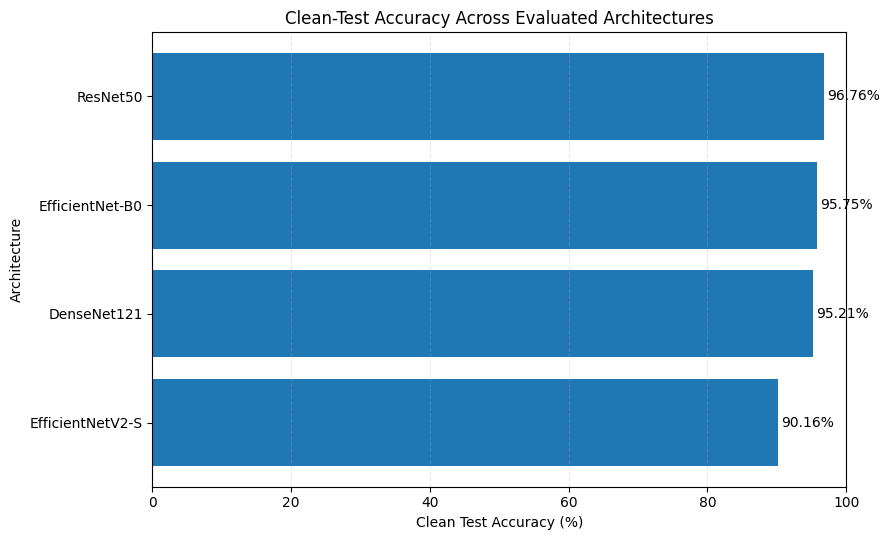


Figure saved:
/kaggle/working/architecture_comparison/figures/architecture_comparison_clean_accuracy.png

FIGURE 1 COMPLETE — NO TRAINING / NO INFERENCE


In [ ]:
# ==============================================================================
# CELL — PUBLICATION FIGURE 1: CLEAN TEST ACCURACY COMPARISON
# NO TRAINING / NO INFERENCE
# ==============================================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------------------------------
# Load saved architecture comparison results
# --------------------------------------------------------------------------

comparison_path = "/kaggle/working/architecture_comparison/artifacts/final_architecture_comparison.csv"

# If the artifact is stored elsewhere, search for it automatically
if not os.path.exists(comparison_path):
    matches = []

    for root, dirs, files in os.walk("/kaggle/working"):
        for file in files:
            if file == "final_architecture_comparison.csv":
                matches.append(os.path.join(root, file))

    if len(matches) == 0:
        raise FileNotFoundError(
            "final_architecture_comparison.csv was not found in /kaggle/working"
        )

    comparison_path = matches[0]

comparison_df = pd.read_csv(comparison_path)

print("=" * 90)
print("CLEAN TEST ACCURACY COMPARISON")
print("=" * 90)

display(
    comparison_df[
        ["model", "clean_accuracy", "clean_macro_f1"]
    ].sort_values("clean_accuracy", ascending=False)
)

# --------------------------------------------------------------------------
# Publication-quality figure
# --------------------------------------------------------------------------

figure_dir = "/kaggle/working/architecture_comparison/figures"
os.makedirs(figure_dir, exist_ok=True)

plot_df = comparison_df.copy()
plot_df = plot_df.sort_values("clean_accuracy", ascending=True)

plt.figure(figsize=(9, 5.5))

bars = plt.barh(
    plot_df["model"],
    plot_df["clean_accuracy"] * 100
)

plt.xlabel("Clean Test Accuracy (%)")
plt.ylabel("Architecture")
plt.title("Clean-Test Accuracy Across Evaluated Architectures")

plt.xlim(0, 100)
plt.grid(axis="x", linestyle="--", alpha=0.3)

for bar, value in zip(bars, plot_df["clean_accuracy"] * 100):
    plt.text(
        value + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontsize=10
    )

plt.tight_layout()

figure_path = os.path.join(
    figure_dir,
    "architecture_comparison_clean_accuracy.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFigure saved:")
print(figure_path)

print("\n" + "=" * 90)
print("FIGURE 1 COMPLETE — NO TRAINING / NO INFERENCE")
print("=" * 90)

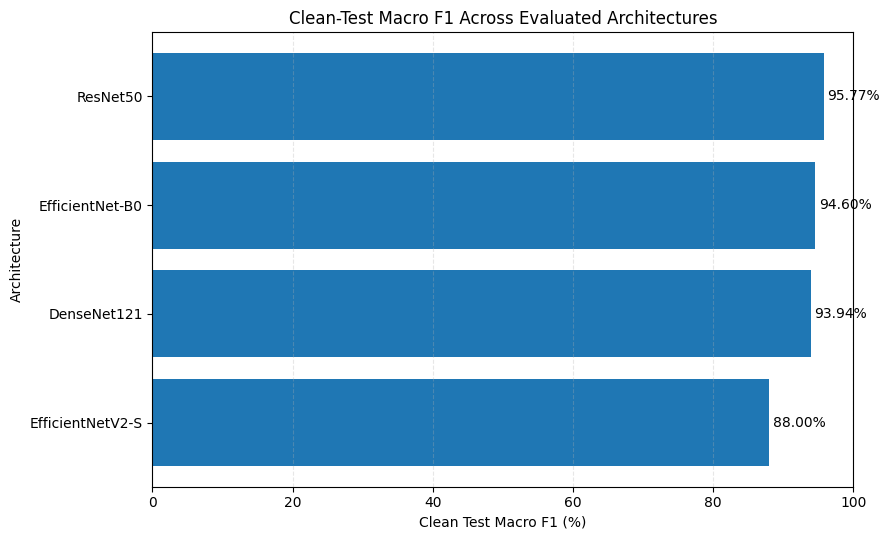

FIGURE 2 COMPLETE — NO TRAINING / NO INFERENCE
Saved: /kaggle/working/architecture_comparison/figures/architecture_comparison_clean_macro_f1.png


In [ ]:
# ==============================================================================
# CELL — PUBLICATION FIGURE 2: CLEAN TEST MACRO F1 COMPARISON
# NO TRAINING / NO INFERENCE
# ==============================================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------------------------------
# Load saved comparison results
# --------------------------------------------------------------------------

comparison_path = "/kaggle/working/architecture_comparison/artifacts/final_architecture_comparison.csv"

if not os.path.exists(comparison_path):
    matches = []

    for root, dirs, files in os.walk("/kaggle/working"):
        for file in files:
            if file == "final_architecture_comparison.csv":
                matches.append(os.path.join(root, file))

    if len(matches) == 0:
        raise FileNotFoundError(
            "final_architecture_comparison.csv was not found."
        )

    comparison_path = matches[0]

comparison_df = pd.read_csv(comparison_path)

# --------------------------------------------------------------------------
# Prepare data
# --------------------------------------------------------------------------

plot_df = comparison_df.copy()
plot_df = plot_df.sort_values("clean_macro_f1", ascending=True)

# --------------------------------------------------------------------------
# Create figure
# --------------------------------------------------------------------------

figure_dir = "/kaggle/working/architecture_comparison/figures"
os.makedirs(figure_dir, exist_ok=True)

plt.figure(figsize=(9, 5.5))

bars = plt.barh(
    plot_df["model"],
    plot_df["clean_macro_f1"] * 100
)

plt.xlabel("Clean Test Macro F1 (%)")
plt.ylabel("Architecture")
plt.title("Clean-Test Macro F1 Across Evaluated Architectures")

plt.xlim(0, 100)
plt.grid(axis="x", linestyle="--", alpha=0.3)

for bar, value in zip(
    bars,
    plot_df["clean_macro_f1"] * 100
):
    plt.text(
        value + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontsize=10
    )

plt.tight_layout()

figure_path = os.path.join(
    figure_dir,
    "architecture_comparison_clean_macro_f1.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=" * 90)
print("FIGURE 2 COMPLETE — NO TRAINING / NO INFERENCE")
print("=" * 90)
print(f"Saved: {figure_path}")

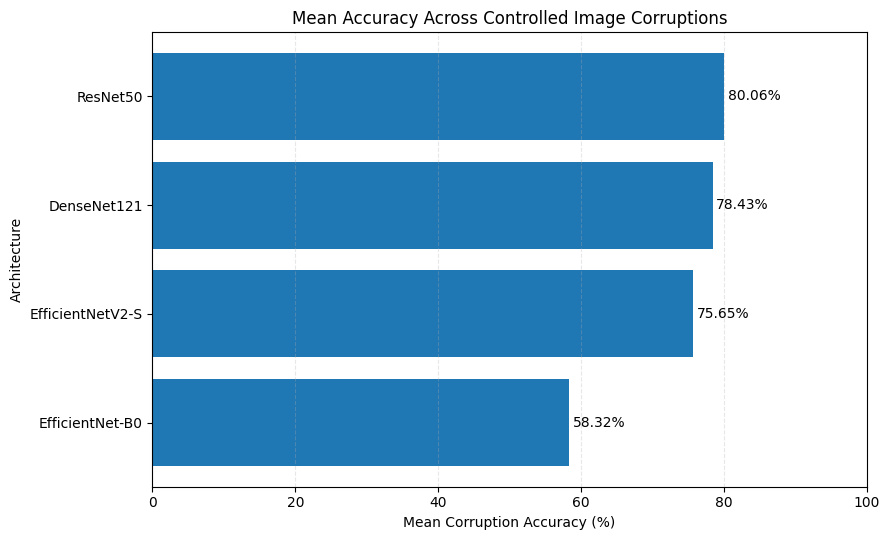

FIGURE 3 COMPLETE — NO TRAINING / NO INFERENCE
Saved: /kaggle/working/architecture_comparison/figures/architecture_comparison_mean_corruption_accuracy.png


In [ ]:
# ==============================================================================
# CELL — PUBLICATION FIGURE 3: MEAN CORRUPTION ACCURACY COMPARISON
# NO TRAINING / NO INFERENCE
# ==============================================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

comparison_path = "/kaggle/working/architecture_comparison/artifacts/final_architecture_comparison.csv"

if not os.path.exists(comparison_path):
    matches = []
    for root, dirs, files in os.walk("/kaggle/working"):
        for file in files:
            if file == "final_architecture_comparison.csv":
                matches.append(os.path.join(root, file))

    if not matches:
        raise FileNotFoundError(
            "final_architecture_comparison.csv was not found."
        )

    comparison_path = matches[0]

comparison_df = pd.read_csv(comparison_path)

# --------------------------------------------------------------------------
# Prepare data
# --------------------------------------------------------------------------

plot_df = comparison_df.copy()
plot_df = plot_df.sort_values(
    "mean_corruption_accuracy",
    ascending=True
)

# --------------------------------------------------------------------------
# Create figure
# --------------------------------------------------------------------------

figure_dir = "/kaggle/working/architecture_comparison/figures"
os.makedirs(figure_dir, exist_ok=True)

plt.figure(figsize=(9, 5.5))

bars = plt.barh(
    plot_df["model"],
    plot_df["mean_corruption_accuracy"] * 100
)

plt.xlabel("Mean Corruption Accuracy (%)")
plt.ylabel("Architecture")
plt.title("Mean Accuracy Across Controlled Image Corruptions")

plt.xlim(0, 100)
plt.grid(axis="x", linestyle="--", alpha=0.3)

for bar, value in zip(
    bars,
    plot_df["mean_corruption_accuracy"] * 100
):
    plt.text(
        value + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontsize=10
    )

plt.tight_layout()

figure_path = os.path.join(
    figure_dir,
    "architecture_comparison_mean_corruption_accuracy.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=" * 90)
print("FIGURE 3 COMPLETE — NO TRAINING / NO INFERENCE")
print("=" * 90)
print(f"Saved: {figure_path}")

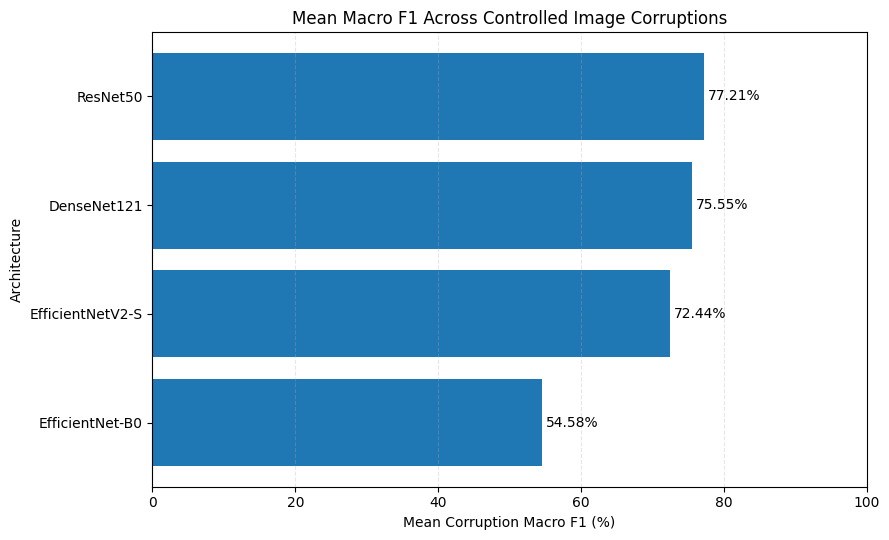

FIGURE 4 COMPLETE — NO TRAINING / NO INFERENCE
Saved: /kaggle/working/architecture_comparison/figures/architecture_comparison_mean_corruption_macro_f1.png


In [ ]:
# ==============================================================================
# CELL — PUBLICATION FIGURE 4: MEAN CORRUPTION MACRO F1 COMPARISON
# NO TRAINING / NO INFERENCE
# ==============================================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

comparison_path = "/kaggle/working/architecture_comparison/artifacts/final_architecture_comparison.csv"

if not os.path.exists(comparison_path):
    matches = []
    for root, dirs, files in os.walk("/kaggle/working"):
        for file in files:
            if file == "final_architecture_comparison.csv":
                matches.append(os.path.join(root, file))

    if not matches:
        raise FileNotFoundError(
            "final_architecture_comparison.csv was not found."
        )

    comparison_path = matches[0]

comparison_df = pd.read_csv(comparison_path)

# --------------------------------------------------------------------------
# Prepare data
# --------------------------------------------------------------------------

plot_df = comparison_df.copy()
plot_df = plot_df.sort_values(
    "mean_corruption_macro_f1",
    ascending=True
)

# --------------------------------------------------------------------------
# Create figure
# --------------------------------------------------------------------------

figure_dir = "/kaggle/working/architecture_comparison/figures"
os.makedirs(figure_dir, exist_ok=True)

plt.figure(figsize=(9, 5.5))

bars = plt.barh(
    plot_df["model"],
    plot_df["mean_corruption_macro_f1"] * 100
)

plt.xlabel("Mean Corruption Macro F1 (%)")
plt.ylabel("Architecture")
plt.title("Mean Macro F1 Across Controlled Image Corruptions")

plt.xlim(0, 100)
plt.grid(axis="x", linestyle="--", alpha=0.3)

for bar, value in zip(
    bars,
    plot_df["mean_corruption_macro_f1"] * 100
):
    plt.text(
        value + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontsize=10
    )

plt.tight_layout()

figure_path = os.path.join(
    figure_dir,
    "architecture_comparison_mean_corruption_macro_f1.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=" * 90)
print("FIGURE 4 COMPLETE — NO TRAINING / NO INFERENCE")
print("=" * 90)
print(f"Saved: {figure_path}")

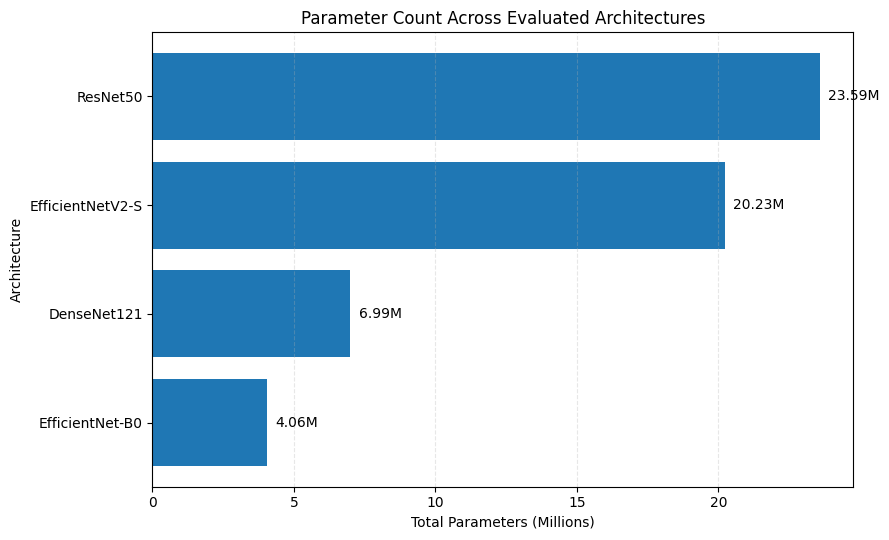

FIGURE 5 COMPLETE — NO TRAINING / NO INFERENCE
Saved: /kaggle/working/architecture_comparison/figures/architecture_comparison_parameter_count.png


In [ ]:
# ==============================================================================
# CELL — PUBLICATION FIGURE 5: MODEL PARAMETER COMPARISON
# NO TRAINING / NO INFERENCE
# ==============================================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

comparison_path = "/kaggle/working/architecture_comparison/artifacts/final_architecture_comparison.csv"

if not os.path.exists(comparison_path):
    matches = []
    for root, dirs, files in os.walk("/kaggle/working"):
        for file in files:
            if file == "final_architecture_comparison.csv":
                matches.append(os.path.join(root, file))

    if not matches:
        raise FileNotFoundError(
            "final_architecture_comparison.csv was not found."
        )

    comparison_path = matches[0]

comparison_df = pd.read_csv(comparison_path)

# --------------------------------------------------------------------------
# Prepare data
# --------------------------------------------------------------------------

plot_df = comparison_df.copy()
plot_df = plot_df.sort_values("total_params_M", ascending=True)

figure_dir = "/kaggle/working/architecture_comparison/figures"
os.makedirs(figure_dir, exist_ok=True)

# --------------------------------------------------------------------------
# Create figure
# --------------------------------------------------------------------------

plt.figure(figsize=(9, 5.5))

bars = plt.barh(
    plot_df["model"],
    plot_df["total_params_M"]
)

plt.xlabel("Total Parameters (Millions)")
plt.ylabel("Architecture")
plt.title("Parameter Count Across Evaluated Architectures")

plt.grid(axis="x", linestyle="--", alpha=0.3)

for bar, value in zip(
    bars,
    plot_df["total_params_M"]
):
    plt.text(
        value + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}M",
        va="center",
        fontsize=10
    )

plt.tight_layout()

figure_path = os.path.join(
    figure_dir,
    "architecture_comparison_parameter_count.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=" * 90)
print("FIGURE 5 COMPLETE — NO TRAINING / NO INFERENCE")
print("=" * 90)
print(f"Saved: {figure_path}")

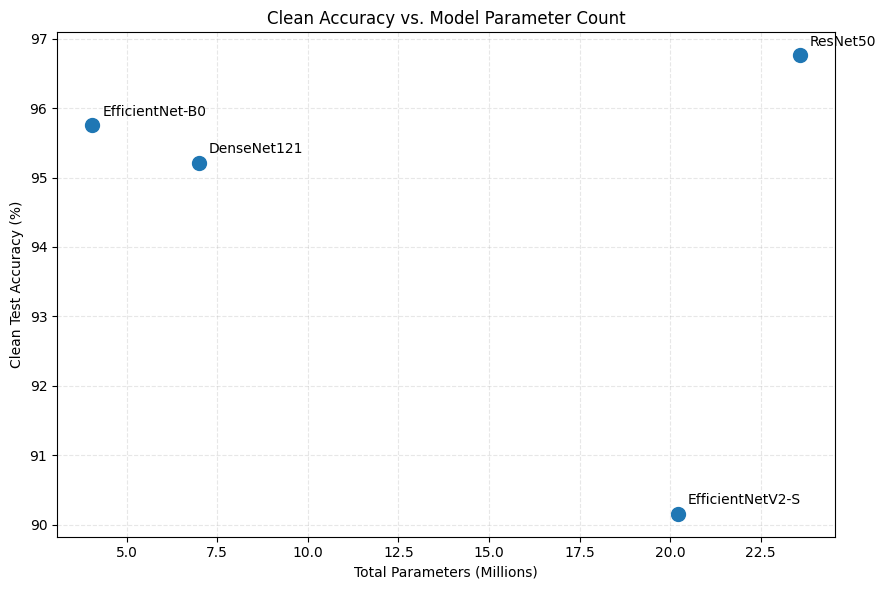

FIGURE 6 COMPLETE — NO TRAINING / NO INFERENCE
Saved: /kaggle/working/architecture_comparison/figures/architecture_comparison_accuracy_vs_parameters.png


In [ ]:
# ==============================================================================
# CELL — PUBLICATION FIGURE 6: ACCURACY VS PARAMETER COUNT
# NO TRAINING / NO INFERENCE
# ==============================================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

comparison_path = "/kaggle/working/architecture_comparison/artifacts/final_architecture_comparison.csv"

if not os.path.exists(comparison_path):
    matches = []
    for root, dirs, files in os.walk("/kaggle/working"):
        for file in files:
            if file == "final_architecture_comparison.csv":
                matches.append(os.path.join(root, file))

    if not matches:
        raise FileNotFoundError(
            "final_architecture_comparison.csv was not found."
        )

    comparison_path = matches[0]

comparison_df = pd.read_csv(comparison_path)

# --------------------------------------------------------------------------
# Create figure
# --------------------------------------------------------------------------

figure_dir = "/kaggle/working/architecture_comparison/figures"
os.makedirs(figure_dir, exist_ok=True)

plt.figure(figsize=(9, 6))

plt.scatter(
    comparison_df["total_params_M"],
    comparison_df["clean_accuracy"] * 100,
    s=100
)

for _, row in comparison_df.iterrows():
    plt.annotate(
        row["model"],
        (
            row["total_params_M"],
            row["clean_accuracy"] * 100
        ),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=10
    )

plt.xlabel("Total Parameters (Millions)")
plt.ylabel("Clean Test Accuracy (%)")
plt.title("Clean Accuracy vs. Model Parameter Count")

plt.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()

figure_path = os.path.join(
    figure_dir,
    "architecture_comparison_accuracy_vs_parameters.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=" * 90)
print("FIGURE 6 COMPLETE — NO TRAINING / NO INFERENCE")
print("=" * 90)
print(f"Saved: {figure_path}")

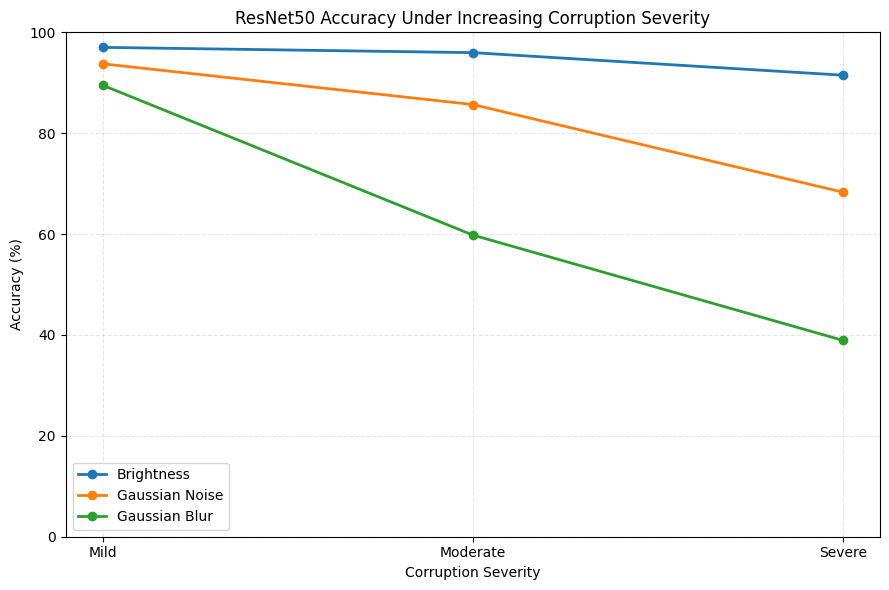

FIGURE 7 COMPLETE — NO TRAINING / NO INFERENCE
Saved: /kaggle/working/architecture_comparison/figures/resnet50_corruption_severity_accuracy.png


In [ ]:
# ==============================================================================
# CELL — PUBLICATION FIGURE 7: RESNET50 CORRUPTION SEVERITY CURVES
# NO TRAINING / NO INFERENCE
# ==============================================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------------------------------
# Locate saved ResNet50 robustness results
# --------------------------------------------------------------------------

robustness_path = (
    "/kaggle/working/architecture_comparison/artifacts/"
    "resnet50_robustness_results.csv"
)

if not os.path.exists(robustness_path):
    matches = []

    for root, dirs, files in os.walk("/kaggle/working"):
        for file in files:
            if file == "resnet50_robustness_results.csv":
                matches.append(os.path.join(root, file))

    if not matches:
        raise FileNotFoundError(
            "resnet50_robustness_results.csv was not found."
        )

    robustness_path = matches[0]

df = pd.read_csv(robustness_path)

# --------------------------------------------------------------------------
# Convert severity to ordered numeric values
# --------------------------------------------------------------------------

severity_order = {
    "mild": 1,
    "moderate": 2,
    "severe": 3
}

df["severity_level"] = df["severity"].map(severity_order)

# --------------------------------------------------------------------------
# Create one publication figure containing all three corruption types
# --------------------------------------------------------------------------

figure_dir = "/kaggle/working/architecture_comparison/figures"
os.makedirs(figure_dir, exist_ok=True)

plt.figure(figsize=(9, 6))

corruptions = [
    "brightness",
    "gaussian_noise",
    "gaussian_blur"
]

for corruption in corruptions:

    subset = df[df["corruption"] == corruption].sort_values(
        "severity_level"
    )

    if subset.empty:
        continue

    plt.plot(
        subset["severity_level"],
        subset["accuracy"] * 100,
        marker="o",
        linewidth=2,
        label=corruption.replace("_", " ").title()
    )

plt.xticks(
    [1, 2, 3],
    ["Mild", "Moderate", "Severe"]
)

plt.xlabel("Corruption Severity")
plt.ylabel("Accuracy (%)")
plt.title("ResNet50 Accuracy Under Increasing Corruption Severity")

plt.ylim(0, 100)
plt.grid(True, linestyle="--", alpha=0.3)
plt.legend()

plt.tight_layout()

figure_path = os.path.join(
    figure_dir,
    "resnet50_corruption_severity_accuracy.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=" * 90)
print("FIGURE 7 COMPLETE — NO TRAINING / NO INFERENCE")
print("=" * 90)
print(f"Saved: {figure_path}")

In [ ]:
# ====================================================================================================
# CELL — ROBUST IMAGE PATH RESOLUTION
# Fixes duplicated path prefixes + known filename extension spacing issues
# NO DATASET FILES ARE MODIFIED
# ====================================================================================================

import os
import re
from pathlib import Path

print("=" * 100)
print("ROBUST IMAGE PATH RESOLUTION")
print("=" * 100)

# ------------------------------------------------------------------------------------------
# 1. BUILD A COMPLETE FILENAME INDEX ONCE
# ------------------------------------------------------------------------------------------

print("\nIndexing PlantVillage RGB images...")

filename_to_path = {}
normalized_filename_to_path = {}

image_extensions = {".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"}

for root, dirs, files in os.walk(RGB_ROOT):
    for fname in files:
        if Path(fname).suffix in image_extensions:
            full_path = os.path.join(root, fname)

            # Exact filename
            if fname not in filename_to_path:
                filename_to_path[fname] = full_path

            # Normalized filename:
            # removes whitespace immediately before extension
            normalized = re.sub(r"\s+(\.[^.]+)$", r"\1", fname)

            if normalized not in normalized_filename_to_path:
                normalized_filename_to_path[normalized] = full_path

print(f"Indexed images                 : {len(filename_to_path):,}")

# ------------------------------------------------------------------------------------------
# 2. ROBUST RESOLVER
# ------------------------------------------------------------------------------------------

def resolve_existing_image_path(path):
    """
    Resolve an image path without modifying the dataset.

    Resolution order:
      1. Exact path
      2. Remove whitespace before file extension
      3. Use basename against indexed RGB dataset
      4. Use normalized basename against indexed dataset
    """

    path = os.path.normpath(str(path))

    # ------------------------------------------------------------------
    # A. Exact path
    # ------------------------------------------------------------------
    if os.path.isfile(path):
        return path, "exact"

    # ------------------------------------------------------------------
    # B. Remove whitespace before extension
    # ------------------------------------------------------------------
    corrected_path = re.sub(
        r"\s+(\.[^.]+)$",
        r"\1",
        path
    )

    if os.path.isfile(corrected_path):
        return corrected_path, "extension_spacing"

    # ------------------------------------------------------------------
    # C. Match using filename only
    # ------------------------------------------------------------------
    basename = os.path.basename(path)

    if basename in filename_to_path:
        return filename_to_path[basename], "filename_index"

    # ------------------------------------------------------------------
    # D. Match normalized filename
    # ------------------------------------------------------------------
    normalized_basename = re.sub(
        r"\s+(\.[^.]+)$",
        r"\1",
        basename
    )

    if normalized_basename in normalized_filename_to_path:
        return (
            normalized_filename_to_path[normalized_basename],
            "normalized_filename"
        )

    # ------------------------------------------------------------------
    # E. Explicitly try removing duplicated raw/color prefix
    # ------------------------------------------------------------------
    marker = os.sep + "raw" + os.sep + "color" + os.sep

    if marker in path:
        simplified = path.replace(marker, os.sep, 1)

        if os.path.isfile(simplified):
            return simplified, "duplicate_raw_color_prefix"

        simplified_corrected = re.sub(
            r"\s+(\.[^.]+)$",
            r"\1",
            simplified
        )

        if os.path.isfile(simplified_corrected):
            return simplified_corrected, "duplicate_prefix_and_extension_spacing"

    # ------------------------------------------------------------------
    # F. Try class-folder + filename directly from RGB_ROOT
    # ------------------------------------------------------------------
    parent_folder = os.path.basename(os.path.dirname(path))

    candidate = os.path.join(
        RGB_ROOT,
        parent_folder,
        basename
    )

    if os.path.isfile(candidate):
        return candidate, "rgb_root_reconstruction"

    candidate_corrected = re.sub(
        r"\s+(\.[^.]+)$",
        r"\1",
        candidate
    )

    if os.path.isfile(candidate_corrected):
        return candidate_corrected, "rgb_root_reconstruction_spacing"

    raise FileNotFoundError(
        f"Unable to resolve image:\n{path}"
    )


# ------------------------------------------------------------------------------------------
# 3. APPLY TO DATAFRAMES
# ------------------------------------------------------------------------------------------

def resolve_dataframe_paths(dataframe):
    dataframe = dataframe.copy()

    resolved_paths = []
    correction_types = []

    for path in dataframe["path"]:
        resolved_path, correction_type = resolve_existing_image_path(path)

        resolved_paths.append(resolved_path)
        correction_types.append(correction_type)

    dataframe["path"] = resolved_paths

    return dataframe, correction_types


# ------------------------------------------------------------------------------------------
# 4. RESOLVE ALL THREE SPLITS
# ------------------------------------------------------------------------------------------

train_df, train_corrections = resolve_dataframe_paths(train_df)
val_df, val_corrections = resolve_dataframe_paths(val_df)
test_df, test_corrections = resolve_dataframe_paths(test_df)


# ------------------------------------------------------------------------------------------
# 5. AUDIT RESULTS
# ------------------------------------------------------------------------------------------

all_corrections = (
    train_corrections
    + val_corrections
    + test_corrections
)

from collections import Counter

correction_counts = Counter(all_corrections)

print("\n" + "-" * 100)
print("PATH RESOLUTION AUDIT")
print("-" * 100)

print(f"Train images resolved : {len(train_df):,}")
print(f"Val images resolved   : {len(val_df):,}")
print(f"Test images resolved  : {len(test_df):,}")
print(f"Total resolved        : {len(train_df) + len(val_df) + len(test_df):,}")

print("\nResolution methods:")

for method, count in sorted(correction_counts.items()):
    print(f"  {method:<45}: {count:,}")

# ------------------------------------------------------------------------------------------
# 6. VERIFY EVERY PATH REALLY EXISTS
# ------------------------------------------------------------------------------------------

missing_train = [p for p in train_df["path"] if not os.path.isfile(p)]
missing_val = [p for p in val_df["path"] if not os.path.isfile(p)]
missing_test = [p for p in test_df["path"] if not os.path.isfile(p)]

total_missing = (
    len(missing_train)
    + len(missing_val)
    + len(missing_test)
)

print("\n" + "-" * 100)
print("FINAL EXISTENCE CHECK")
print("-" * 100)

print(f"Missing train : {len(missing_train)}")
print(f"Missing val   : {len(missing_val)}")
print(f"Missing test  : {len(missing_test)}")
print(f"Total missing : {total_missing}")

assert total_missing == 0, (
    f"Path resolution failed: {total_missing} images remain missing."
)

# ------------------------------------------------------------------------------------------
# 7. VERIFY SPLIT COUNTS
# ------------------------------------------------------------------------------------------

assert len(train_df) == 39207
assert len(val_df) == 4389
assert len(test_df) == 10709

print("\nSplit counts verified:")
print("  Train      : 39,207")
print("  Validation : 4,389")
print("  Test       : 10,709")

print("\n" + "=" * 100)
print("PATH RESOLUTION: PASS")
print("No dataset files were modified.")
print("All 54,305 images are resolvable.")
print("=" * 100)

ROBUST IMAGE PATH RESOLUTION

Indexing PlantVillage RGB images...
Indexed images                 : 54,305

----------------------------------------------------------------------------------------------------
PATH RESOLUTION AUDIT
----------------------------------------------------------------------------------------------------
Train images resolved : 39,207
Val images resolved   : 4,389
Test images resolved  : 10,709
Total resolved        : 54,305

Resolution methods:
  filename_index                               : 54,299
  normalized_filename                          : 6

----------------------------------------------------------------------------------------------------
FINAL EXISTENCE CHECK
----------------------------------------------------------------------------------------------------
Missing train : 0
Missing val   : 0
Missing test  : 0
Total missing : 0

Split counts verified:
  Train      : 39,207
  Validation : 4,389
  Test       : 10,709

PATH RESOLUTION: PASS
No datase

In [ ]:
import os

matches = []

for root, dirs, files in os.walk("/kaggle/working"):
    for file in files:
        if (
            "A3" in root
            or "brightness" in root.lower()
            or file.endswith(".pth")
        ):
            matches.append(
                os.path.join(root, file)
            )

print("=" * 100)
print("A3 / CHECKPOINT SEARCH")
print("=" * 100)

if matches:
    for path in matches:
        print(path)
else:
    print("No A3 checkpoint found in /kaggle/working.")

print("=" * 100)

A3 / CHECKPOINT SEARCH
No A3 checkpoint found in /kaggle/working.


In [ ]:
# ====================================================================================================
# A3 — COMPLETE ENVIRONMENT RECOVERY
# RESNET50 + BRIGHTNESS ONLY
#
# This cell reconstructs EVERYTHING after a Kaggle runtime disconnect:
#   1. Imports
#   2. Reproducibility
#   3. Device
#   4. Dataset paths
#   5. Exact PlantVillage split
#   6. Safe filename resolver
#   7. DataFrames
#   8. Dataset class
#   9. Image transforms
#  10. Brightness corruption
#  11. DataLoaders
#  12. ResNet50 model configuration
#  13. Loss / optimizer configuration
#  14. A3 directories
#  15. Verification of all components
#
# NO TRAINING IS PERFORMED IN THIS CELL.
# ====================================================================================================

# ==========================================================================================
# 1. IMPORTS
# ==========================================================================================

import os
import re
import io
import json
import time
import random
import shutil

import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

from torchvision import transforms, models

from PIL import Image, ImageEnhance, ImageFilter

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

# ==========================================================================================
# 2. REPRODUCIBILITY
# ==========================================================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Deterministic behavior where possible
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ==========================================================================================
# 3. DEVICE
# ==========================================================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ==========================================================================================
# 4. CORE CONFIGURATION
# ==========================================================================================

NUM_CLASSES = 38

IMAGE_SIZE = 224

BATCH_SIZE = 32

NUM_WORKERS = 2

LEARNING_RATE = 0.001

WEIGHT_DECAY = 0.0001

MAX_EPOCHS = 10

PATIENCE = 3

# ==========================================================================================
# 5. A3 CONFIGURATION
# ==========================================================================================

ABLATION_NAME = "A3_resnet50_brightness"

ABLATION_PROBABILITY = 0.5

BRIGHTNESS_MIN = 0.65

BRIGHTNESS_MAX = 1.35

# ==========================================================================================
# 6. KAGGLE DATASET PATHS
# ==========================================================================================

PLANTVILLAGE_ROOT = (
    "/kaggle/input/datasets/"
    "mahmudnadim/robust-crop-disease-plantvillage"
)

SPLIT_ROOT = (
    "/kaggle/input/datasets/"
    "mahmudnadim/robust-crop-disease-splits/"
    "splits-20260929T040001Z-1-001/splits"
)

RGB_ROOT = os.path.join(
    PLANTVILLAGE_ROOT,
    "color"
)

TRAIN_SPLIT_FILE = os.path.join(
    SPLIT_ROOT,
    "color_train.txt"
)

TEST_SPLIT_FILE = os.path.join(
    SPLIT_ROOT,
    "color_test.txt"
)

TRAIN_VAL_NPZ = (
    "/kaggle/input/datasets/"
    "mahmudnadim/robust-crop-disease-splits/"
    "train_validation_split.npz"
)

# ==========================================================================================
# 7. A3 OUTPUT DIRECTORIES
# ==========================================================================================

ABLATION_DIR = (
    "/kaggle/working/architecture_comparison/"
    "ablation_studies/A3_resnet50_brightness"
)

CHECKPOINT_DIR = os.path.join(
    ABLATION_DIR,
    "checkpoints"
)

RESULTS_DIR = os.path.join(
    ABLATION_DIR,
    "results"
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

BEST_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "best_model.pth"
)

LATEST_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "latest_checkpoint.pth"
)

# ==========================================================================================
# 8. VERIFY INPUT PATHS
# ==========================================================================================

required_paths = {
    "PlantVillage root": PLANTVILLAGE_ROOT,
    "RGB root": RGB_ROOT,
    "Split root": SPLIT_ROOT,
    "Train split": TRAIN_SPLIT_FILE,
    "Test split": TEST_SPLIT_FILE,
    "Train/validation NPZ": TRAIN_VAL_NPZ
}

print("=" * 100)
print("A3 — COMPLETE ENVIRONMENT RECOVERY")
print("=" * 100)

print("\nINPUT PATH VERIFICATION")

for name, path in required_paths.items():

    exists = os.path.exists(path)

    print(
        f"{name:25s}: "
        f"{'FOUND' if exists else 'MISSING'}"
    )

    assert exists, f"Required path missing: {path}"

# ==========================================================================================
# 9. EXACT CLASS LIST
# ==========================================================================================

CLASS_NAMES = [
    "Apple___Apple_scab",
    "Apple___Black_rot",
    "Apple___Cedar_apple_rust",
    "Apple___healthy",
    "Blueberry___healthy",
    "Cherry_(including_sour)___Powdery_mildew",
    "Cherry_(including_sour)___healthy",
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn_(maize)___Common_rust_",
    "Corn_(maize)___Northern_Leaf_Blight",
    "Corn_(maize)___healthy",
    "Grape___Black_rot",
    "Grape___Esca_(Black_Measles)",
    "Grape___Leaf_blight_(Isariopsis_Leaf_Spot)",
    "Grape___healthy",
    "Orange___Haunglongbing_(Citrus_greening)",
    "Peach___Bacterial_spot",
    "Peach___healthy",
    "Pepper,_bell___Bacterial_spot",
    "Pepper,_bell___healthy",
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy",
    "Raspberry___healthy",
    "Soybean___healthy",
    "Squash___Powdery_mildew",
    "Strawberry___Leaf_scorch",
    "Strawberry___healthy",
    "Tomato___Bacterial_spot",
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___Leaf_Mold",
    "Tomato___Septoria_leaf_spot",
    "Tomato___Spider_mites Two-spotted_spider_mite",
    "Tomato___Target_Spot",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato___Tomato_mosaic_virus",
    "Tomato___healthy"
]

assert len(CLASS_NAMES) == NUM_CLASSES

CLASS_TO_IDX = {
    name: idx
    for idx, name in enumerate(CLASS_NAMES)
}

IDX_TO_CLASS = {
    idx: name
    for name, idx in CLASS_TO_IDX.items()
}

# ==========================================================================================
# 10. READ OFFICIAL SPLITS
# ==========================================================================================

with open(
    TRAIN_SPLIT_FILE,
    "r",
    encoding="utf-8"
) as f:

    official_train_paths = [
        line.strip()
        for line in f
        if line.strip()
    ]

with open(
    TEST_SPLIT_FILE,
    "r",
    encoding="utf-8"
) as f:

    official_test_paths = [
        line.strip()
        for line in f
        if line.strip()
    ]

assert len(official_train_paths) == 43_596
assert len(official_test_paths) == 10_709

# ==========================================================================================
# 11. TRAIN / VALIDATION SPLIT
# ==========================================================================================

split_data = np.load(
    TRAIN_VAL_NPZ
)

train_idx = split_data["train_idx"]
val_idx = split_data["val_idx"]

assert len(train_idx) == 39_207
assert len(val_idx) == 4_389

# ==========================================================================================
# 12. PATH RESOLUTION
# ==========================================================================================

def normalize_split_path(split_path):

    """
    Convert PlantVillage split entry into
    the corresponding local RGB path.
    """

    split_path = split_path.replace(
        "\\",
        "/"
    )

    filename = os.path.basename(
        split_path
    )

    class_name = os.path.basename(
        os.path.dirname(split_path)
    )

    return os.path.join(
        RGB_ROOT,
        class_name,
        filename
    )


def resolve_existing_image_path(image_path):

    """
    Non-destructive resolver.

    The PlantVillage upload contains exactly six filenames
    where a space appears immediately before the extension.
    We correct those paths in memory only.
    """

    if os.path.exists(image_path):

        return image_path

    corrected_path = re.sub(
        r"\s+(\.[^.]+)$",
        r"\1",
        image_path
    )

    if os.path.exists(corrected_path):

        return corrected_path

    raise FileNotFoundError(
        f"Image not found: {image_path}"
    )


# ==========================================================================================
# 13. BUILD FULL DATAFRAME
# ==========================================================================================

records = []

for split_position, split_path in enumerate(
    official_train_paths
):

    raw_path = normalize_split_path(
        split_path
    )

    resolved_path = resolve_existing_image_path(
        raw_path
    )

    class_name = os.path.basename(
        os.path.dirname(resolved_path)
    )

    assert class_name in CLASS_TO_IDX

    records.append(
        {
            "path": resolved_path,
            "class_name": class_name,
            "label": CLASS_TO_IDX[class_name],
            "official_train_position": split_position
        }
    )

official_train_df = pd.DataFrame(
    records
)

assert len(official_train_df) == 43_596

# ------------------------------------------------------------------------------------------
# Official test
# ------------------------------------------------------------------------------------------

records = []

for split_position, split_path in enumerate(
    official_test_paths
):

    raw_path = normalize_split_path(
        split_path
    )

    resolved_path = resolve_existing_image_path(
        raw_path
    )

    class_name = os.path.basename(
        os.path.dirname(resolved_path)
    )

    assert class_name in CLASS_TO_IDX

    records.append(
        {
            "path": resolved_path,
            "class_name": class_name,
            "label": CLASS_TO_IDX[class_name],
            "official_test_position": split_position
        }
    )

test_df = pd.DataFrame(
    records
)

assert len(test_df) == 10_709

# ==========================================================================================
# 14. DERIVE EXACT TRAIN / VALIDATION DATAFRAMES
# ==========================================================================================

train_df = official_train_df.iloc[
    train_idx
].reset_index(drop=True)

val_df = official_train_df.iloc[
    val_idx
].reset_index(drop=True)

test_df = test_df.reset_index(
    drop=True
)

assert len(train_df) == 39_207
assert len(val_df) == 4_389
assert len(test_df) == 10_709

# ==========================================================================================
# 15. DATASET CLASS
# ==========================================================================================

class PlantVillageDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.dataframe = (
            dataframe
            .reset_index(drop=True)
        )

        self.transform = transform

    def __len__(self):

        return len(
            self.dataframe
        )

    def __getitem__(self, index):

        row = self.dataframe.iloc[
            index
        ]

        image_path = row["path"]

        label = int(
            row["label"]
        )

        image = Image.open(
            image_path
        ).convert("RGB")

        if self.transform is not None:

            image = self.transform(
                image
            )

        return image, label


# ==========================================================================================
# 16. IMAGENET NORMALIZATION
# ==========================================================================================

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]

# ==========================================================================================
# 17. A3 BRIGHTNESS CORRUPTION
# ==========================================================================================

def ablation_brightness_only(
    image
):

    if random.random() < ABLATION_PROBABILITY:

        factor = random.uniform(
            BRIGHTNESS_MIN,
            BRIGHTNESS_MAX
        )

        image = ImageEnhance.Brightness(
            image
        ).enhance(
            factor
        )

    return image


# ==========================================================================================
# 18. TRAINING TRANSFORM
# ==========================================================================================

ablation_brightness_train_transform = transforms.Compose(
    [

        transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE)
        ),

        transforms.Lambda(
            ablation_brightness_only
        ),

        transforms.RandomHorizontalFlip(
            p=0.5
        ),

        transforms.RandomRotation(
            degrees=15
        ),

        transforms.ColorJitter(
            brightness=0.2,
            contrast=0.2,
            saturation=0.2,
            hue=0.05
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            IMAGENET_MEAN,
            IMAGENET_STD
        )
    ]
)

# ==========================================================================================
# 19. CLEAN EVALUATION TRANSFORM
# ==========================================================================================

ablation_brightness_eval_transform = transforms.Compose(
    [

        transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE)
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            IMAGENET_MEAN,
            IMAGENET_STD
        )
    ]
)

# ==========================================================================================
# 20. DATASETS
# ==========================================================================================

ablation_brightness_train_dataset = PlantVillageDataset(
    train_df,
    transform=ablation_brightness_train_transform
)

ablation_brightness_val_dataset = PlantVillageDataset(
    val_df,
    transform=ablation_brightness_eval_transform
)

ablation_brightness_test_dataset = PlantVillageDataset(
    test_df,
    transform=ablation_brightness_eval_transform
)

# ==========================================================================================
# 21. DATALOADERS
# ==========================================================================================

ablation_brightness_train_loader = DataLoader(
    ablation_brightness_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

ablation_brightness_val_loader = DataLoader(
    ablation_brightness_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

ablation_brightness_test_loader = DataLoader(
    ablation_brightness_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

# ==========================================================================================
# 22. MODEL BUILDER
# ==========================================================================================

def build_a3_resnet50():

    model = models.resnet50(
        weights=None
    )

    model.fc = nn.Linear(
        model.fc.in_features,
        NUM_CLASSES
    )

    # Freeze backbone
    for parameter in model.parameters():

        parameter.requires_grad = False

    # Train classifier only
    for parameter in model.fc.parameters():

        parameter.requires_grad = True

    return model


# ==========================================================================================
# 23. BUILD MODEL
# ==========================================================================================

model = build_a3_resnet50()

model = model.to(
    DEVICE
)

# ==========================================================================================
# 24. MODEL PARAMETERS
# ==========================================================================================

TOTAL_PARAMS = sum(
    p.numel()
    for p in model.parameters()
)

TRAINABLE_PARAMS = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

assert TOTAL_PARAMS == 23_585_894
assert TRAINABLE_PARAMS == 77_862

# ==========================================================================================
# 25. LOSS + OPTIMIZER
# ==========================================================================================

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ==========================================================================================
# 26. COMPLETE VERIFICATION
# ==========================================================================================

print("\n" + "=" * 100)
print("A3 ENVIRONMENT RECOVERY VERIFICATION")
print("=" * 100)

print(
    f"\nDevice                 : {DEVICE}"
)

if torch.cuda.is_available():

    print(
        f"GPU                    : "
        f"{torch.cuda.get_device_name(0)}"
    )

print(
    f"\nClasses                : "
    f"{NUM_CLASSES}"
)

print(
    f"Image size             : "
    f"{IMAGE_SIZE} x {IMAGE_SIZE}"
)

print(
    f"Batch size             : "
    f"{BATCH_SIZE}"
)

print(
    f"Maximum epochs         : "
    f"{MAX_EPOCHS}"
)

print(
    f"Patience               : "
    f"{PATIENCE}"
)

print(
    f"Learning rate          : "
    f"{LEARNING_RATE}"
)

print(
    f"Weight decay           : "
    f"{WEIGHT_DECAY}"
)

print(
    f"Brightness probability : "
    f"{ABLATION_PROBABILITY}"
)

print(
    f"Brightness range       : "
    f"{BRIGHTNESS_MIN} – "
    f"{BRIGHTNESS_MAX}"
)

print(
    f"\nDataset sizes:"
)

print(
    f"  Train               : "
    f"{len(ablation_brightness_train_dataset):,}"
)

print(
    f"  Validation          : "
    f"{len(ablation_brightness_val_dataset):,}"
)

print(
    f"  Test                : "
    f"{len(ablation_brightness_test_dataset):,}"
)

# ------------------------------------------------------------------------------------------
# Training batch
# ------------------------------------------------------------------------------------------

images, labels = next(
    iter(
        ablation_brightness_train_loader
    )
)

print(
    f"\nTraining batch:"
)

print(
    f"  Image shape         : "
    f"{tuple(images.shape)}"
)

print(
    f"  Image dtype         : "
    f"{images.dtype}"
)

print(
    f"  Label shape         : "
    f"{tuple(labels.shape)}"
)

print(
    f"  Label dtype         : "
    f"{labels.dtype}"
)

print(
    f"  Label min           : "
    f"{labels.min().item()}"
)

print(
    f"  Label max           : "
    f"{labels.max().item()}"
)

# ------------------------------------------------------------------------------------------
# Forward pass
# ------------------------------------------------------------------------------------------

dummy_input = torch.randn(
    2,
    3,
    IMAGE_SIZE,
    IMAGE_SIZE,
    device=DEVICE
)

with torch.no_grad():

    dummy_output = model(
        dummy_input
    )

assert dummy_output.shape == (
    2,
    NUM_CLASSES
)

# ------------------------------------------------------------------------------------------
# Final assertions
# ------------------------------------------------------------------------------------------

assert len(train_df) == 39_207
assert len(val_df) == 4_389
assert len(test_df) == 10_709

assert images.shape == (
    BATCH_SIZE,
    3,
    IMAGE_SIZE,
    IMAGE_SIZE
)

assert labels.dtype == torch.int64

assert dummy_output.shape == (
    2,
    NUM_CLASSES
)

assert TOTAL_PARAMS == 23_585_894

assert TRAINABLE_PARAMS == 77_862

# Cleanup temporary tensors
del images
del labels
del dummy_input
del dummy_output

# ==========================================================================================
# FINAL STATUS
# ==========================================================================================

print("\n" + "=" * 100)
print("A3 COMPLETE ENVIRONMENT RECOVERY: PASS")
print("=" * 100)

print("\nRecovered:")
print("  ✓ All imports")
print("  ✓ Seed and reproducibility")
print("  ✓ CUDA / GPU configuration")
print("  ✓ PlantVillage paths")
print("  ✓ Exact official train/test split")
print("  ✓ Exact 39,207 / 4,389 train-validation split")
print("  ✓ Six filename corrections handled in memory")
print("  ✓ Dataset class")
print("  ✓ Brightness-only corruption")
print("  ✓ Training transform")
print("  ✓ Clean validation/test transform")
print("  ✓ All three datasets")
print("  ✓ All three dataloaders")
print("  ✓ ResNet50 architecture")
print("  ✓ Frozen-backbone configuration")
print("  ✓ Loss")
print("  ✓ AdamW optimizer")
print("  ✓ A3 directories")
print("  ✓ Model parameter verification")
print("  ✓ Forward-pass verification")

print("\nTraining performed: NO")
print("=" * 100)

A3 — COMPLETE ENVIRONMENT RECOVERY

INPUT PATH VERIFICATION
PlantVillage root        : FOUND
RGB root                 : FOUND
Split root               : FOUND
Train split              : FOUND
Test split               : FOUND
Train/validation NPZ     : FOUND

A3 ENVIRONMENT RECOVERY VERIFICATION

Device                 : cuda
GPU                    : Tesla T4

Classes                : 38
Image size             : 224 x 224
Batch size             : 32
Maximum epochs         : 10
Patience               : 3
Learning rate          : 0.001
Weight decay           : 0.0001
Brightness probability : 0.5
Brightness range       : 0.65 – 1.35

Dataset sizes:
  Train               : 39,207
  Validation          : 4,389
  Test                : 10,709

Training batch:
  Image shape         : (32, 3, 224, 224)
  Image dtype         : torch.float32
  Label shape         : (32,)
  Label dtype         : torch.int64
  Label min           : 3
  Label max           : 37

A3 COMPLETE ENVIRONMENT RECOVERY: PASS

In [ ]:
# ====================================================================================================
# ABLATION PROTOCOL FIX — VERIFY THE CORRECT RESNET50 BASELINE
#
# IMPORTANT:
# This cell does NOT train.
# It reconstructs the correct pretrained ResNet50 and verifies the protocol
# before we spend GPU time on A1/A2/A3/A4.
# ====================================================================================================

import os
import json
import random
import numpy as np
import torch
import torch.nn as nn
from torchvision import models

# ==========================================================================================
# 1. REPRODUCIBILITY
# ==========================================================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ==========================================================================================
# 2. ABLATION CONFIGURATION
# ==========================================================================================

NUM_CLASSES = 38
IMAGE_SIZE = 224
BATCH_SIZE = 32

MAX_EPOCHS = 10
PATIENCE = 3

LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

# ==========================================================================================
# 3. CORRUPTION CONFIGURATION
# ==========================================================================================

CORRUPTION_PROBABILITY = 0.5

BRIGHTNESS_MIN = 0.65
BRIGHTNESS_MAX = 1.35

GAUSSIAN_NOISE_MIN = 0.02
GAUSSIAN_NOISE_MAX = 0.06

GAUSSIAN_BLUR_MIN = 0.4
GAUSSIAN_BLUR_MAX = 1.2

# ==========================================================================================
# 4. BUILD THE CORRECT PRETRAINED RESNET50
# ==========================================================================================

print("=" * 100)
print("CORRECT ABLATION RESNET50 PROTOCOL VERIFICATION")
print("=" * 100)

print("\nLoading ImageNet-pretrained ResNet50...")

weights = models.ResNet50_Weights.IMAGENET1K_V2

model = models.resnet50(
    weights=weights
)

# Replace final classifier
model.fc = nn.Linear(
    model.fc.in_features,
    NUM_CLASSES
)

# Freeze backbone
for parameter in model.parameters():
    parameter.requires_grad = False

# Train classifier only
for parameter in model.fc.parameters():
    parameter.requires_grad = True

model = model.to(DEVICE)

# ==========================================================================================
# 5. PARAMETER AUDIT
# ==========================================================================================

TOTAL_PARAMS = sum(
    parameter.numel()
    for parameter in model.parameters()
)

TRAINABLE_PARAMS = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("\nMODEL CONFIGURATION")
print("-" * 100)

print(f"Architecture          : ResNet50")
print(f"Pretrained weights     : ImageNet-1K V2")
print(f"Classes                : {NUM_CLASSES}")
print(f"Input size             : {IMAGE_SIZE} x {IMAGE_SIZE}")
print(f"Frozen backbone        : YES")
print(f"Trainable component    : Final FC only")
print(f"Total parameters       : {TOTAL_PARAMS:,}")
print(f"Trainable parameters   : {TRAINABLE_PARAMS:,}")

# Expected ResNet50 parameter count
assert TOTAL_PARAMS == 23_585_894
assert TRAINABLE_PARAMS == 77_862

# ==========================================================================================
# 6. VERIFY PRETRAINED BACKBONE IS ACTUALLY LOADED
# ==========================================================================================

# Check that convolution weights are not all near-random initialization.
first_conv = model.conv1.weight.detach().cpu()

conv_mean = first_conv.mean().item()
conv_std = first_conv.std().item()

print("\nPRETRAINED WEIGHT CHECK")
print("-" * 100)

print(f"First convolution mean : {conv_mean:.8f}")
print(f"First convolution std  : {conv_std:.8f}")

assert conv_std > 0.01

# ==========================================================================================
# 7. FORWARD PASS
# ==========================================================================================

dummy_input = torch.randn(
    2,
    3,
    IMAGE_SIZE,
    IMAGE_SIZE,
    device=DEVICE
)

model.eval()

with torch.no_grad():

    dummy_output = model(
        dummy_input
    )

print("\nFORWARD PASS")
print("-" * 100)

print(
    f"Input shape  : "
    f"{tuple(dummy_input.shape)}"
)

print(
    f"Output shape : "
    f"{tuple(dummy_output.shape)}"
)

assert dummy_output.shape == (
    2,
    NUM_CLASSES
)

# ==========================================================================================
# 8. VERIFY ONLY FC IS TRAINABLE
# ==========================================================================================

trainable_names = [
    name
    for name, parameter in model.named_parameters()
    if parameter.requires_grad
]

print("\nTRAINABLE PARAMETERS")
print("-" * 100)

for name in trainable_names:
    print(name)

assert trainable_names == [
    "fc.weight",
    "fc.bias"
]

# ==========================================================================================
# 9. VERIFY IMAGENET NORMALIZATION
# ==========================================================================================

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]

print("\nPREPROCESSING")
print("-" * 100)

print(f"ImageNet mean : {IMAGENET_MEAN}")
print(f"ImageNet std  : {IMAGENET_STD}")

# ==========================================================================================
# 10. FINAL PROTOCOL
# ==========================================================================================

ABLATION_PROTOCOL = {
    "architecture": "ResNet50",
    "weights": "ImageNet-1K V2",
    "num_classes": NUM_CLASSES,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "frozen_backbone": True,
    "trainable_component": "fc",
    "optimizer": "AdamW",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "loss": "CrossEntropyLoss",
    "seed": SEED,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "corruption_probability": CORRUPTION_PROBABILITY,
    "brightness_range": [
        BRIGHTNESS_MIN,
        BRIGHTNESS_MAX
    ],
    "gaussian_noise_range": [
        GAUSSIAN_NOISE_MIN,
        GAUSSIAN_NOISE_MAX
    ],
    "gaussian_blur_range": [
        GAUSSIAN_BLUR_MIN,
        GAUSSIAN_BLUR_MAX
    ]
}

print("\n" + "=" * 100)
print("CORRECT ABLATION RESNET50 PROTOCOL: PASS")
print("=" * 100)

print("\nThis is the configuration we will use for:")
print("  A0 — Standard ResNet50")
print("  A1 — ResNet50 + Gaussian Blur")
print("  A2 — ResNet50 + Gaussian Noise")
print("  A3 — ResNet50 + Brightness")
print("  A4 — ResNet50 + Blur + Noise + Brightness")

print("\nTraining performed: NO")
print("=" * 100)

# Cleanup
del dummy_input
del dummy_output

CORRECT ABLATION RESNET50 PROTOCOL VERIFICATION

Loading ImageNet-pretrained ResNet50...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 218MB/s]



MODEL CONFIGURATION
----------------------------------------------------------------------------------------------------
Architecture          : ResNet50
Pretrained weights     : ImageNet-1K V2
Classes                : 38
Input size             : 224 x 224
Frozen backbone        : YES
Trainable component    : Final FC only
Total parameters       : 23,585,894
Trainable parameters   : 77,862

PRETRAINED WEIGHT CHECK
----------------------------------------------------------------------------------------------------
First convolution mean : -0.00060886
First convolution std  : 0.26925215

FORWARD PASS
----------------------------------------------------------------------------------------------------
Input shape  : (2, 3, 224, 224)
Output shape : (2, 38)

TRAINABLE PARAMETERS
----------------------------------------------------------------------------------------------------
fc.weight
fc.bias

PREPROCESSING
---------------------------------------------------------------------------------

In [ ]:
# ====================================================================================================
# A3 — CORRECTED DATASET + DATALOADER SETUP
# RESNET50 + BRIGHTNESS ONLY
# ====================================================================================================

import os
import re
import random
import numpy as np
import torch

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from PIL import Image, ImageEnhance

# ==========================================================================================
# CONFIG
# ==========================================================================================

SEED = 42

NUM_CLASSES = 38
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

CORRUPTION_PROBABILITY = 0.5

BRIGHTNESS_MIN = 0.65
BRIGHTNESS_MAX = 1.35

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]

# ==========================================================================================
# SEED
# ==========================================================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ==========================================================================================
# PATHS
# ==========================================================================================

PLANTVILLAGE_ROOT = (
    "/kaggle/input/datasets/"
    "mahmudnadim/robust-crop-disease-plantvillage"
)

RGB_ROOT = os.path.join(
    PLANTVILLAGE_ROOT,
    "color"
)

SPLIT_ROOT = (
    "/kaggle/input/datasets/"
    "mahmudnadim/robust-crop-disease-splits/"
    "splits-20260929T040001Z-1-001/splits"
)

TRAIN_SPLIT_FILE = os.path.join(
    SPLIT_ROOT,
    "color_train.txt"
)

TEST_SPLIT_FILE = os.path.join(
    SPLIT_ROOT,
    "color_test.txt"
)

TRAIN_VAL_NPZ = (
    "/kaggle/input/datasets/"
    "mahmudnadim/robust-crop-disease-splits/"
    "train_validation_split.npz"
)

# ==========================================================================================
# CLASS NAMES
# ==========================================================================================

CLASS_NAMES = [
    "Apple___Apple_scab",
    "Apple___Black_rot",
    "Apple___Cedar_apple_rust",
    "Apple___healthy",
    "Blueberry___healthy",
    "Cherry_(including_sour)___Powdery_mildew",
    "Cherry_(including_sour)___healthy",
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn_(maize)___Common_rust_",
    "Corn_(maize)___Northern_Leaf_Blight",
    "Corn_(maize)___healthy",
    "Grape___Black_rot",
    "Grape___Esca_(Black_Measles)",
    "Grape___Leaf_blight_(Isariopsis_Leaf_Spot)",
    "Grape___healthy",
    "Orange___Haunglongbing_(Citrus_greening)",
    "Peach___Bacterial_spot",
    "Peach___healthy",
    "Pepper,_bell___Bacterial_spot",
    "Pepper,_bell___healthy",
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy",
    "Raspberry___healthy",
    "Soybean___healthy",
    "Squash___Powdery_mildew",
    "Strawberry___Leaf_scorch",
    "Strawberry___healthy",
    "Tomato___Bacterial_spot",
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___Leaf_Mold",
    "Tomato___Septoria_leaf_spot",
    "Tomato___Spider_mites Two-spotted_spider_mite",
    "Tomato___Target_Spot",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato___Tomato_mosaic_virus",
    "Tomato___healthy"
]

assert len(CLASS_NAMES) == 38

CLASS_TO_IDX = {
    name: idx
    for idx, name in enumerate(CLASS_NAMES)
}

# ==========================================================================================
# READ SPLITS
# ==========================================================================================

with open(
    TRAIN_SPLIT_FILE,
    "r",
    encoding="utf-8"
) as f:

    official_train_paths = [
        line.strip()
        for line in f
        if line.strip()
    ]

with open(
    TEST_SPLIT_FILE,
    "r",
    encoding="utf-8"
) as f:

    official_test_paths = [
        line.strip()
        for line in f
        if line.strip()
    ]

assert len(official_train_paths) == 43_596
assert len(official_test_paths) == 10_709

split_data = np.load(
    TRAIN_VAL_NPZ
)

train_idx = split_data["train_idx"]
val_idx = split_data["val_idx"]

assert len(train_idx) == 39_207
assert len(val_idx) == 4_389

# ==========================================================================================
# SAFE PATH RESOLUTION
# ==========================================================================================

def normalize_split_path(split_path):

    split_path = split_path.replace(
        "\\",
        "/"
    )

    filename = os.path.basename(
        split_path
    )

    class_name = os.path.basename(
        os.path.dirname(split_path)
    )

    return os.path.join(
        RGB_ROOT,
        class_name,
        filename
    )


def resolve_existing_image_path(image_path):

    if os.path.exists(image_path):
        return image_path

    corrected_path = re.sub(
        r"\s+(\.[^.]+)$",
        r"\1",
        image_path
    )

    if os.path.exists(corrected_path):
        return corrected_path

    raise FileNotFoundError(
        f"Image not found: {image_path}"
    )

# ==========================================================================================
# BUILD DATAFRAMES
# ==========================================================================================

def build_dataframe(split_paths):

    records = []

    for split_position, split_path in enumerate(
        split_paths
    ):

        raw_path = normalize_split_path(
            split_path
        )

        image_path = resolve_existing_image_path(
            raw_path
        )

        class_name = os.path.basename(
            os.path.dirname(image_path)
        )

        assert class_name in CLASS_TO_IDX

        records.append(
            {
                "path": image_path,
                "class_name": class_name,
                "label": CLASS_TO_IDX[class_name],
                "split_position": split_position
            }
        )

    return pd.DataFrame(records)

# ==========================================================================================
# BUILD OFFICIAL TRAIN + TEST
# ==========================================================================================

official_train_df = build_dataframe(
    official_train_paths
)

official_test_df = build_dataframe(
    official_test_paths
)

assert len(official_train_df) == 43_596
assert len(official_test_df) == 10_709

# ==========================================================================================
# EXACT TRAIN / VALIDATION SPLIT
# ==========================================================================================

train_df = official_train_df.iloc[
    train_idx
].reset_index(drop=True)

val_df = official_train_df.iloc[
    val_idx
].reset_index(drop=True)

test_df = official_test_df.reset_index(
    drop=True
)

assert len(train_df) == 39_207
assert len(val_df) == 4_389
assert len(test_df) == 10_709

# ==========================================================================================
# DATASET
# ==========================================================================================

class CorrectedAblationDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.dataframe = (
            dataframe
            .reset_index(drop=True)
        )

        self.transform = transform

    def __len__(self):

        return len(
            self.dataframe
        )

    def __getitem__(self, index):

        row = self.dataframe.iloc[
            index
        ]

        image = Image.open(
            row["path"]
        ).convert("RGB")

        label = int(
            row["label"]
        )

        if self.transform is not None:

            image = self.transform(
                image
            )

        return image, label

# ==========================================================================================
# BRIGHTNESS CORRUPTION
# ==========================================================================================

def brightness_only(image):

    if random.random() < CORRUPTION_PROBABILITY:

        factor = random.uniform(
            BRIGHTNESS_MIN,
            BRIGHTNESS_MAX
        )

        image = ImageEnhance.Brightness(
            image
        ).enhance(
            factor
        )

    return image

# ==========================================================================================
# TRAIN TRANSFORM
# ==========================================================================================

a3_train_transform = transforms.Compose(
    [

        transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE)
        ),

        transforms.Lambda(
            brightness_only
        ),

        transforms.RandomHorizontalFlip(
            p=0.5
        ),

        transforms.RandomRotation(
            degrees=15
        ),

        transforms.ColorJitter(
            brightness=0.2,
            contrast=0.2,
            saturation=0.2,
            hue=0.05
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            IMAGENET_MEAN,
            IMAGENET_STD
        )
    ]
)

# ==========================================================================================
# CLEAN EVALUATION TRANSFORM
# ==========================================================================================

a3_eval_transform = transforms.Compose(
    [

        transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE)
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            IMAGENET_MEAN,
            IMAGENET_STD
        )
    ]
)

# ==========================================================================================
# DATASETS
# ==========================================================================================

a3_train_dataset = CorrectedAblationDataset(
    train_df,
    transform=a3_train_transform
)

a3_val_dataset = CorrectedAblationDataset(
    val_df,
    transform=a3_eval_transform
)

a3_test_dataset = CorrectedAblationDataset(
    test_df,
    transform=a3_eval_transform
)

# ==========================================================================================
# DATALOADERS
# ==========================================================================================

a3_train_loader = DataLoader(
    a3_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

a3_val_loader = DataLoader(
    a3_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

a3_test_loader = DataLoader(
    a3_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

# ==========================================================================================
# VERIFY
# ==========================================================================================

print("=" * 100)
print("A3 — CORRECTED DATASET + DATALOADER VERIFICATION")
print("=" * 100)

print(f"\nTrain      : {len(a3_train_dataset):,}")
print(f"Validation : {len(a3_val_dataset):,}")
print(f"Test       : {len(a3_test_dataset):,}")

images, labels = next(
    iter(a3_train_loader)
)

print(
    f"\nTraining batch image shape : "
    f"{tuple(images.shape)}"
)

print(
    f"Training batch image dtype : "
    f"{images.dtype}"
)

print(
    f"Training batch label shape : "
    f"{tuple(labels.shape)}"
)

print(
    f"Training batch label dtype : "
    f"{labels.dtype}"
)

assert images.shape == (
    32,
    3,
    224,
    224
)

assert labels.dtype == torch.int64

# Verify clean validation batch
val_images, val_labels = next(
    iter(a3_val_loader)
)

assert val_images.shape == (
    32,
    3,
    224,
    224
)

# ==========================================================================================
# FINAL STATUS
# ==========================================================================================

print("\n" + "=" * 100)
print("A3 CORRECTED DATASET + DATALOADER: PASS")
print("=" * 100)

print("\nTraining corruption : Brightness only")
print("Validation          : Clean")
print("Test                : Clean")
print("Backbone            : ImageNet-pretrained ResNet50")
print("Backbone frozen     : YES")
print("Classifier trained  : Final FC only")
print("\nTraining performed  : NO")
print("=" * 100)

del images, labels, val_images, val_labels

A3 — CORRECTED DATASET + DATALOADER VERIFICATION

Train      : 39,207
Validation : 4,389
Test       : 10,709

Training batch image shape : (32, 3, 224, 224)
Training batch image dtype : torch.float32
Training batch label shape : (32,)
Training batch label dtype : torch.int64

A3 CORRECTED DATASET + DATALOADER: PASS

Training corruption : Brightness only
Validation          : Clean
Test                : Clean
Backbone            : ImageNet-pretrained ResNet50
Backbone frozen     : YES
Classifier trained  : Final FC only

Training performed  : NO


In [ ]:
# ====================================================================================================
# A3 — TRAINING
# RESNET50 + IMAGENET PRETRAINING + BRIGHTNESS ONLY
# ====================================================================================================

import os
import json
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torchvision import models
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

# ==========================================================================================
# 1. REPRODUCIBILITY
# ==========================================================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ==========================================================================================
# 2. CONFIGURATION
# ==========================================================================================

NUM_CLASSES = 38
IMAGE_SIZE = 224
BATCH_SIZE = 32

MAX_EPOCHS = 10
PATIENCE = 3

LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

ABLATION_NAME = "A3_resnet50_brightness"

# ==========================================================================================
# 3. OUTPUT DIRECTORIES
# ==========================================================================================

ABLATION_DIR = (
    "/kaggle/working/architecture_comparison/"
    "ablation_studies/A3_resnet50_brightness_corrected"
)

CHECKPOINT_DIR = os.path.join(
    ABLATION_DIR,
    "checkpoints"
)

RESULTS_DIR = os.path.join(
    ABLATION_DIR,
    "results"
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

BEST_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "best_model.pth"
)

LATEST_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "latest_checkpoint.pth"
)

# ==========================================================================================
# 4. BUILD EXACT VERIFIED PRETRAINED RESNET50
# ==========================================================================================

print("=" * 100)
print("A3 — RESNET50 + BRIGHTNESS ONLY")
print("=" * 100)

print("\nBuilding ImageNet-pretrained ResNet50...")

model = models.resnet50(
    weights=models.ResNet50_Weights.IMAGENET1K_V2
)

model.fc = nn.Linear(
    model.fc.in_features,
    NUM_CLASSES
)

# Freeze backbone
for parameter in model.parameters():
    parameter.requires_grad = False

# Train final FC only
for parameter in model.fc.parameters():
    parameter.requires_grad = True

model = model.to(DEVICE)

# ==========================================================================================
# 5. PARAMETER VERIFICATION
# ==========================================================================================

TOTAL_PARAMS = sum(
    p.numel()
    for p in model.parameters()
)

TRAINABLE_PARAMS = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

assert TOTAL_PARAMS == 23_585_894
assert TRAINABLE_PARAMS == 77_862

# ==========================================================================================
# 6. LOSS + OPTIMIZER
# ==========================================================================================

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ==========================================================================================
# 7. METRIC FUNCTION
# ==========================================================================================

def calculate_metrics(
    y_true,
    y_pred
):

    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "macro_f1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "weighted_f1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "macro_precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "macro_recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

# ==========================================================================================
# 8. EPOCH FUNCTION
# ==========================================================================================

def run_epoch(
    model,
    loader,
    optimizer=None
):

    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()

    running_loss = 0.0

    all_labels = []
    all_predictions = []

    for images, labels in loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        if training:

            optimizer.zero_grad(
                set_to_none=True
            )

        with torch.set_grad_enabled(
            training
        ):

            outputs = model(
                images
            )

            loss = criterion(
                outputs,
                labels
            )

            if training:

                loss.backward()
                optimizer.step()

        running_loss += (
            loss.item() *
            images.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_labels.extend(
            labels.detach()
            .cpu()
            .numpy()
        )

        all_predictions.extend(
            predictions.detach()
            .cpu()
            .numpy()
        )

    metrics = calculate_metrics(
        all_labels,
        all_predictions
    )

    metrics["loss"] = (
        running_loss /
        len(loader.dataset)
    )

    return metrics

# ==========================================================================================
# 9. TRAINING STATE
# ==========================================================================================

history = []

best_val_macro_f1 = -float("inf")
best_epoch = 0
early_stop_counter = 0

training_start = time.time()

# ==========================================================================================
# 10. TRAINING SUMMARY
# ==========================================================================================

print("\nDevice                 :", DEVICE)

if torch.cuda.is_available():

    print(
        "GPU                    :",
        torch.cuda.get_device_name(0)
    )

print(
    "Total parameters       :",
    f"{TOTAL_PARAMS:,}"
)

print(
    "Trainable parameters   :",
    f"{TRAINABLE_PARAMS:,}"
)

print(
    "Training samples       :",
    f"{len(a3_train_dataset):,}"
)

print(
    "Validation samples     :",
    f"{len(a3_val_dataset):,}"
)

print(
    "Test samples           :",
    f"{len(a3_test_dataset):,}"
)

print(
    "Maximum epochs         :",
    MAX_EPOCHS
)

print(
    "Patience               :",
    PATIENCE
)

print(
    "Learning rate          :",
    LEARNING_RATE
)

print(
    "Weight decay           :",
    WEIGHT_DECAY
)

print(
    "Brightness probability :",
    CORRUPTION_PROBABILITY
)

print(
    "Brightness range       :",
    f"{BRIGHTNESS_MIN} – {BRIGHTNESS_MAX}"
)

print("\nTraining corruption : Brightness only")
print("Validation          : Clean")
print("Test                : Clean")

print("\n" + "=" * 100)
print("STARTING CORRECTED A3 TRAINING")
print("=" * 100)

# ==========================================================================================
# 11. TRAINING LOOP
# ==========================================================================================

for epoch in range(
    1,
    MAX_EPOCHS + 1
):

    epoch_start = time.time()

    # --------------------------------------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------------------------------------

    train_metrics = run_epoch(
        model,
        a3_train_loader,
        optimizer=optimizer
    )

    # --------------------------------------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------------------------------------

    val_metrics = run_epoch(
        model,
        a3_val_loader,
        optimizer=None
    )

    epoch_time = (
        time.time() -
        epoch_start
    )

    # --------------------------------------------------------------------------------------
    # RECORD
    # --------------------------------------------------------------------------------------

    epoch_record = {

        "epoch": epoch,

        "train_loss":
            train_metrics["loss"],

        "train_accuracy":
            train_metrics["accuracy"],

        "train_macro_f1":
            train_metrics["macro_f1"],

        "train_weighted_f1":
            train_metrics["weighted_f1"],

        "train_macro_precision":
            train_metrics["macro_precision"],

        "train_macro_recall":
            train_metrics["macro_recall"],

        "val_loss":
            val_metrics["loss"],

        "val_accuracy":
            val_metrics["accuracy"],

        "val_macro_f1":
            val_metrics["macro_f1"],

        "val_weighted_f1":
            val_metrics["weighted_f1"],

        "val_macro_precision":
            val_metrics["macro_precision"],

        "val_macro_recall":
            val_metrics["macro_recall"],

        "epoch_time_seconds":
            epoch_time
    }

    history.append(
        epoch_record
    )

    # --------------------------------------------------------------------------------------
    # BEST CHECKPOINT
    # --------------------------------------------------------------------------------------

    if (
        val_metrics["macro_f1"]
        >
        best_val_macro_f1
    ):

        best_val_macro_f1 = (
            val_metrics["macro_f1"]
        )

        best_epoch = epoch

        early_stop_counter = 0

        torch.save(
            {
                "epoch": epoch,

                "model_state_dict":
                    model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "best_val_macro_f1":
                    best_val_macro_f1,

                "best_epoch":
                    best_epoch,

                "early_stop_counter":
                    early_stop_counter,

                "history":
                    history,

                "experiment_config": {

                    "ablation":
                        ABLATION_NAME,

                    "architecture":
                        "ResNet50",

                    "weights":
                        "ImageNet-1K V2",

                    "seed":
                        SEED,

                    "num_classes":
                        NUM_CLASSES,

                    "image_size":
                        IMAGE_SIZE,

                    "batch_size":
                        BATCH_SIZE,

                    "max_epochs":
                        MAX_EPOCHS,

                    "patience":
                        PATIENCE,

                    "learning_rate":
                        LEARNING_RATE,

                    "weight_decay":
                        WEIGHT_DECAY,

                    "corruption":
                        "brightness_only",

                    "corruption_probability":
                        CORRUPTION_PROBABILITY,

                    "brightness_range":
                        [
                            BRIGHTNESS_MIN,
                            BRIGHTNESS_MAX
                        ],

                    "frozen_backbone":
                        True,

                    "trainable_component":
                        "fc"
                }
            },
            BEST_CHECKPOINT_PATH
        )

        status = "BEST"

    else:

        early_stop_counter += 1

        status = (
            f"early-stop "
            f"{early_stop_counter}/{PATIENCE}"
        )

    # --------------------------------------------------------------------------------------
    # LATEST CHECKPOINT — EVERY EPOCH
    # --------------------------------------------------------------------------------------

    torch.save(
        {
            "epoch": epoch,

            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "best_val_macro_f1":
                best_val_macro_f1,

            "best_epoch":
                best_epoch,

            "early_stop_counter":
                early_stop_counter,

            "history":
                history,

            "experiment_config": {

                "ablation":
                    ABLATION_NAME,

                "architecture":
                    "ResNet50",

                "weights":
                    "ImageNet-1K V2",

                "seed":
                    SEED,

                "num_classes":
                    NUM_CLASSES,

                "image_size":
                    IMAGE_SIZE,

                "batch_size":
                    BATCH_SIZE,

                "max_epochs":
                    MAX_EPOCHS,

                "patience":
                    PATIENCE,

                "learning_rate":
                    LEARNING_RATE,

                "weight_decay":
                    WEIGHT_DECAY,

                "corruption":
                    "brightness_only",

                "corruption_probability":
                    CORRUPTION_PROBABILITY,

                "brightness_range":
                    [
                        BRIGHTNESS_MIN,
                        BRIGHTNESS_MAX
                    ],

                "frozen_backbone":
                    True,

                "trainable_component":
                    "fc"
            }
        },
        LATEST_CHECKPOINT_PATH
    )

    # --------------------------------------------------------------------------------------
    # SAVE HISTORY
    # --------------------------------------------------------------------------------------

    history_df = pd.DataFrame(
        history
    )

    history_df.to_csv(
        os.path.join(
            RESULTS_DIR,
            "training_history.csv"
        ),
        index=False
    )

    with open(
        os.path.join(
            RESULTS_DIR,
            "training_history.json"
        ),
        "w"
    ) as f:

        json.dump(
            history,
            f,
            indent=2
        )

    # --------------------------------------------------------------------------------------
    # PRINT
    # --------------------------------------------------------------------------------------

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss {train_metrics['loss']:.6f} | "
        f"Train Acc {train_metrics['accuracy']:.6f} | "
        f"Train F1 {train_metrics['macro_f1']:.6f} | "
        f"Val Loss {val_metrics['loss']:.6f} | "
        f"Val Acc {val_metrics['accuracy']:.6f} | "
        f"Val F1 {val_metrics['macro_f1']:.6f} | "
        f"{status} | "
        f"{epoch_time:.1f}s"
    )

    # --------------------------------------------------------------------------------------
    # EARLY STOPPING
    # --------------------------------------------------------------------------------------

    if (
        early_stop_counter
        >= PATIENCE
    ):

        print(
            f"\nEarly stopping triggered "
            f"at Epoch {epoch}."
        )

        break

# ==========================================================================================
# 12. FINAL TRAINING SUMMARY
# ==========================================================================================

total_training_time = (
    time.time() -
    training_start
)

print("\n" + "=" * 100)
print("CORRECTED A3 TRAINING COMPLETE")
print("=" * 100)

print(
    f"Best epoch         : "
    f"{best_epoch}"
)

print(
    f"Best validation F1 : "
    f"{best_val_macro_f1:.6f}"
)

print(
    f"Training time      : "
    f"{total_training_time / 60:.2f} minutes"
)

print(
    f"\nBest checkpoint exists  : "
    f"{os.path.exists(BEST_CHECKPOINT_PATH)}"
)

print(
    f"Latest checkpoint exists: "
    f"{os.path.exists(LATEST_CHECKPOINT_PATH)}"
)

print(
    f"\nBest checkpoint  : "
    f"{BEST_CHECKPOINT_PATH}"
)

print(
    f"Latest checkpoint: "
    f"{LATEST_CHECKPOINT_PATH}"
)

print("=" * 100)

A3 — RESNET50 + BRIGHTNESS ONLY

Building ImageNet-pretrained ResNet50...

Device                 : cuda
GPU                    : Tesla T4
Total parameters       : 23,585,894
Trainable parameters   : 77,862
Training samples       : 39,207
Validation samples     : 4,389
Test samples           : 10,709
Maximum epochs         : 10
Patience               : 3
Learning rate          : 0.001
Weight decay           : 0.0001
Brightness probability : 0.5
Brightness range       : 0.65 – 1.35

Training corruption : Brightness only
Validation          : Clean
Test                : Clean

STARTING CORRECTED A3 TRAINING
Epoch 01 | Train Loss 0.736982 | Train Acc 0.850078 | Train F1 0.806294 | Val Loss 0.321571 | Val Acc 0.929825 | Val F1 0.899093 | BEST | 243.7s
Epoch 02 | Train Loss 0.251823 | Train Acc 0.941414 | Train F1 0.925552 | Val Loss 0.204097 | Val Acc 0.950786 | Val F1 0.936400 | BEST | 235.8s
Epoch 03 | Train Loss 0.181879 | Train Acc 0.953121 | Train F1 0.942185 | Val Loss 0.164105 | Val

In [ ]:
# =============================================================================
# A3 — REBUILD CLEAN TEST TRANSFORM + LOADER
# =============================================================================

from torchvision import transforms
from torch.utils.data import DataLoader

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

test_dataset = PlantVillageDataset(
    test_df,
    transform=eval_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("=" * 90)
print("A3 — CLEAN TEST PIPELINE VERIFIED")
print("=" * 90)

print(f"Test samples : {len(test_dataset):,}")
print(f"Test batches : {len(test_loader):,}")

images, labels = next(iter(test_loader))

print(f"Image shape  : {images.shape}")
print(f"Image dtype  : {images.dtype}")
print(f"Label dtype  : {labels.dtype}")
print(f"Label range  : {labels.min().item()} - {labels.max().item()}")

assert len(test_dataset) == 10_709
assert images.shape == (32, 3, 224, 224)
assert labels.dtype == torch.int64
assert labels.min() >= 0 and labels.max() < 38

print("\nVerification: PASS")

A3 — CLEAN TEST PIPELINE VERIFIED
Test samples : 10,709
Test batches : 335
Image shape  : torch.Size([32, 3, 224, 224])
Image dtype  : torch.float32
Label dtype  : torch.int64
Label range  : 23 - 23

Verification: PASS


In [ ]:
# =============================================================================
# A3 — REBUILD CLEAN TEST LOADER
# =============================================================================

from torch.utils.data import DataLoader

# Make sure the test dataset exists
test_dataset = PlantVillageDataset(
    test_df,
    transform=eval_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("=" * 90)
print("CLEAN TEST LOADER REBUILT")
print("=" * 90)

print(f"Test samples : {len(test_dataset):,}")
print(f"Test batches : {len(test_loader):,}")

# Verify one batch
images, labels = next(iter(test_loader))

print(f"Image shape  : {images.shape}")
print(f"Image dtype  : {images.dtype}")
print(f"Label dtype  : {labels.dtype}")
print(f"Label range  : {labels.min().item()} - {labels.max().item()}")

assert len(test_dataset) == 10_709
assert images.shape == (32, 3, 224, 224)
assert labels.dtype == torch.int64

print("\nVerification: PASS")

CLEAN TEST LOADER REBUILT
Test samples : 10,709
Test batches : 335
Image shape  : torch.Size([32, 3, 224, 224])
Image dtype  : torch.float32
Label dtype  : torch.int64
Label range  : 23 - 23

Verification: PASS


In [ ]:
# =============================================================================
# A3 — CLEAN TEST EVALUATION
# =============================================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)

print("=" * 90)
print("A3 — RESNET50 + BRIGHTNESS ONLY | CLEAN TEST EVALUATION")
print("=" * 90)

# -------------------------------------------------------------------------
# 1. Load BEST A3 checkpoint
# -------------------------------------------------------------------------
BEST_A3_CHECKPOINT = (
    "/kaggle/working/architecture_comparison/"
    "ablation_studies/A3_resnet50_brightness_corrected/"
    "checkpoints/best_model.pth"
)

assert os.path.exists(BEST_A3_CHECKPOINT), "A3 best checkpoint not found."

checkpoint = torch.load(
    BEST_A3_CHECKPOINT,
    map_location="cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Checkpoint exists : {os.path.exists(BEST_A3_CHECKPOINT)}")
print(f"Best epoch        : {checkpoint['best_epoch']}")
print(f"Best validation F1: {checkpoint['best_val_macro_f1']:.6f}")

# -------------------------------------------------------------------------
# 2. Rebuild EXACT pretrained ResNet50 architecture
# -------------------------------------------------------------------------
weights = models.ResNet50_Weights.IMAGENET1K_V2

model = models.resnet50(weights=weights)
model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)

# Freeze backbone, classifier trainable
for parameter in model.parameters():
    parameter.requires_grad = False

for parameter in model.fc.parameters():
    parameter.requires_grad = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(DEVICE)

# -------------------------------------------------------------------------
# 3. Load A3 weights
# -------------------------------------------------------------------------
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Device            : {DEVICE}")
print(f"Total parameters  : {total_params:,}")
print(f"Trainable params  : {trainable_params:,}")

assert total_params == 23_585_894
assert trainable_params == 77_862

# -------------------------------------------------------------------------
# 4. Clean test evaluation
# -------------------------------------------------------------------------
all_predictions = []
all_labels = []
total_loss = 0.0
total_samples = 0

criterion = nn.CrossEntropyLoss()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        predictions = torch.argmax(outputs, dim=1)

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

y_true = np.asarray(all_labels)
y_pred = np.asarray(all_predictions)

test_loss = total_loss / total_samples

accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")
weighted_f1 = f1_score(y_true, y_pred, average="weighted")
macro_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
macro_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

correct = int((y_true == y_pred).sum())
incorrect = int((y_true != y_pred).sum())

# -------------------------------------------------------------------------
# 5. Results
# -------------------------------------------------------------------------
print("\n" + "=" * 90)
print("A3 CLEAN TEST RESULTS")
print("=" * 90)

print(f"Test samples       : {len(y_true):,}")
print(f"Test Loss          : {test_loss:.6f}")
print(f"Accuracy           : {accuracy:.6f} ({accuracy * 100:.2f}%)")
print(f"Macro F1           : {macro_f1:.6f} ({macro_f1 * 100:.2f}%)")
print(f"Weighted F1        : {weighted_f1:.6f} ({weighted_f1 * 100:.2f}%)")
print(f"Macro Precision    : {macro_precision:.6f} ({macro_precision * 100:.2f}%)")
print(f"Macro Recall       : {macro_recall:.6f} ({macro_recall * 100:.2f}%)")
print(f"Correct            : {correct:,}")
print(f"Incorrect          : {incorrect:,}")

# -------------------------------------------------------------------------
# 6. Save metrics
# -------------------------------------------------------------------------
RESULTS_DIR = (
    "/kaggle/working/architecture_comparison/"
    "ablation_studies/A3_resnet50_brightness_corrected/results"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

results = {
    "experiment": "A3_ResNet50_Brightness_Only",
    "model": "ResNet50",
    "pretrained": "ImageNet-1K V2",
    "best_epoch": int(checkpoint["best_epoch"]),
    "best_val_macro_f1": float(checkpoint["best_val_macro_f1"]),
    "test_samples": int(len(y_true)),
    "test_loss": float(test_loss),
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "correct": correct,
    "incorrect": incorrect,
    "total_parameters": int(total_params),
    "trainable_parameters": int(trainable_params),
    "training_corruption": "brightness_only",
    "validation_condition": "clean",
    "test_condition": "clean",
    "seed": 42
}

with open(
    os.path.join(RESULTS_DIR, "a3_clean_test_results.json"),
    "w"
) as f:
    json.dump(results, f, indent=2)

print("\nResults saved:")
print(os.path.join(RESULTS_DIR, "a3_clean_test_results.json"))

print("\n" + "=" * 90)
print("A3 CLEAN TEST EVALUATION COMPLETE")
print("=" * 90)

A3 — RESNET50 + BRIGHTNESS ONLY | CLEAN TEST EVALUATION
Checkpoint exists : True
Best epoch        : 9
Best validation F1: 0.965926
Device            : cuda
Total parameters  : 23,585,894
Trainable params  : 77,862

A3 CLEAN TEST RESULTS
Test samples       : 10,709
Test Loss          : 0.104866
Accuracy           : 0.968905 (96.89%)
Macro F1           : 0.958308 (95.83%)
Weighted F1        : 0.968707 (96.87%)
Macro Precision    : 0.964172 (96.42%)
Macro Recall       : 0.954716 (95.47%)
Correct            : 10,376
Incorrect          : 333

Results saved:
/kaggle/working/architecture_comparison/ablation_studies/A3_resnet50_brightness_corrected/results/a3_clean_test_results.json

A3 CLEAN TEST EVALUATION COMPLETE


In [ ]:
# =============================================================================
# A1 — RESNET50 + GAUSSIAN BLUR ONLY | CORRECTED TRAINING
# =============================================================================

import os
import io
import json
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from PIL import Image, ImageFilter
from torch.utils.data import DataLoader
from torchvision import models, transforms
from sklearn.metrics import accuracy_score, f1_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

NUM_CLASSES = 38
IMAGE_SIZE = 224
BATCH_SIZE = 32
LR = 0.001
WEIGHT_DECAY = 0.0001
MAX_EPOCHS = 10
PATIENCE = 3
CORRUPTION_PROBABILITY = 0.5

ABLATION_DIR = (
    "/kaggle/working/architecture_comparison/"
    "ablation_studies/A1_resnet50_blur_corrected"
)
CHECKPOINT_DIR = os.path.join(ABLATION_DIR, "checkpoints")
RESULTS_DIR = os.path.join(ABLATION_DIR, "results")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# -----------------------------------------------------------------------------
# Gaussian blur — ONLY training corruption
# -----------------------------------------------------------------------------
def gaussian_blur(image):
    radius = random.uniform(0.4, 1.2)
    return image.filter(ImageFilter.GaussianBlur(radius=radius))

def apply_blur_only(image):
    if random.random() < CORRUPTION_PROBABILITY:
        image = gaussian_blur(image)
    return image

# -----------------------------------------------------------------------------
# Training / clean evaluation transforms
# -----------------------------------------------------------------------------
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.Lambda(apply_blur_only),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# -----------------------------------------------------------------------------
# Datasets / loaders
# -----------------------------------------------------------------------------
train_dataset_a1 = PlantVillageDataset(
    train_df,
    transform=train_transform
)

val_dataset_a1 = PlantVillageDataset(
    val_df,
    transform=eval_transform
)

test_dataset_a1 = PlantVillageDataset(
    test_df,
    transform=eval_transform
)

train_loader_a1 = DataLoader(
    train_dataset_a1,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader_a1 = DataLoader(
    val_dataset_a1,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader_a1 = DataLoader(
    test_dataset_a1,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# -----------------------------------------------------------------------------
# ImageNet-pretrained ResNet50 — CORRECTED
# -----------------------------------------------------------------------------
print("=" * 90)
print("A1 — RESNET50 + GAUSSIAN BLUR ONLY")
print("=" * 90)

print("\nBuilding ImageNet-pretrained ResNet50...")

weights = models.ResNet50_Weights.IMAGENET1K_V2

model = models.resnet50(weights=weights)
model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)

# Freeze pretrained backbone
for parameter in model.parameters():
    parameter.requires_grad = False

# Train classifier only
for parameter in model.fc.parameters():
    parameter.requires_grad = True

model = model.to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"Device                 : {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU                    : {torch.cuda.get_device_name(0)}")

print(f"Total parameters       : {total_params:,}")
print(f"Trainable parameters   : {trainable_params:,}")
print(f"Training samples       : {len(train_dataset_a1):,}")
print(f"Validation samples     : {len(val_dataset_a1):,}")
print(f"Test samples           : {len(test_dataset_a1):,}")
print(f"Maximum epochs         : {MAX_EPOCHS}")
print(f"Patience               : {PATIENCE}")
print(f"Learning rate          : {LR}")
print(f"Weight decay           : {WEIGHT_DECAY}")
print(f"Blur probability       : {CORRUPTION_PROBABILITY}")
print("Blur radius            : 0.4 – 1.2")

assert total_params == 23_585_894
assert trainable_params == 77_862

# -----------------------------------------------------------------------------
# Optimizer / loss
# -----------------------------------------------------------------------------
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

# -----------------------------------------------------------------------------
# Evaluation function
# -----------------------------------------------------------------------------
def evaluate_model(model, loader):
    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            preds = torch.argmax(outputs, dim=1)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            total_samples += batch_size

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    y_true = np.asarray(all_labels)
    y_pred = np.asarray(all_preds)

    loss = total_loss / total_samples
    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    return loss, acc, macro_f1

# -----------------------------------------------------------------------------
# Training
# -----------------------------------------------------------------------------
history = []

best_val_f1 = -1.0
best_epoch = 0
early_stop_counter = 0

print("\n" + "=" * 90)
print("TRAINING — CORRECTED A1")
print("=" * 90)

for epoch in range(1, MAX_EPOCHS + 1):

    model.train()

    running_loss = 0.0
    total_samples = 0

    train_preds = []
    train_labels = []

    import time
    start_time = time.time()

    for images, labels in train_loader_a1:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        preds = torch.argmax(outputs, dim=1)

        batch_size = labels.size(0)

        running_loss += loss.item() * batch_size
        total_samples += batch_size

        train_preds.extend(preds.detach().cpu().numpy())
        train_labels.extend(labels.detach().cpu().numpy())

    train_loss = running_loss / total_samples

    train_acc = accuracy_score(train_labels, train_preds)
    train_f1 = f1_score(
        train_labels,
        train_preds,
        average="macro",
        zero_division=0
    )

    val_loss, val_acc, val_f1 = evaluate_model(
        model,
        val_loader_a1
    )

    elapsed = time.time() - start_time

    improved = val_f1 > best_val_f1

    if improved:
        best_val_f1 = val_f1
        best_epoch = epoch
        early_stop_counter = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_macro_f1": best_val_f1,
                "best_epoch": best_epoch,
                "history": history,
                "experiment": "A1_ResNet50_Gaussian_Blur_Only",
                "experiment_config": {
                    "model": "ResNet50",
                    "pretrained": "ImageNet-1K V2",
                    "num_classes": NUM_CLASSES,
                    "image_size": IMAGE_SIZE,
                    "batch_size": BATCH_SIZE,
                    "lr": LR,
                    "weight_decay": WEIGHT_DECAY,
                    "seed": SEED,
                    "corruption": "gaussian_blur_only",
                    "corruption_probability": CORRUPTION_PROBABILITY,
                    "blur_radius": [0.4, 1.2],
                    "max_epochs": MAX_EPOCHS,
                    "patience": PATIENCE
                }
            },
            os.path.join(CHECKPOINT_DIR, "best_model.pth")
        )

        status = "BEST"

    else:
        early_stop_counter += 1
        status = f"early-stop {early_stop_counter}/{PATIENCE}"

    epoch_record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
        "elapsed_seconds": elapsed
    }

    history.append(epoch_record)

    # Update checkpoint history after appending current epoch
    if improved:
        checkpoint = torch.load(
            os.path.join(CHECKPOINT_DIR, "best_model.pth"),
            map_location="cpu"
        )
        checkpoint["history"] = history
        torch.save(
            checkpoint,
            os.path.join(CHECKPOINT_DIR, "best_model.pth")
        )

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss {train_loss:.6f} | "
        f"Train Acc {train_acc:.6f} | "
        f"Train F1 {train_f1:.6f} | "
        f"Val Loss {val_loss:.6f} | "
        f"Val Acc {val_acc:.6f} | "
        f"Val F1 {val_f1:.6f} | "
        f"{status} | {elapsed:.1f}s"
    )

    # Latest checkpoint
    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_macro_f1": best_val_f1,
            "best_epoch": best_epoch,
            "history": history,
            "early_stop_counter": early_stop_counter,
            "experiment": "A1_ResNet50_Gaussian_Blur_Only",
        },
        os.path.join(CHECKPOINT_DIR, "latest_checkpoint.pth")
    )

    if early_stop_counter >= PATIENCE:
        break

# -----------------------------------------------------------------------------
# Save history
# -----------------------------------------------------------------------------
history_df = pd.DataFrame(history)

history_df.to_csv(
    os.path.join(RESULTS_DIR, "training_history.csv"),
    index=False
)

with open(
    os.path.join(RESULTS_DIR, "training_history.json"),
    "w"
) as f:
    json.dump(history, f, indent=2)

print("\n" + "=" * 90)
print("CORRECTED A1 TRAINING COMPLETE")
print("=" * 90)

print(f"Best epoch         : {best_epoch}")
print(f"Best validation F1 : {best_val_f1:.6f}")
print(f"Best checkpoint    : {os.path.exists(os.path.join(CHECKPOINT_DIR, 'best_model.pth'))}")
print(f"Latest checkpoint  : {os.path.exists(os.path.join(CHECKPOINT_DIR, 'latest_checkpoint.pth'))}")
print("=" * 90)

A1 — RESNET50 + GAUSSIAN BLUR ONLY

Building ImageNet-pretrained ResNet50...
Device                 : cuda
GPU                    : Tesla T4
Total parameters       : 23,585,894
Trainable parameters   : 77,862
Training samples       : 39,207
Validation samples     : 4,389
Test samples           : 10,709
Maximum epochs         : 10
Patience               : 3
Learning rate          : 0.001
Weight decay           : 0.0001
Blur probability       : 0.5
Blur radius            : 0.4 – 1.2

TRAINING — CORRECTED A1
Epoch 01 | Train Loss 0.800754 | Train Acc 0.831561 | Train F1 0.781234 | Val Loss 0.349678 | Val Acc 0.930964 | Val F1 0.897526 | BEST | 273.4s
Epoch 02 | Train Loss 0.288669 | Train Acc 0.931823 | Train F1 0.913172 | Val Loss 0.226158 | Val Acc 0.945318 | Val F1 0.928464 | BEST | 264.9s
Epoch 03 | Train Loss 0.213906 | Train Acc 0.944653 | Train F1 0.932101 | Val Loss 0.174387 | Val Acc 0.955571 | Val F1 0.942558 | BEST | 275.9s
Epoch 04 | Train Loss 0.174833 | Train Acc 0.951488 | 

In [ ]:
# =============================================================================
# A1 — CLEAN TEST EVALUATION
# =============================================================================

import os
import json
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

BEST_A1_CHECKPOINT = (
    "/kaggle/working/architecture_comparison/"
    "ablation_studies/A1_resnet50_blur_corrected/"
    "checkpoints/best_model.pth"
)

# Safety: locate checkpoint if directory name differs
if not os.path.exists(BEST_A1_CHECKPOINT):
    candidates = []
    for root, dirs, files in os.walk(
        "/kaggle/working/architecture_comparison/ablation_studies"
    ):
        if "best_model.pth" in files and "A1" in root:
            candidates.append(os.path.join(root, "best_model.pth"))

    assert len(candidates) > 0, "A1 best checkpoint not found."
    BEST_A1_CHECKPOINT = candidates[0]

checkpoint = torch.load(
    BEST_A1_CHECKPOINT,
    map_location=DEVICE
)

print("=" * 90)
print("A1 — RESNET50 + GAUSSIAN BLUR ONLY | CLEAN TEST EVALUATION")
print("=" * 90)

print(f"Checkpoint exists : {os.path.exists(BEST_A1_CHECKPOINT)}")
print(f"Best epoch        : {checkpoint['best_epoch']}")
print(f"Best validation F1: {checkpoint['best_val_macro_f1']:.6f}")

# -----------------------------------------------------------------------------
# Rebuild EXACT pretrained ResNet50
# -----------------------------------------------------------------------------
weights = models.ResNet50_Weights.IMAGENET1K_V2

model_a1 = models.resnet50(weights=weights)
model_a1.fc = nn.Linear(model_a1.fc.in_features, NUM_CLASSES)

for parameter in model_a1.parameters():
    parameter.requires_grad = False

for parameter in model_a1.fc.parameters():
    parameter.requires_grad = True

model_a1 = model_a1.to(DEVICE)

model_a1.load_state_dict(checkpoint["model_state_dict"])
model_a1.eval()

total_params = sum(p.numel() for p in model_a1.parameters())
trainable_params = sum(
    p.numel() for p in model_a1.parameters()
    if p.requires_grad
)

print(f"Device            : {DEVICE}")
print(f"Total parameters  : {total_params:,}")
print(f"Trainable params  : {trainable_params:,}")

assert total_params == 23_585_894
assert trainable_params == 77_862

# -----------------------------------------------------------------------------
# Clean test evaluation
# -----------------------------------------------------------------------------
criterion_a1 = nn.CrossEntropyLoss()

all_predictions = []
all_labels = []

total_loss = 0.0
total_samples = 0

with torch.no_grad():

    for images, labels in test_loader_a1:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        outputs = model_a1(images)
        loss = criterion_a1(outputs, labels)

        predictions = torch.argmax(outputs, dim=1)

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

y_true = np.asarray(all_labels)
y_pred = np.asarray(all_predictions)

test_loss = total_loss / total_samples

accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
weighted_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
macro_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
macro_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

correct = int((y_true == y_pred).sum())
incorrect = int((y_true != y_pred).sum())

# -----------------------------------------------------------------------------
# Results
# -----------------------------------------------------------------------------
print("\n" + "=" * 90)
print("A1 CLEAN TEST RESULTS")
print("=" * 90)

print(f"Test samples       : {len(y_true):,}")
print(f"Test Loss          : {test_loss:.6f}")
print(f"Accuracy           : {accuracy:.6f} ({accuracy * 100:.2f}%)")
print(f"Macro F1           : {macro_f1:.6f} ({macro_f1 * 100:.2f}%)")
print(f"Weighted F1        : {weighted_f1:.6f} ({weighted_f1 * 100:.2f}%)")
print(f"Macro Precision    : {macro_precision:.6f} ({macro_precision * 100:.2f}%)")
print(f"Macro Recall       : {macro_recall:.6f} ({macro_recall * 100:.2f}%)")
print(f"Correct            : {correct:,}")
print(f"Incorrect          : {incorrect:,}")

# -----------------------------------------------------------------------------
# Save
# -----------------------------------------------------------------------------
RESULTS_DIR_A1 = os.path.dirname(
    os.path.dirname(BEST_A1_CHECKPOINT)
) + "/results"

os.makedirs(RESULTS_DIR_A1, exist_ok=True)

results = {
    "experiment": "A1_ResNet50_Gaussian_Blur_Only",
    "best_epoch": int(checkpoint["best_epoch"]),
    "best_val_macro_f1": float(checkpoint["best_val_macro_f1"]),
    "test_samples": int(len(y_true)),
    "test_loss": float(test_loss),
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "correct": correct,
    "incorrect": incorrect,
    "total_parameters": int(total_params),
    "trainable_parameters": int(trainable_params),
    "training_corruption": "gaussian_blur_only",
    "test_condition": "clean"
}

with open(
    os.path.join(RESULTS_DIR_A1, "a1_clean_test_results.json"),
    "w"
) as f:
    json.dump(results, f, indent=2)

print("\nResults saved successfully.")
print("=" * 90)

A1 — RESNET50 + GAUSSIAN BLUR ONLY | CLEAN TEST EVALUATION
Checkpoint exists : True
Best epoch        : 6
Best validation F1: 0.963752
Device            : cuda
Total parameters  : 23,585,894
Trainable params  : 77,862

A1 CLEAN TEST RESULTS
Test samples       : 10,709
Test Loss          : 0.125672
Accuracy           : 0.966290 (96.63%)
Macro F1           : 0.956920 (95.69%)
Weighted F1        : 0.966028 (96.60%)
Macro Precision    : 0.960332 (96.03%)
Macro Recall       : 0.955736 (95.57%)
Correct            : 10,348
Incorrect          : 361

Results saved successfully.


In [ ]:
# =============================================================================
# A2 — RESNET50 + GAUSSIAN NOISE ONLY | CORRECTED TRAINING
# =============================================================================

import os, json, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from PIL import Image
from torch.utils.data import DataLoader
from torchvision import models, transforms
from sklearn.metrics import accuracy_score, f1_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

NUM_CLASSES = 38
IMAGE_SIZE = 224
BATCH_SIZE = 32
LR = 0.001
WEIGHT_DECAY = 0.0001
MAX_EPOCHS = 10
PATIENCE = 3
CORRUPTION_PROBABILITY = 0.5

ABLATION_DIR = (
    "/kaggle/working/architecture_comparison/"
    "ablation_studies/A2_resnet50_noise_corrected"
)
CHECKPOINT_DIR = os.path.join(ABLATION_DIR, "checkpoints")
RESULTS_DIR = os.path.join(ABLATION_DIR, "results")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# -----------------------------------------------------------------------------
# Gaussian noise — ONLY training corruption
# -----------------------------------------------------------------------------
def gaussian_noise(image):
    image_array = np.asarray(image).astype(np.float32) / 255.0

    noise_std = random.uniform(0.02, 0.06)
    noise = np.random.normal(
        0.0,
        noise_std,
        size=image_array.shape
    )

    noisy = np.clip(
        image_array + noise,
        0.0,
        1.0
    )

    noisy = (noisy * 255.0).astype(np.uint8)

    return Image.fromarray(noisy)

def apply_noise_only(image):
    if random.random() < CORRUPTION_PROBABILITY:
        image = gaussian_noise(image)
    return image

# -----------------------------------------------------------------------------
# Transforms
# -----------------------------------------------------------------------------
train_transform_a2 = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.Lambda(apply_noise_only),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform_a2 = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# -----------------------------------------------------------------------------
# Datasets / loaders
# -----------------------------------------------------------------------------
train_dataset_a2 = PlantVillageDataset(
    train_df,
    transform=train_transform_a2
)

val_dataset_a2 = PlantVillageDataset(
    val_df,
    transform=eval_transform_a2
)

test_dataset_a2 = PlantVillageDataset(
    test_df,
    transform=eval_transform_a2
)

train_loader_a2 = DataLoader(
    train_dataset_a2,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader_a2 = DataLoader(
    val_dataset_a2,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader_a2 = DataLoader(
    test_dataset_a2,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# -----------------------------------------------------------------------------
# ImageNet-pretrained ResNet50
# -----------------------------------------------------------------------------
print("=" * 90)
print("A2 — RESNET50 + GAUSSIAN NOISE ONLY")
print("=" * 90)

print("\nBuilding ImageNet-pretrained ResNet50...")

weights = models.ResNet50_Weights.IMAGENET1K_V2

model = models.resnet50(weights=weights)
model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)

for parameter in model.parameters():
    parameter.requires_grad = False

for parameter in model.fc.parameters():
    parameter.requires_grad = True

model = model.to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Device                 : {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU                    : {torch.cuda.get_device_name(0)}")

print(f"Total parameters       : {total_params:,}")
print(f"Trainable parameters   : {trainable_params:,}")
print(f"Training samples       : {len(train_dataset_a2):,}")
print(f"Validation samples     : {len(val_dataset_a2):,}")
print(f"Test samples           : {len(test_dataset_a2):,}")
print(f"Maximum epochs         : {MAX_EPOCHS}")
print(f"Patience               : {PATIENCE}")
print(f"Learning rate          : {LR}")
print(f"Weight decay           : {WEIGHT_DECAY}")
print(f"Noise probability      : {CORRUPTION_PROBABILITY}")
print("Noise std              : 0.02 – 0.06")

assert total_params == 23_585_894
assert trainable_params == 77_862

# -----------------------------------------------------------------------------
# Loss / optimizer
# -----------------------------------------------------------------------------
criterion_a2 = nn.CrossEntropyLoss()

optimizer_a2 = torch.optim.AdamW(
    model.fc.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

# -----------------------------------------------------------------------------
# Evaluation
# -----------------------------------------------------------------------------
def evaluate_a2(model, loader):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            outputs = model(images)
            loss = criterion_a2(outputs, labels)

            preds = torch.argmax(outputs, dim=1)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            total_samples += batch_size

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    y_true = np.asarray(all_labels)
    y_pred = np.asarray(all_preds)

    return (
        total_loss / total_samples,
        accuracy_score(y_true, y_pred),
        f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

# -----------------------------------------------------------------------------
# Training
# -----------------------------------------------------------------------------
history_a2 = []

best_val_f1 = -1.0
best_epoch = 0
early_stop_counter = 0

print("\n" + "=" * 90)
print("TRAINING — CORRECTED A2")
print("=" * 90)

import time

for epoch in range(1, MAX_EPOCHS + 1):

    model.train()

    running_loss = 0.0
    total_samples = 0

    train_preds = []
    train_labels = []

    start_time = time.time()

    for images, labels in train_loader_a2:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer_a2.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion_a2(outputs, labels)

        loss.backward()
        optimizer_a2.step()

        preds = torch.argmax(outputs, dim=1)

        batch_size = labels.size(0)

        running_loss += loss.item() * batch_size
        total_samples += batch_size

        train_preds.extend(preds.detach().cpu().numpy())
        train_labels.extend(labels.detach().cpu().numpy())

    train_loss = running_loss / total_samples

    train_acc = accuracy_score(train_labels, train_preds)

    train_f1 = f1_score(
        train_labels,
        train_preds,
        average="macro",
        zero_division=0
    )

    val_loss, val_acc, val_f1 = evaluate_a2(
        model,
        val_loader_a2
    )

    elapsed = time.time() - start_time

    improved = val_f1 > best_val_f1

    if improved:
        best_val_f1 = val_f1
        best_epoch = epoch
        early_stop_counter = 0
        status = "BEST"
    else:
        early_stop_counter += 1
        status = f"early-stop {early_stop_counter}/{PATIENCE}"

    history_a2.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
        "elapsed_seconds": elapsed
    })

    checkpoint_data = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer_a2.state_dict(),
        "best_val_macro_f1": best_val_f1,
        "best_epoch": best_epoch,
        "history": history_a2,
        "early_stop_counter": early_stop_counter,
        "experiment": "A2_ResNet50_Gaussian_Noise_Only",
        "experiment_config": {
            "model": "ResNet50",
            "pretrained": "ImageNet-1K V2",
            "num_classes": NUM_CLASSES,
            "image_size": IMAGE_SIZE,
            "batch_size": BATCH_SIZE,
            "lr": LR,
            "weight_decay": WEIGHT_DECAY,
            "seed": SEED,
            "corruption": "gaussian_noise_only",
            "corruption_probability": CORRUPTION_PROBABILITY,
            "noise_std": [0.02, 0.06],
            "max_epochs": MAX_EPOCHS,
            "patience": PATIENCE
        }
    }

    # Always save latest
    torch.save(
        checkpoint_data,
        os.path.join(
            CHECKPOINT_DIR,
            "latest_checkpoint.pth"
        )
    )

    # Save best separately
    if improved:
        torch.save(
            checkpoint_data,
            os.path.join(
                CHECKPOINT_DIR,
                "best_model.pth"
            )
        )

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss {train_loss:.6f} | "
        f"Train Acc {train_acc:.6f} | "
        f"Train F1 {train_f1:.6f} | "
        f"Val Loss {val_loss:.6f} | "
        f"Val Acc {val_acc:.6f} | "
        f"Val F1 {val_f1:.6f} | "
        f"{status} | {elapsed:.1f}s"
    )

    if early_stop_counter >= PATIENCE:
        break

# -----------------------------------------------------------------------------
# Save history
# -----------------------------------------------------------------------------
pd.DataFrame(history_a2).to_csv(
    os.path.join(RESULTS_DIR, "training_history.csv"),
    index=False
)

with open(
    os.path.join(RESULTS_DIR, "training_history.json"),
    "w"
) as f:
    json.dump(history_a2, f, indent=2)

print("\n" + "=" * 90)
print("CORRECTED A2 TRAINING COMPLETE")
print("=" * 90)

print(f"Best epoch         : {best_epoch}")
print(f"Best validation F1 : {best_val_f1:.6f}")
print(
    "Best checkpoint    :",
    os.path.exists(
        os.path.join(CHECKPOINT_DIR, "best_model.pth")
    )
)
print(
    "Latest checkpoint  :",
    os.path.exists(
        os.path.join(CHECKPOINT_DIR, "latest_checkpoint.pth")
    )
)
print("=" * 90)

A2 — RESNET50 + GAUSSIAN NOISE ONLY

Building ImageNet-pretrained ResNet50...
Device                 : cuda
GPU                    : Tesla T4
Total parameters       : 23,585,894
Trainable parameters   : 77,862
Training samples       : 39,207
Validation samples     : 4,389
Test samples           : 10,709
Maximum epochs         : 10
Patience               : 3
Learning rate          : 0.001
Weight decay           : 0.0001
Noise probability      : 0.5
Noise std              : 0.02 – 0.06

TRAINING — CORRECTED A2
Epoch 01 | Train Loss 0.837835 | Train Acc 0.821103 | Train F1 0.766250 | Val Loss 0.387426 | Val Acc 0.914787 | Val F1 0.886826 | BEST | 299.9s
Epoch 02 | Train Loss 0.318788 | Train Acc 0.922616 | Train F1 0.903200 | Val Loss 0.244930 | Val Acc 0.942356 | Val F1 0.925700 | BEST | 292.2s
Epoch 03 | Train Loss 0.236121 | Train Acc 0.937919 | Train F1 0.922835 | Val Loss 0.193233 | Val Acc 0.952837 | Val F1 0.935961 | BEST | 289.3s
Epoch 04 | Train Loss 0.198309 | Train Acc 0.945698

In [ ]:
# =============================================================================
# A2 — CLEAN TEST EVALUATION
# =============================================================================

import os
import json
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

BEST_A2_CHECKPOINT = (
    "/kaggle/working/architecture_comparison/"
    "ablation_studies/A2_resnet50_noise_corrected/"
    "checkpoints/best_model.pth"
)

assert os.path.exists(BEST_A2_CHECKPOINT), "A2 best checkpoint not found."

checkpoint = torch.load(
    BEST_A2_CHECKPOINT,
    map_location=DEVICE
)

print("=" * 90)
print("A2 — RESNET50 + GAUSSIAN NOISE ONLY | CLEAN TEST EVALUATION")
print("=" * 90)

print(f"Checkpoint exists : {os.path.exists(BEST_A2_CHECKPOINT)}")
print(f"Best epoch        : {checkpoint['best_epoch']}")
print(f"Best validation F1: {checkpoint['best_val_macro_f1']:.6f}")

# -----------------------------------------------------------------------------
# Rebuild exact pretrained ResNet50
# -----------------------------------------------------------------------------
weights = models.ResNet50_Weights.IMAGENET1K_V2

model_a2 = models.resnet50(weights=weights)
model_a2.fc = nn.Linear(model_a2.fc.in_features, NUM_CLASSES)

for parameter in model_a2.parameters():
    parameter.requires_grad = False

for parameter in model_a2.fc.parameters():
    parameter.requires_grad = True

model_a2 = model_a2.to(DEVICE)

model_a2.load_state_dict(checkpoint["model_state_dict"])
model_a2.eval()

total_params = sum(p.numel() for p in model_a2.parameters())
trainable_params = sum(
    p.numel()
    for p in model_a2.parameters()
    if p.requires_grad
)

print(f"Device            : {DEVICE}")
print(f"Total parameters  : {total_params:,}")
print(f"Trainable params  : {trainable_params:,}")

assert total_params == 23_585_894
assert trainable_params == 77_862

# -----------------------------------------------------------------------------
# Clean test evaluation
# -----------------------------------------------------------------------------
criterion_a2 = nn.CrossEntropyLoss()

all_predictions = []
all_labels = []

total_loss = 0.0
total_samples = 0

with torch.no_grad():

    for images, labels in test_loader_a2:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        outputs = model_a2(images)
        loss = criterion_a2(outputs, labels)

        predictions = torch.argmax(outputs, dim=1)

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

y_true = np.asarray(all_labels)
y_pred = np.asarray(all_predictions)

test_loss = total_loss / total_samples

accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
weighted_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
macro_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
macro_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

correct = int((y_true == y_pred).sum())
incorrect = int((y_true != y_pred).sum())

print("\n" + "=" * 90)
print("A2 CLEAN TEST RESULTS")
print("=" * 90)

print(f"Test samples       : {len(y_true):,}")
print(f"Test Loss          : {test_loss:.6f}")
print(f"Accuracy           : {accuracy:.6f} ({accuracy * 100:.2f}%)")
print(f"Macro F1           : {macro_f1:.6f} ({macro_f1 * 100:.2f}%)")
print(f"Weighted F1        : {weighted_f1:.6f} ({weighted_f1 * 100:.2f}%)")
print(f"Macro Precision    : {macro_precision:.6f} ({macro_precision * 100:.2f}%)")
print(f"Macro Recall       : {macro_recall:.6f} ({macro_recall * 100:.2f}%)")
print(f"Correct            : {correct:,}")
print(f"Incorrect          : {incorrect:,}")

# -----------------------------------------------------------------------------
# Save
# -----------------------------------------------------------------------------
RESULTS_DIR_A2 = (
    "/kaggle/working/architecture_comparison/"
    "ablation_studies/A2_resnet50_noise_corrected/results"
)

os.makedirs(RESULTS_DIR_A2, exist_ok=True)

results = {
    "experiment": "A2_ResNet50_Gaussian_Noise_Only",
    "best_epoch": int(checkpoint["best_epoch"]),
    "best_val_macro_f1": float(checkpoint["best_val_macro_f1"]),
    "test_samples": int(len(y_true)),
    "test_loss": float(test_loss),
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "correct": correct,
    "incorrect": incorrect,
    "total_parameters": int(total_params),
    "trainable_parameters": int(trainable_params),
    "training_corruption": "gaussian_noise_only",
    "test_condition": "clean"
}

with open(
    os.path.join(RESULTS_DIR_A2, "a2_clean_test_results.json"),
    "w"
) as f:
    json.dump(results, f, indent=2)

print("\nResults saved successfully.")
print("=" * 90)

A2 — RESNET50 + GAUSSIAN NOISE ONLY | CLEAN TEST EVALUATION
Checkpoint exists : True
Best epoch        : 7
Best validation F1: 0.959913
Device            : cuda
Total parameters  : 23,585,894
Trainable params  : 77,862

A2 CLEAN TEST RESULTS
Test samples       : 10,709
Test Loss          : 0.132083
Accuracy           : 0.962835 (96.28%)
Macro F1           : 0.952378 (95.24%)
Weighted F1        : 0.962432 (96.24%)
Macro Precision    : 0.958215 (95.82%)
Macro Recall       : 0.949340 (94.93%)
Correct            : 10,311
Incorrect          : 398

Results saved successfully.


In [ ]:
# =============================================================================
# A4 — RESNET50 + BLUR + NOISE + BRIGHTNESS | CORRECTED TRAINING
# =============================================================================

import os, json, random, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from PIL import Image, ImageFilter, ImageEnhance
from torch.utils.data import DataLoader
from torchvision import models, transforms
from sklearn.metrics import accuracy_score, f1_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

NUM_CLASSES = 38
IMAGE_SIZE = 224
BATCH_SIZE = 32
LR = 0.001
WEIGHT_DECAY = 0.0001
MAX_EPOCHS = 10
PATIENCE = 3
CORRUPTION_PROBABILITY = 0.5

ABLATION_DIR = (
    "/kaggle/working/architecture_comparison/"
    "ablation_studies/A4_resnet50_all_three_corrected"
)
CHECKPOINT_DIR = os.path.join(ABLATION_DIR, "checkpoints")
RESULTS_DIR = os.path.join(ABLATION_DIR, "results")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# -----------------------------------------------------------------------------
# Individual corruptions
# -----------------------------------------------------------------------------
def gaussian_blur(image):
    radius = random.uniform(0.4, 1.2)
    return image.filter(ImageFilter.GaussianBlur(radius=radius))

def gaussian_noise(image):
    arr = np.asarray(image).astype(np.float32) / 255.0
    noise_std = random.uniform(0.02, 0.06)
    noise = np.random.normal(0.0, noise_std, size=arr.shape)
    noisy = np.clip(arr + noise, 0.0, 1.0)
    return Image.fromarray((noisy * 255.0).astype(np.uint8))

def brightness_variation(image):
    factor = random.uniform(0.65, 1.35)
    return ImageEnhance.Brightness(image).enhance(factor)

# -----------------------------------------------------------------------------
# ALL THREE — each independently applied with p=0.5
# -----------------------------------------------------------------------------
def apply_all_three(image):

    if random.random() < CORRUPTION_PROBABILITY:
        image = gaussian_blur(image)

    if random.random() < CORRUPTION_PROBABILITY:
        image = gaussian_noise(image)

    if random.random() < CORRUPTION_PROBABILITY:
        image = brightness_variation(image)

    return image

# -----------------------------------------------------------------------------
# Transforms
# -----------------------------------------------------------------------------
train_transform_a4 = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.Lambda(apply_all_three),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform_a4 = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# -----------------------------------------------------------------------------
# Datasets / loaders
# -----------------------------------------------------------------------------
train_dataset_a4 = PlantVillageDataset(train_df, transform=train_transform_a4)
val_dataset_a4 = PlantVillageDataset(val_df, transform=eval_transform_a4)
test_dataset_a4 = PlantVillageDataset(test_df, transform=eval_transform_a4)

train_loader_a4 = DataLoader(
    train_dataset_a4,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader_a4 = DataLoader(
    val_dataset_a4,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader_a4 = DataLoader(
    test_dataset_a4,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# -----------------------------------------------------------------------------
# ImageNet-pretrained ResNet50
# -----------------------------------------------------------------------------
print("=" * 90)
print("A4 — RESNET50 + BLUR + NOISE + BRIGHTNESS")
print("=" * 90)

print("\nBuilding ImageNet-pretrained ResNet50...")

weights = models.ResNet50_Weights.IMAGENET1K_V2

model = models.resnet50(weights=weights)
model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)

for parameter in model.parameters():
    parameter.requires_grad = False

for parameter in model.fc.parameters():
    parameter.requires_grad = True

model = model.to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"Device                 : {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU                    : {torch.cuda.get_device_name(0)}")

print(f"Total parameters       : {total_params:,}")
print(f"Trainable parameters   : {trainable_params:,}")
print(f"Training samples       : {len(train_dataset_a4):,}")
print(f"Validation samples     : {len(val_dataset_a4):,}")
print(f"Test samples           : {len(test_dataset_a4):,}")
print(f"Maximum epochs         : {MAX_EPOCHS}")
print(f"Patience               : {PATIENCE}")
print(f"Learning rate          : {LR}")
print(f"Weight decay           : {WEIGHT_DECAY}")
print(f"Corruption probability : {CORRUPTION_PROBABILITY}")

print("\nTraining corruptions:")
print("  - Gaussian Blur")
print("  - Gaussian Noise")
print("  - Brightness")

print("\nValidation : Clean")
print("Test       : Clean")

assert total_params == 23_585_894
assert trainable_params == 77_862
assert len(train_dataset_a4) == 39_207
assert len(val_dataset_a4) == 4_389
assert len(test_dataset_a4) == 10_709

# -----------------------------------------------------------------------------
# Loss / optimizer
# -----------------------------------------------------------------------------
criterion_a4 = nn.CrossEntropyLoss()

optimizer_a4 = torch.optim.AdamW(
    model.fc.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

# -----------------------------------------------------------------------------
# Evaluation
# -----------------------------------------------------------------------------
def evaluate_a4(model, loader):

    model.eval()

    total_loss = 0.0
    total_samples = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            outputs = model(images)
            loss = criterion_a4(outputs, labels)

            preds = torch.argmax(outputs, dim=1)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            total_samples += batch_size

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    y_true = np.asarray(all_labels)
    y_pred = np.asarray(all_preds)

    return (
        total_loss / total_samples,
        accuracy_score(y_true, y_pred),
        f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

# -----------------------------------------------------------------------------
# Training
# -----------------------------------------------------------------------------
history_a4 = []

best_val_f1 = -1.0
best_epoch = 0
early_stop_counter = 0

print("\n" + "=" * 90)
print("TRAINING — CORRECTED A4")
print("=" * 90)

for epoch in range(1, MAX_EPOCHS + 1):

    model.train()

    running_loss = 0.0
    total_samples = 0

    train_preds = []
    train_labels = []

    start_time = time.time()

    for images, labels in train_loader_a4:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer_a4.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion_a4(outputs, labels)

        loss.backward()
        optimizer_a4.step()

        preds = torch.argmax(outputs, dim=1)

        batch_size = labels.size(0)

        running_loss += loss.item() * batch_size
        total_samples += batch_size

        train_preds.extend(preds.detach().cpu().numpy())
        train_labels.extend(labels.detach().cpu().numpy())

    train_loss = running_loss / total_samples

    train_acc = accuracy_score(train_labels, train_preds)

    train_f1 = f1_score(
        train_labels,
        train_preds,
        average="macro",
        zero_division=0
    )

    val_loss, val_acc, val_f1 = evaluate_a4(
        model,
        val_loader_a4
    )

    elapsed = time.time() - start_time

    improved = val_f1 > best_val_f1

    if improved:
        best_val_f1 = val_f1
        best_epoch = epoch
        early_stop_counter = 0
        status = "BEST"
    else:
        early_stop_counter += 1
        status = f"early-stop {early_stop_counter}/{PATIENCE}"

    history_a4.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
        "elapsed_seconds": elapsed
    })

    checkpoint_data = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer_a4.state_dict(),
        "best_val_macro_f1": best_val_f1,
        "best_epoch": best_epoch,
        "history": history_a4,
        "early_stop_counter": early_stop_counter,
        "experiment": "A4_ResNet50_All_Three",
        "experiment_config": {
            "model": "ResNet50",
            "pretrained": "ImageNet-1K V2",
            "num_classes": NUM_CLASSES,
            "image_size": IMAGE_SIZE,
            "batch_size": BATCH_SIZE,
            "lr": LR,
            "weight_decay": WEIGHT_DECAY,
            "seed": SEED,
            "corruptions": [
                "gaussian_blur",
                "gaussian_noise",
                "brightness"
            ],
            "corruption_probability_each": CORRUPTION_PROBABILITY,
            "blur_radius": [0.4, 1.2],
            "noise_std": [0.02, 0.06],
            "brightness_range": [0.65, 1.35],
            "max_epochs": MAX_EPOCHS,
            "patience": PATIENCE
        }
    }

    torch.save(
        checkpoint_data,
        os.path.join(
            CHECKPOINT_DIR,
            "latest_checkpoint.pth"
        )
    )

    if improved:
        torch.save(
            checkpoint_data,
            os.path.join(
                CHECKPOINT_DIR,
                "best_model.pth"
            )
        )

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss {train_loss:.6f} | "
        f"Train Acc {train_acc:.6f} | "
        f"Train F1 {train_f1:.6f} | "
        f"Val Loss {val_loss:.6f} | "
        f"Val Acc {val_acc:.6f} | "
        f"Val F1 {val_f1:.6f} | "
        f"{status} | {elapsed:.1f}s"
    )

    if early_stop_counter >= PATIENCE:
        break

# -----------------------------------------------------------------------------
# Save history
# -----------------------------------------------------------------------------
pd.DataFrame(history_a4).to_csv(
    os.path.join(RESULTS_DIR, "training_history.csv"),
    index=False
)

with open(
    os.path.join(RESULTS_DIR, "training_history.json"),
    "w"
) as f:
    json.dump(history_a4, f, indent=2)

print("\n" + "=" * 90)
print("CORRECTED A4 TRAINING COMPLETE")
print("=" * 90)

print(f"Best epoch         : {best_epoch}")
print(f"Best validation F1 : {best_val_f1:.6f}")
print(
    "Best checkpoint    :",
    os.path.exists(
        os.path.join(CHECKPOINT_DIR, "best_model.pth")
    )
)
print(
    "Latest checkpoint  :",
    os.path.exists(
        os.path.join(CHECKPOINT_DIR, "latest_checkpoint.pth")
    )
)
print("=" * 90)

A4 — RESNET50 + BLUR + NOISE + BRIGHTNESS

Building ImageNet-pretrained ResNet50...
Device                 : cuda
GPU                    : Tesla T4
Total parameters       : 23,585,894
Trainable parameters   : 77,862
Training samples       : 39,207
Validation samples     : 4,389
Test samples           : 10,709
Maximum epochs         : 10
Patience               : 3
Learning rate          : 0.001
Weight decay           : 0.0001
Corruption probability : 0.5

Training corruptions:
  - Gaussian Blur
  - Gaussian Noise
  - Brightness

Validation : Clean
Test       : Clean

TRAINING — CORRECTED A4
Epoch 01 | Train Loss 0.955742 | Train Acc 0.790879 | Train F1 0.727312 | Val Loss 0.453947 | Val Acc 0.911825 | Val F1 0.880089 | BEST | 319.6s
Epoch 02 | Train Loss 0.399298 | Train Acc 0.902186 | Train F1 0.875244 | Val Loss 0.280805 | Val Acc 0.935748 | Val F1 0.916911 | BEST | 316.8s
Epoch 03 | Train Loss 0.302580 | Train Acc 0.920295 | Train F1 0.903445 | Val Loss 0.225250 | Val Acc 0.949191 | 

In [ ]:
# =============================================================================
# A4 — RESNET50 + BLUR + NOISE + BRIGHTNESS | CLEAN TEST EVALUATION
# =============================================================================

import os
import json
import numpy as np
import torch
import torch.nn as nn

from torchvision import models
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

BEST_A4_CHECKPOINT = (
    "/kaggle/working/architecture_comparison/"
    "ablation_studies/A4_resnet50_all_three_corrected/"
    "checkpoints/best_model.pth"
)

assert os.path.exists(BEST_A4_CHECKPOINT), (
    f"A4 checkpoint not found: {BEST_A4_CHECKPOINT}"
)

checkpoint = torch.load(
    BEST_A4_CHECKPOINT,
    map_location=DEVICE
)

print("=" * 90)
print("A4 — RESNET50 + BLUR + NOISE + BRIGHTNESS | CLEAN TEST EVALUATION")
print("=" * 90)

print(f"Checkpoint exists : {os.path.exists(BEST_A4_CHECKPOINT)}")
print(f"Best epoch        : {checkpoint['best_epoch']}")
print(f"Best validation F1: {checkpoint['best_val_macro_f1']:.6f}")

# -----------------------------------------------------------------------------
# Rebuild EXACT ImageNet-pretrained ResNet50
# -----------------------------------------------------------------------------
weights = models.ResNet50_Weights.IMAGENET1K_V2

model_a4 = models.resnet50(weights=weights)
model_a4.fc = nn.Linear(model_a4.fc.in_features, NUM_CLASSES)

# Freeze backbone
for parameter in model_a4.parameters():
    parameter.requires_grad = False

# Trainable classifier
for parameter in model_a4.fc.parameters():
    parameter.requires_grad = True

model_a4 = model_a4.to(DEVICE)

# Load best Epoch-8 checkpoint
model_a4.load_state_dict(checkpoint["model_state_dict"])
model_a4.eval()

total_params = sum(
    p.numel() for p in model_a4.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model_a4.parameters()
    if p.requires_grad
)

print(f"Device            : {DEVICE}")
print(f"Total parameters  : {total_params:,}")
print(f"Trainable params  : {trainable_params:,}")

assert total_params == 23_585_894
assert trainable_params == 77_862

# -----------------------------------------------------------------------------
# Verify clean test loader
# -----------------------------------------------------------------------------
assert len(test_loader_a4.dataset) == 10_709

print(f"Test samples      : {len(test_loader_a4.dataset):,}")

# -----------------------------------------------------------------------------
# Clean test evaluation
# -----------------------------------------------------------------------------
criterion_a4_test = nn.CrossEntropyLoss()

all_predictions = []
all_labels = []

total_loss = 0.0
total_samples = 0

with torch.no_grad():

    for images, labels in test_loader_a4:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        outputs = model_a4(images)
        loss = criterion_a4_test(outputs, labels)

        predictions = torch.argmax(outputs, dim=1)

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

y_true = np.asarray(all_labels)
y_pred = np.asarray(all_predictions)

test_loss = total_loss / total_samples

accuracy = accuracy_score(y_true, y_pred)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

macro_precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

correct = int((y_true == y_pred).sum())
incorrect = int((y_true != y_pred).sum())

# -----------------------------------------------------------------------------
# Results
# -----------------------------------------------------------------------------
print("\n" + "=" * 90)
print("A4 CLEAN TEST RESULTS")
print("=" * 90)

print(f"Test samples       : {len(y_true):,}")
print(f"Test Loss          : {test_loss:.6f}")
print(f"Accuracy           : {accuracy:.6f} ({accuracy * 100:.2f}%)")
print(f"Macro F1           : {macro_f1:.6f} ({macro_f1 * 100:.2f}%)")
print(f"Weighted F1        : {weighted_f1:.6f} ({weighted_f1 * 100:.2f}%)")
print(f"Macro Precision    : {macro_precision:.6f} ({macro_precision * 100:.2f}%)")
print(f"Macro Recall       : {macro_recall:.6f} ({macro_recall * 100:.2f}%)")
print(f"Correct            : {correct:,}")
print(f"Incorrect          : {incorrect:,}")

# -----------------------------------------------------------------------------
# Save results
# -----------------------------------------------------------------------------
RESULTS_DIR_A4 = (
    "/kaggle/working/architecture_comparison/"
    "ablation_studies/A4_resnet50_all_three_corrected/results"
)

os.makedirs(RESULTS_DIR_A4, exist_ok=True)

results = {
    "experiment": "A4_ResNet50_All_Three",
    "best_epoch": int(checkpoint["best_epoch"]),
    "best_val_macro_f1": float(
        checkpoint["best_val_macro_f1"]
    ),
    "test_samples": int(len(y_true)),
    "test_loss": float(test_loss),
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "correct": correct,
    "incorrect": incorrect,
    "total_parameters": int(total_params),
    "trainable_parameters": int(trainable_params),
    "training_corruptions": [
        "gaussian_blur",
        "gaussian_noise",
        "brightness"
    ],
    "test_condition": "clean"
}

with open(
    os.path.join(
        RESULTS_DIR_A4,
        "a4_clean_test_results.json"
    ),
    "w"
) as f:
    json.dump(results, f, indent=2)

print("\nResults saved successfully.")
print(
    os.path.join(
        RESULTS_DIR_A4,
        "a4_clean_test_results.json"
    )
)

print("=" * 90)
print("A4 CLEAN TEST EVALUATION COMPLETE")
print("=" * 90)

A4 — RESNET50 + BLUR + NOISE + BRIGHTNESS | CLEAN TEST EVALUATION
Checkpoint exists : True
Best epoch        : 8
Best validation F1: 0.956475
Device            : cuda
Total parameters  : 23,585,894
Trainable params  : 77,862
Test samples      : 10,709

A4 CLEAN TEST RESULTS
Test samples       : 10,709
Test Loss          : 0.147486
Accuracy           : 0.961901 (96.19%)
Macro F1           : 0.949770 (94.98%)
Weighted F1        : 0.961751 (96.18%)
Macro Precision    : 0.955350 (95.54%)
Macro Recall       : 0.946170 (94.62%)
Correct            : 10,301
Incorrect          : 408

Results saved successfully.
/kaggle/working/architecture_comparison/ablation_studies/A4_resnet50_all_three_corrected/results/a4_clean_test_results.json
A4 CLEAN TEST EVALUATION COMPLETE


In [ ]:
import os

SEARCH_ROOT = "/kaggle/working/architecture_comparison"

print("=" * 90)
print("SEARCHING FOR ABLATION CHECKPOINTS")
print("=" * 90)

found = []

for root, dirs, files in os.walk(SEARCH_ROOT):
    for file in files:
        if file.endswith(".pth"):
            full_path = os.path.join(root, file)
            found.append(full_path)

if not found:
    print("NO .pth CHECKPOINTS FOUND")
else:
    print(f"Found {len(found)} checkpoint(s):\n")

    for path in sorted(found):
        size_mb = os.path.getsize(path) / (1024 ** 2)
        print(f"{size_mb:8.2f} MB | {path}")

print("\n" + "=" * 90)

SEARCHING FOR ABLATION CHECKPOINTS
Found 10 checkpoint(s):

   90.87 MB | /kaggle/working/architecture_comparison/ablation_studies/A1_resnet50_blur_corrected/checkpoints/best_model.pth
   90.88 MB | /kaggle/working/architecture_comparison/ablation_studies/A1_resnet50_blur_corrected/checkpoints/latest_checkpoint.pth
   90.87 MB | /kaggle/working/architecture_comparison/ablation_studies/A2_resnet50_noise_corrected/checkpoints/best_model.pth
   90.88 MB | /kaggle/working/architecture_comparison/ablation_studies/A2_resnet50_noise_corrected/checkpoints/latest_checkpoint.pth
   90.87 MB | /kaggle/working/architecture_comparison/ablation_studies/A3_resnet50_brightness/checkpoints/best_model.pth
   90.88 MB | /kaggle/working/architecture_comparison/ablation_studies/A3_resnet50_brightness/checkpoints/latest_checkpoint.pth
   90.88 MB | /kaggle/working/architecture_comparison/ablation_studies/A3_resnet50_brightness_corrected/checkpoints/best_model.pth
   90.88 MB | /kaggle/working/architecture_c

In [ ]:
# =============================================================================
# RECOVER TEST DATAFRAME FOR ROBUSTNESS EVALUATION
# =============================================================================

print("=" * 90)
print("CHECKING AVAILABLE TEST DATAFRAME")
print("=" * 90)

candidate_names = [
    "test_df_a4",
    "test_df",
    "test_dataframe",
]

for name in candidate_names:
    print(
        f"{name:20s} | "
        f"Available: {name in globals()}"
    )

# Find an existing test dataframe
test_df_robustness = None

for name in candidate_names:
    if name in globals():
        candidate = globals()[name]

        if hasattr(candidate, "columns") and "path" in candidate.columns:
            test_df_robustness = candidate.copy()
            print(
                f"\nUsing existing dataframe: {name}"
            )
            break

if test_df_robustness is None:
    raise RuntimeError(
        "No usable test dataframe is currently available. "
        "We need to reconstruct it from the saved split files."
    )

print(
    f"Test samples: {len(test_df_robustness):,}"
)

print(
    f"Columns: {list(test_df_robustness.columns)}"
)

assert len(test_df_robustness) == 10_709
assert "path" in test_df_robustness.columns
assert "label" in test_df_robustness.columns

print("\nTEST DATAFRAME RECOVERY: PASS")
print("=" * 90)

CHECKING AVAILABLE TEST DATAFRAME
test_df_a4           | Available: False
test_df              | Available: True
test_dataframe       | Available: False

Using existing dataframe: test_df
Test samples: 10,709
Columns: ['path', 'class_name', 'label', 'split_position']

TEST DATAFRAME RECOVERY: PASS


In [ ]:
# =============================================================================
# A1–A4 ABLATION ROBUSTNESS EVALUATION
# 4 MODELS × 9 CORRUPTION CONDITIONS = 36 EVALUATIONS
# =============================================================================

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from PIL import Image, ImageEnhance, ImageFilter
from torchvision import models, transforms
from sklearn.metrics import accuracy_score, f1_score

# =============================================================================
# 1. REPRODUCIBILITY
# =============================================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("=" * 90)
print("A1–A4 ABLATION ROBUSTNESS EVALUATION")
print("=" * 90)

# =============================================================================
# 2. CHECKPOINT PATHS
# =============================================================================

ABLATION_ROOT = (
    "/kaggle/working/architecture_comparison/"
    "ablation_studies"
)

CHECKPOINTS = {
    "A1_Blur": os.path.join(
        ABLATION_ROOT,
        "A1_resnet50_blur_corrected",
        "checkpoints",
        "best_model.pth"
    ),

    "A2_Noise": os.path.join(
        ABLATION_ROOT,
        "A2_resnet50_noise_corrected",
        "checkpoints",
        "best_model.pth"
    ),

    "A3_Brightness": os.path.join(
        ABLATION_ROOT,
        "A3_resnet50_brightness_corrected",
        "checkpoints",
        "best_model.pth"
    ),

    "A4_All_Three": os.path.join(
        ABLATION_ROOT,
        "A4_resnet50_all_three_corrected",
        "checkpoints",
        "best_model.pth"
    ),
}

print("\nCheckpoint verification:")

for name, path in CHECKPOINTS.items():

    exists = os.path.exists(path)

    size_mb = (
        os.path.getsize(path) / (1024 ** 2)
        if exists else 0
    )

    print(
        f"{name:20s} | "
        f"Exists: {exists} | "
        f"Size: {size_mb:.2f} MB"
    )

assert all(
    os.path.exists(path)
    for path in CHECKPOINTS.values()
), "One or more corrected checkpoints are missing."

# =============================================================================
# 3. TEST DATA VERIFICATION
# =============================================================================

assert "test_df_robustness" in globals()

assert len(test_df_robustness) == 10_709

assert "path" in test_df_robustness.columns
assert "label" in test_df_robustness.columns

print(
    f"\nTest samples: {len(test_df_robustness):,}"
)

# =============================================================================
# 4. EXACT ROBUSTNESS CORRUPTIONS
# =============================================================================

def apply_brightness(image, factor):

    return ImageEnhance.Brightness(
        image
    ).enhance(factor)


def apply_gaussian_noise(image, std):

    image_array = (
        np.asarray(image)
        .astype(np.float32)
        / 255.0
    )

    noise = np.random.normal(
        loc=0.0,
        scale=std,
        size=image_array.shape
    )

    noisy = np.clip(
        image_array + noise,
        0.0,
        1.0
    )

    noisy = (
        noisy * 255.0
    ).astype(np.uint8)

    return Image.fromarray(noisy)


def apply_gaussian_blur(image, radius):

    return image.filter(
        ImageFilter.GaussianBlur(
            radius=radius
        )
    )


# =============================================================================
# 5. EXACT SAME 9 CONDITIONS USED IN ORIGINAL ROBUSTNESS STUDY
# =============================================================================

CORRUPTIONS = [

    # Brightness
    (
        "brightness",
        "mild",
        lambda img:
            apply_brightness(img, 0.80)
    ),

    (
        "brightness",
        "moderate",
        lambda img:
            apply_brightness(img, 0.60)
    ),

    (
        "brightness",
        "severe",
        lambda img:
            apply_brightness(img, 0.40)
    ),

    # Gaussian noise
    (
        "gaussian_noise",
        "mild",
        lambda img:
            apply_gaussian_noise(img, 0.03)
    ),

    (
        "gaussian_noise",
        "moderate",
        lambda img:
            apply_gaussian_noise(img, 0.07)
    ),

    (
        "gaussian_noise",
        "severe",
        lambda img:
            apply_gaussian_noise(img, 0.12)
    ),

    # Gaussian blur
    (
        "gaussian_blur",
        "mild",
        lambda img:
            apply_gaussian_blur(img, 1)
    ),

    (
        "gaussian_blur",
        "moderate",
        lambda img:
            apply_gaussian_blur(img, 2)
    ),

    (
        "gaussian_blur",
        "severe",
        lambda img:
            apply_gaussian_blur(img, 3)
    ),
]

print("\nCorruption conditions:")

for corruption, severity, _ in CORRUPTIONS:

    print(
        f"  {corruption:18s} | {severity}"
    )

# =============================================================================
# 6. CLEAN IMAGE TRANSFORM
# =============================================================================

CLEAN_TRANSFORM = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# =============================================================================
# 7. CORRUPTED TEST DATASET
# =============================================================================

class CorruptedTestDataset(
    torch.utils.data.Dataset
):

    def __init__(
        self,
        dataframe,
        corruption_function
    ):

        self.dataframe = (
            dataframe
            .reset_index(drop=True)
        )

        self.corruption_function = (
            corruption_function
        )

    def __len__(self):

        return len(
            self.dataframe
        )

    def __getitem__(self, index):

        row = self.dataframe.iloc[
            index
        ]

        image_path = row["path"]

        label = int(
            row["label"]
        )

        image = Image.open(
            image_path
        ).convert("RGB")

        image = self.corruption_function(
            image
        )

        image = CLEAN_TRANSFORM(
            image
        )

        return image, label


# =============================================================================
# 8. RESNET50 MODEL BUILDER
# =============================================================================

def build_resnet50():

    weights = (
        models.ResNet50_Weights.IMAGENET1K_V2
    )

    model = models.resnet50(
        weights=weights
    )

    model.fc = nn.Linear(
        model.fc.in_features,
        NUM_CLASSES
    )

    # Freeze backbone
    for parameter in model.parameters():

        parameter.requires_grad = False

    # Trainable classifier
    for parameter in model.fc.parameters():

        parameter.requires_grad = True

    model = model.to(
        DEVICE
    )

    return model


# =============================================================================
# 9. LOAD A1–A4 MODELS
# =============================================================================

MODELS = {}

print("\n" + "=" * 90)
print("LOADING A1–A4 MODELS")
print("=" * 90)

for name, checkpoint_path in CHECKPOINTS.items():

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE
    )

    model = build_resnet50()

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model.eval()

    MODELS[name] = model

    print(
        f"{name:20s} | "
        f"Best Epoch: {checkpoint['best_epoch']} | "
        f"Best Val Macro F1: "
        f"{checkpoint['best_val_macro_f1']:.6f}"
    )

print(
    "\nAll A1–A4 models loaded successfully."
)

# =============================================================================
# 10. EVALUATION FUNCTION
# =============================================================================

def evaluate_model(
    model,
    dataframe,
    corruption_function
):

    dataset = CorruptedTestDataset(
        dataframe,
        corruption_function
    )

    loader = torch.utils.data.DataLoader(
        dataset,
        batch_size=32,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    all_predictions = []
    all_labels = []

    model.eval()

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            outputs = model(
                images
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.numpy()
            )

    y_true = np.asarray(
        all_labels
    )

    y_pred = np.asarray(
        all_predictions
    )

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    return accuracy, macro_f1


# =============================================================================
# 11. RUN 36 EVALUATIONS
# =============================================================================

results = []

total_runs = (
    len(MODELS)
    * len(CORRUPTIONS)
)

run_number = 0

print("\n" + "=" * 90)
print(
    f"RUNNING {total_runs} ROBUSTNESS EVALUATIONS"
)
print("=" * 90)

for model_name, model in MODELS.items():

    print(
        f"\n{'#' * 90}"
    )

    print(
        f"MODEL: {model_name}"
    )

    print(
        f"{'#' * 90}"
    )

    for (
        corruption,
        severity,
        corruption_function
    ) in CORRUPTIONS:

        run_number += 1

        accuracy, macro_f1 = evaluate_model(
            model,
            test_df_robustness,
            corruption_function
        )

        results.append({

            "model": model_name,

            "corruption": corruption,

            "severity": severity,

            "accuracy": accuracy,

            "macro_f1": macro_f1

        })

        print(
            f"[{run_number:02d}/{total_runs}] "
            f"{corruption:18s} | "
            f"{severity:8s} | "
            f"Accuracy: "
            f"{accuracy * 100:6.2f}% | "
            f"Macro F1: "
            f"{macro_f1 * 100:6.2f}%"
        )


# =============================================================================
# 12. RESULTS DATAFRAME
# =============================================================================

robustness_df = pd.DataFrame(
    results
)

print("\n" + "=" * 90)
print("A1–A4 ROBUSTNESS RESULTS")
print("=" * 90)

display(
    robustness_df
)

# =============================================================================
# 13. SUMMARY
# =============================================================================

summary_df = (

    robustness_df

    .groupby("model")

    .agg(

        mean_accuracy=(
            "accuracy",
            "mean"
        ),

        mean_macro_f1=(
            "macro_f1",
            "mean"
        ),

        worst_accuracy=(
            "accuracy",
            "min"
        ),

        worst_macro_f1=(
            "macro_f1",
            "min"
        )

    )

    .reset_index()
)

print("\n" + "=" * 90)
print("A1–A4 ROBUSTNESS SUMMARY")
print("=" * 90)

display(
    summary_df
)

# =============================================================================
# 14. SAVE RESULTS
# =============================================================================

RESULTS_DIR = os.path.join(
    ABLATION_ROOT,
    "robustness_results"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

detailed_path = os.path.join(
    RESULTS_DIR,
    "a1_a4_ablation_robustness.csv"
)

summary_path = os.path.join(
    RESULTS_DIR,
    "a1_a4_ablation_robustness_summary.csv"
)

robustness_df.to_csv(
    detailed_path,
    index=False
)

summary_df.to_csv(
    summary_path,
    index=False
)

print("\nDetailed results saved:")
print(detailed_path)

print("\nSummary saved:")
print(summary_path)

print("\n" + "=" * 90)
print("A1–A4 ROBUSTNESS EVALUATION COMPLETE")
print("=" * 90)

A1–A4 ABLATION ROBUSTNESS EVALUATION

Checkpoint verification:
A1_Blur              | Exists: True | Size: 90.87 MB
A2_Noise             | Exists: True | Size: 90.87 MB
A3_Brightness        | Exists: True | Size: 90.88 MB
A4_All_Three         | Exists: True | Size: 90.87 MB

Test samples: 10,709

Corruption conditions:
  brightness         | mild
  brightness         | moderate
  brightness         | severe
  gaussian_noise     | mild
  gaussian_noise     | moderate
  gaussian_noise     | severe
  gaussian_blur      | mild
  gaussian_blur      | moderate
  gaussian_blur      | severe

LOADING A1–A4 MODELS
A1_Blur              | Best Epoch: 6 | Best Val Macro F1: 0.963752
A2_Noise             | Best Epoch: 7 | Best Val Macro F1: 0.959913
A3_Brightness        | Best Epoch: 9 | Best Val Macro F1: 0.965926
A4_All_Three         | Best Epoch: 8 | Best Val Macro F1: 0.956475

All A1–A4 models loaded successfully.

RUNNING 36 ROBUSTNESS EVALUATIONS

############################################

,model,corruption,severity,accuracy,macro_f1
0,A1_Blur,brightness,mild,0.967971,0.958536
1,A1_Blur,brightness,moderate,0.959660,0.949721
2,A1_Blur,brightness,severe,0.929218,0.920354
3,A1_Blur,gaussian_noise,mild,0.941825,0.931774
4,A1_Blur,gaussian_noise,moderate,0.840321,0.812433
5,A1_Blur,gaussian_noise,severe,0.609954,0.565453
6,A1_Blur,gaussian_blur,mild,0.947054,0.933843
7,A1_Blur,gaussian_blur,moderate,0.872444,0.845589
8,A1_Blur,gaussian_blur,severe,0.738631,0.688491
9,A2_Noise,brightness,mild,0.961061,0.948298



A1–A4 ROBUSTNESS SUMMARY


,model,mean_accuracy,mean_macro_f1,worst_accuracy,worst_macro_f1
0,A1_Blur,0.867453,0.845133,0.609954,0.565453
1,A2_Noise,0.812017,0.786933,0.332711,0.275171
2,A3_Brightness,0.810523,0.782339,0.446634,0.380086
3,A4_All_Three,0.899067,0.880317,0.681670,0.644831



Detailed results saved:
/kaggle/working/architecture_comparison/ablation_studies/robustness_results/a1_a4_ablation_robustness.csv

Summary saved:
/kaggle/working/architecture_comparison/ablation_studies/robustness_results/a1_a4_ablation_robustness_summary.csv

A1–A4 ROBUSTNESS EVALUATION COMPLETE


In [ ]:
# =============================================================================
# FINAL A0–A4 ABLATION TABLE
# CLEAN PERFORMANCE + ROBUSTNESS
# =============================================================================

import os
import pandas as pd
import numpy as np

print("=" * 100)
print("FINAL A0–A4 ABLATION ANALYSIS")
print("=" * 100)

# -----------------------------------------------------------------------------
# CLEAN TEST RESULTS — VERIFIED VALUES
# -----------------------------------------------------------------------------

clean_results = {
    "A0_Standard": {
        "accuracy": 96.7597,
        "macro_f1": 95.7727
    },

    "A1_Blur": {
        "accuracy": 96.6290,
        "macro_f1": 95.6920
    },

    "A2_Noise": {
        "accuracy": 96.2835,
        "macro_f1": 95.2378
    },

    "A3_Brightness": {
        "accuracy": 96.8905,
        "macro_f1": 95.8308
    },

    "A4_All_Three": {
        "accuracy": 96.1901,
        "macro_f1": 94.9770
    }
}

# -----------------------------------------------------------------------------
# A0 ROBUSTNESS — PREVIOUSLY COMPLETED
# -----------------------------------------------------------------------------

a0_robustness = {
    "brightness_mild":     (97.0212, 96.0753),
    "brightness_moderate": (95.9753, 94.9056),
    "brightness_severe":   (91.5025, 89.9734),

    "gaussian_noise_mild":     (93.7623, 92.4530),
    "gaussian_noise_moderate": (85.6849, 82.4057),
    "gaussian_noise_severe":   (68.3070, 60.3038),

    "gaussian_blur_mild":     (89.5135, 88.2568),
    "gaussian_blur_moderate": (59.8095, 57.1872),
    "gaussian_blur_severe":   (38.9299, 33.2854)
}

# -----------------------------------------------------------------------------
# LOAD A1–A4 ROBUSTNESS RESULTS
# -----------------------------------------------------------------------------

robustness_path = (
    "/kaggle/working/architecture_comparison/"
    "ablation_studies/robustness_results/"
    "a1_a4_ablation_robustness.csv"
)

assert os.path.exists(robustness_path), (
    f"Robustness results not found: {robustness_path}"
)

robustness_df = pd.read_csv(
    robustness_path
)

print(
    f"\nLoaded A1–A4 robustness results: "
    f"{len(robustness_df)} rows"
)

assert len(robustness_df) == 36

# -----------------------------------------------------------------------------
# CONVERT A1–A4 RESULTS INTO SAME FORMAT AS A0
# -----------------------------------------------------------------------------

a1_a4_robustness = {}

for model_name in [
    "A1_Blur",
    "A2_Noise",
    "A3_Brightness",
    "A4_All_Three"
]:

    model_df = robustness_df[
        robustness_df["model"] == model_name
    ]

    for _, row in model_df.iterrows():

        key = (
            f"{row['corruption']}_"
            f"{row['severity']}"
        )

        a1_a4_robustness[
            f"{model_name}_{key}"
        ] = (
            row["accuracy"] * 100,
            row["macro_f1"] * 100
        )

# -----------------------------------------------------------------------------
# BUILD COMPLETE ROBUSTNESS TABLE
# -----------------------------------------------------------------------------

all_models = [
    "A0_Standard",
    "A1_Blur",
    "A2_Noise",
    "A3_Brightness",
    "A4_All_Three"
]

robustness_rows = []

for model in all_models:

    if model == "A0_Standard":

        values = list(
            a0_robustness.values()
        )

    else:

        values = []

        for key in [
            "brightness_mild",
            "brightness_moderate",
            "brightness_severe",
            "gaussian_noise_mild",
            "gaussian_noise_moderate",
            "gaussian_noise_severe",
            "gaussian_blur_mild",
            "gaussian_blur_moderate",
            "gaussian_blur_severe"
        ]:

            values.append(
                a1_a4_robustness[
                    f"{model}_{key}"
                ]
            )

    accuracies = [
        x[0] for x in values
    ]

    macro_f1s = [
        x[1] for x in values
    ]

    robustness_rows.append({

        "model": model,

        "clean_accuracy": clean_results[
            model
        ]["accuracy"],

        "clean_macro_f1": clean_results[
            model
        ]["macro_f1"],

        "mean_corruption_accuracy":
            np.mean(accuracies),

        "mean_corruption_macro_f1":
            np.mean(macro_f1s),

        "worst_corruption_accuracy":
            np.min(accuracies),

        "worst_corruption_macro_f1":
            np.min(macro_f1s),

        "severe_brightness_accuracy":
            accuracies[2],

        "severe_noise_accuracy":
            accuracies[5],

        "severe_blur_accuracy":
            accuracies[8]
    })

final_ablation_df = pd.DataFrame(
    robustness_rows
)

# -----------------------------------------------------------------------------
# DELTAS RELATIVE TO A0
# -----------------------------------------------------------------------------

baseline = final_ablation_df[
    final_ablation_df["model"] == "A0_Standard"
].iloc[0]

final_ablation_df[
    "clean_accuracy_delta_pp"
] = (
    final_ablation_df["clean_accuracy"]
    - baseline["clean_accuracy"]
)

final_ablation_df[
    "clean_macro_f1_delta_pp"
] = (
    final_ablation_df["clean_macro_f1"]
    - baseline["clean_macro_f1"]
)

final_ablation_df[
    "mean_corruption_accuracy_delta_pp"
] = (
    final_ablation_df["mean_corruption_accuracy"]
    - baseline["mean_corruption_accuracy"]
)

final_ablation_df[
    "mean_corruption_macro_f1_delta_pp"
] = (
    final_ablation_df["mean_corruption_macro_f1"]
    - baseline["mean_corruption_macro_f1"]
)

final_ablation_df[
    "worst_accuracy_delta_pp"
] = (
    final_ablation_df["worst_corruption_accuracy"]
    - baseline["worst_corruption_accuracy"]
)

final_ablation_df[
    "worst_macro_f1_delta_pp"
] = (
    final_ablation_df["worst_corruption_macro_f1"]
    - baseline["worst_corruption_macro_f1"]
)

# -----------------------------------------------------------------------------
# DISPLAY MAIN PAPER TABLE
# -----------------------------------------------------------------------------

paper_table = final_ablation_df[
    [
        "model",
        "clean_accuracy",
        "clean_macro_f1",
        "mean_corruption_accuracy",
        "mean_corruption_macro_f1",
        "worst_corruption_accuracy",
        "worst_corruption_macro_f1"
    ]
].copy()

paper_table.columns = [
    "Model",
    "Clean Accuracy (%)",
    "Clean Macro F1 (%)",
    "Mean Corruption Accuracy (%)",
    "Mean Corruption Macro F1 (%)",
    "Worst Accuracy (%)",
    "Worst Macro F1 (%)"
]

print("\n" + "=" * 100)
print("FINAL PAPER-READY ABLATION TABLE")
print("=" * 100)

display(
    paper_table.round(2)
)

# -----------------------------------------------------------------------------
# DISPLAY DELTAS
# -----------------------------------------------------------------------------

delta_table = final_ablation_df[
    [
        "model",
        "clean_accuracy_delta_pp",
        "clean_macro_f1_delta_pp",
        "mean_corruption_accuracy_delta_pp",
        "mean_corruption_macro_f1_delta_pp",
        "worst_accuracy_delta_pp",
        "worst_macro_f1_delta_pp"
    ]
].copy()

delta_table.columns = [
    "Model",
    "Clean Accuracy Δ (pp)",
    "Clean Macro F1 Δ (pp)",
    "Mean Corruption Accuracy Δ (pp)",
    "Mean Corruption Macro F1 Δ (pp)",
    "Worst Accuracy Δ (pp)",
    "Worst Macro F1 Δ (pp)"
]

print("\n" + "=" * 100)
print("CHANGE RELATIVE TO A0")
print("=" * 100)

display(
    delta_table.round(2)
)

# -----------------------------------------------------------------------------
# SAVE
# -----------------------------------------------------------------------------

OUTPUT_DIR = (
    "/kaggle/working/architecture_comparison/"
    "ablation_studies/robustness_results"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

final_path = os.path.join(
    OUTPUT_DIR,
    "final_a0_a4_ablation_summary.csv"
)

paper_path = os.path.join(
    OUTPUT_DIR,
    "paper_ready_a0_a4_ablation_table.csv"
)

delta_path = os.path.join(
    OUTPUT_DIR,
    "a0_a4_ablation_deltas.csv"
)

final_ablation_df.to_csv(
    final_path,
    index=False
)

paper_table.to_csv(
    paper_path,
    index=False
)

delta_table.to_csv(
    delta_path,
    index=False
)

print("\nSaved:")
print(final_path)
print(paper_path)
print(delta_path)

print("\n" + "=" * 100)
print("FINAL A0–A4 ABLATION ANALYSIS COMPLETE")
print("=" * 100)

FINAL A0–A4 ABLATION ANALYSIS

Loaded A1–A4 robustness results: 36 rows

FINAL PAPER-READY ABLATION TABLE


,Model,Clean Accuracy (%),Clean Macro F1 (%),Mean Corruption Accuracy (%),Mean Corruption Macro F1 (%),Worst Accuracy (%),Worst Macro F1 (%)
0,A0_Standard,96.76,95.77,80.06,77.21,38.93,33.29
1,A1_Blur,96.63,95.69,86.75,84.51,61.00,56.55
2,A2_Noise,96.28,95.24,81.20,78.69,33.27,27.52
3,A3_Brightness,96.89,95.83,81.05,78.23,44.66,38.01
4,A4_All_Three,96.19,94.98,89.91,88.03,68.17,64.48



CHANGE RELATIVE TO A0


,Model,Clean Accuracy Δ (pp),Clean Macro F1 Δ (pp),Mean Corruption Accuracy Δ (pp),Mean Corruption Macro F1 Δ (pp),Worst Accuracy Δ (pp),Worst Macro F1 Δ (pp)
0,A0_Standard,0.00,0.00,0.00,0.00,0.00,0.00
1,A1_Blur,-0.13,-0.08,6.69,7.31,22.07,23.26
2,A2_Noise,-0.48,-0.53,1.15,1.49,-5.66,-5.77
3,A3_Brightness,0.13,0.06,1.00,1.03,5.73,4.72
4,A4_All_Three,-0.57,-0.80,9.85,10.83,29.24,31.20



Saved:
/kaggle/working/architecture_comparison/ablation_studies/robustness_results/final_a0_a4_ablation_summary.csv
/kaggle/working/architecture_comparison/ablation_studies/robustness_results/paper_ready_a0_a4_ablation_table.csv
/kaggle/working/architecture_comparison/ablation_studies/robustness_results/a0_a4_ablation_deltas.csv

FINAL A0–A4 ABLATION ANALYSIS COMPLETE


GENERATING PAPER-QUALITY ABLATION FIGURES


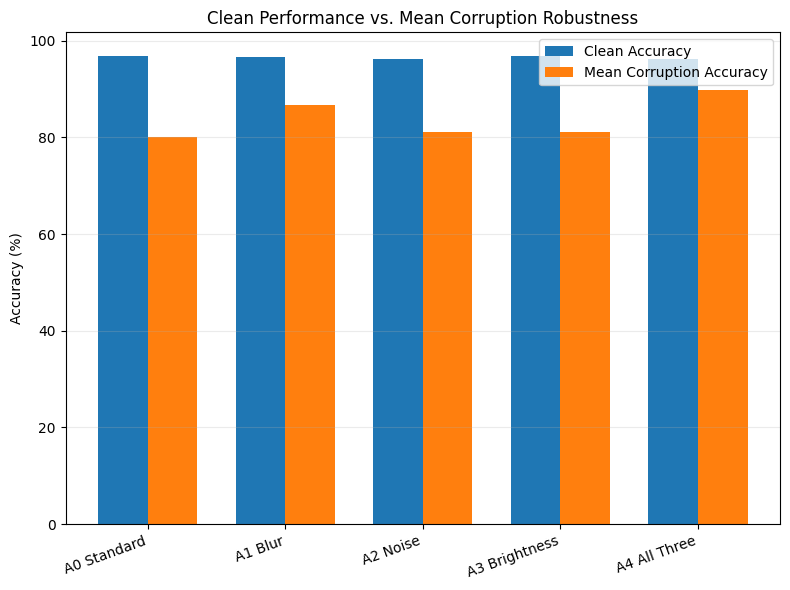

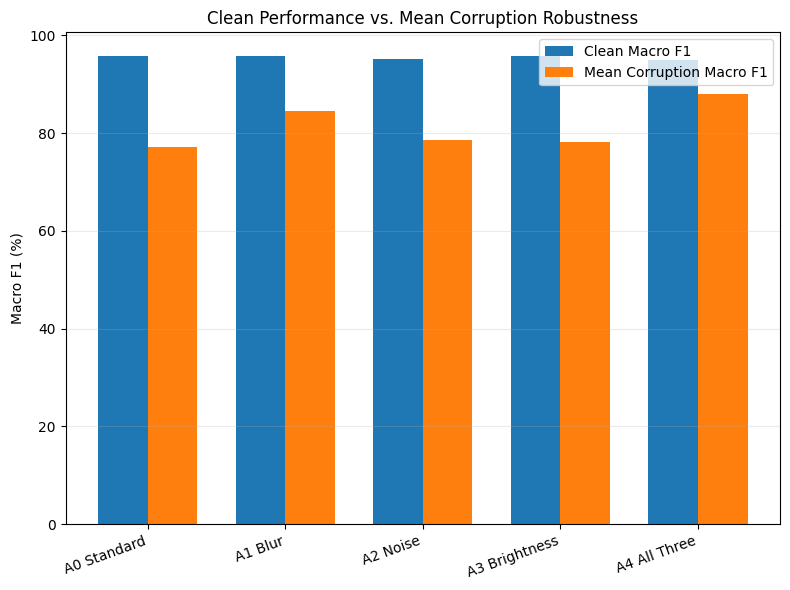

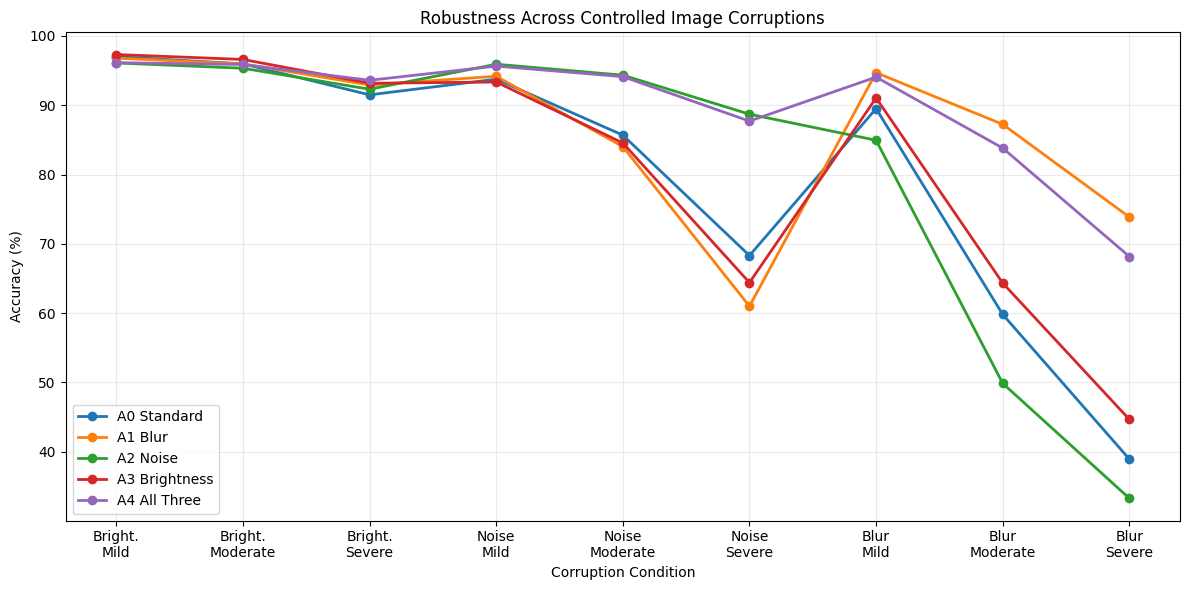

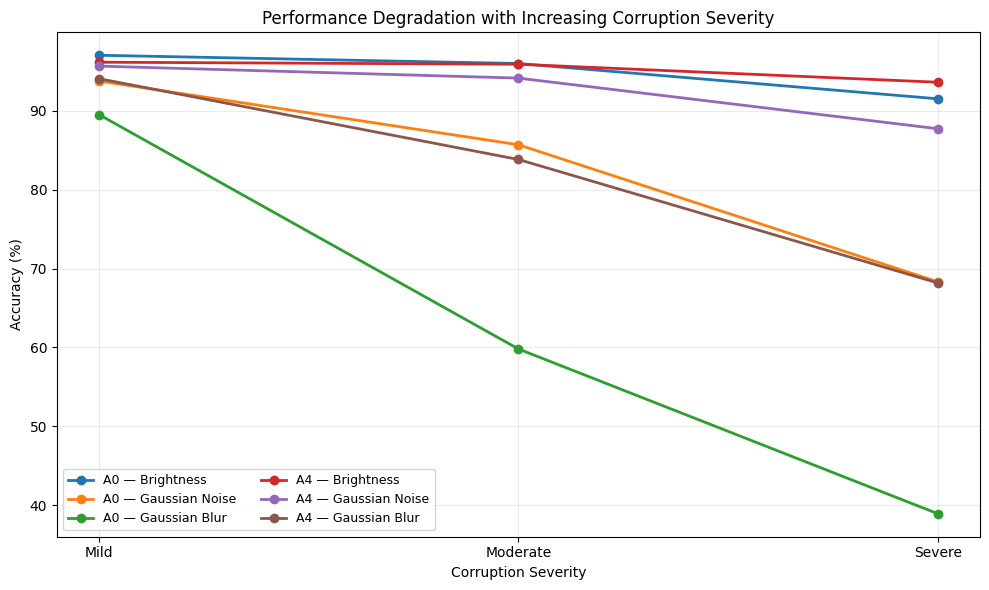


FIGURES GENERATED
Figure_1_Clean_vs_Robustness_Accuracy.png          144.7 KB
Figure_2_Clean_vs_Robustness_MacroF1.png           140.7 KB
Figure_3_Robustness_All_Corruptions.png            356.7 KB
Figure_4_Severity_Degradation_A0_vs_A4.png         271.8 KB

Output directory:
/kaggle/working/architecture_comparison/ablation_studies/robustness_results/paper_figures

FIGURE GENERATION COMPLETE


In [ ]:
# =============================================================================
# PAPER-QUALITY ABLATION FIGURES
# A0–A4 CLEAN + ROBUSTNESS ANALYSIS
# =============================================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# Paths
# -----------------------------------------------------------------------------

RESULTS_DIR = (
    "/kaggle/working/architecture_comparison/"
    "ablation_studies/robustness_results"
)

FINAL_TABLE = os.path.join(
    RESULTS_DIR,
    "final_a0_a4_ablation_summary.csv"
)

ROBUSTNESS_TABLE = os.path.join(
    RESULTS_DIR,
    "a1_a4_ablation_robustness.csv"
)

assert os.path.exists(FINAL_TABLE)
assert os.path.exists(ROBUSTNESS_TABLE)

final_df = pd.read_csv(FINAL_TABLE)
robust_df = pd.read_csv(ROBUSTNESS_TABLE)

# -----------------------------------------------------------------------------
# Model labels
# -----------------------------------------------------------------------------

MODEL_ORDER = [
    "A0_Standard",
    "A1_Blur",
    "A2_Noise",
    "A3_Brightness",
    "A4_All_Three"
]

MODEL_LABELS = {
    "A0_Standard": "A0 Standard",
    "A1_Blur": "A1 Blur",
    "A2_Noise": "A2 Noise",
    "A3_Brightness": "A3 Brightness",
    "A4_All_Three": "A4 All Three"
}

final_df["model"] = pd.Categorical(
    final_df["model"],
    categories=MODEL_ORDER,
    ordered=True
)

final_df = final_df.sort_values("model")

robust_df["model"] = pd.Categorical(
    robust_df["model"],
    categories=MODEL_ORDER[1:],
    ordered=True
)

robust_df = robust_df.sort_values(
    ["model", "corruption", "severity"]
)

# -----------------------------------------------------------------------------
# Figure output directory
# -----------------------------------------------------------------------------

FIG_DIR = os.path.join(
    RESULTS_DIR,
    "paper_figures"
)

os.makedirs(
    FIG_DIR,
    exist_ok=True
)

print("=" * 90)
print("GENERATING PAPER-QUALITY ABLATION FIGURES")
print("=" * 90)

# =============================================================================
# FIGURE 1 — CLEAN ACCURACY VS ROBUSTNESS
# =============================================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)

x = np.arange(len(final_df))
width = 0.36

ax.bar(
    x - width / 2,
    final_df["clean_accuracy"],
    width,
    label="Clean Accuracy"
)

ax.bar(
    x + width / 2,
    final_df["mean_corruption_accuracy"],
    width,
    label="Mean Corruption Accuracy"
)

ax.set_xticks(x)
ax.set_xticklabels(
    [
        MODEL_LABELS[m]
        for m in final_df["model"].astype(str)
    ],
    rotation=20,
    ha="right"
)

ax.set_ylabel("Accuracy (%)")
ax.set_title(
    "Clean Performance vs. Mean Corruption Robustness"
)

ax.legend()
ax.grid(
    axis="y",
    alpha=0.25
)

fig.tight_layout()

fig1_path = os.path.join(
    FIG_DIR,
    "Figure_1_Clean_vs_Robustness_Accuracy.png"
)

fig.savefig(
    fig1_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =============================================================================
# FIGURE 2 — CLEAN MACRO F1 VS ROBUSTNESS MACRO F1
# =============================================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)

ax.bar(
    x - width / 2,
    final_df["clean_macro_f1"],
    width,
    label="Clean Macro F1"
)

ax.bar(
    x + width / 2,
    final_df["mean_corruption_macro_f1"],
    width,
    label="Mean Corruption Macro F1"
)

ax.set_xticks(x)
ax.set_xticklabels(
    [
        MODEL_LABELS[m]
        for m in final_df["model"].astype(str)
    ],
    rotation=20,
    ha="right"
)

ax.set_ylabel("Macro F1 (%)")
ax.set_title(
    "Clean Performance vs. Mean Corruption Robustness"
)

ax.legend()
ax.grid(
    axis="y",
    alpha=0.25
)

fig.tight_layout()

fig2_path = os.path.join(
    FIG_DIR,
    "Figure_2_Clean_vs_Robustness_MacroF1.png"
)

fig.savefig(
    fig2_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =============================================================================
# FIGURE 3 — ROBUSTNESS ACROSS ALL CORRUPTIONS
# =============================================================================

fig, ax = plt.subplots(
    figsize=(12, 6)
)

condition_labels = [
    "Bright.\nMild",
    "Bright.\nModerate",
    "Bright.\nSevere",
    "Noise\nMild",
    "Noise\nModerate",
    "Noise\nSevere",
    "Blur\nMild",
    "Blur\nModerate",
    "Blur\nSevere"
]

condition_keys = [
    ("brightness", "mild"),
    ("brightness", "moderate"),
    ("brightness", "severe"),
    ("gaussian_noise", "mild"),
    ("gaussian_noise", "moderate"),
    ("gaussian_noise", "severe"),
    ("gaussian_blur", "mild"),
    ("gaussian_blur", "moderate"),
    ("gaussian_blur", "severe")
]

for model in MODEL_ORDER:

    if model == "A0_Standard":

        # A0 values from the completed original robustness experiment
        values = [
            97.0212,
            95.9753,
            91.5025,
            93.7623,
            85.6849,
            68.3070,
            89.5135,
            59.8095,
            38.9299
        ]

    else:

        model_values = []

        for corruption, severity in condition_keys:

            row = robust_df[
                (robust_df["model"] == model) &
                (robust_df["corruption"] == corruption) &
                (robust_df["severity"] == severity)
            ]

            assert len(row) == 1

            model_values.append(
                float(row.iloc[0]["accuracy"]) * 100
            )

        values = model_values

    ax.plot(
        range(9),
        values,
        marker="o",
        linewidth=2,
        label=MODEL_LABELS[model]
    )

ax.set_xticks(
    range(9)
)

ax.set_xticklabels(
    condition_labels
)

ax.set_ylabel(
    "Accuracy (%)"
)

ax.set_xlabel(
    "Corruption Condition"
)

ax.set_title(
    "Robustness Across Controlled Image Corruptions"
)

ax.legend(
    loc="best"
)

ax.grid(
    alpha=0.25
)

fig.tight_layout()

fig3_path = os.path.join(
    FIG_DIR,
    "Figure_3_Robustness_All_Corruptions.png"
)

fig.savefig(
    fig3_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =============================================================================
# FIGURE 4 — SEVERITY DEGRADATION BY CORRUPTION TYPE
# =============================================================================

fig, ax = plt.subplots(
    figsize=(10, 6)
)

severity_order = [
    "mild",
    "moderate",
    "severe"
]

severity_numeric = {
    "mild": 1,
    "moderate": 2,
    "severe": 3
}

# Use A0 + A4 because these represent the baseline
# and combined corruption-aware configuration.
for model in ["A0_Standard", "A4_All_Three"]:

    for corruption in [
        "brightness",
        "gaussian_noise",
        "gaussian_blur"
    ]:

        if model == "A0_Standard":

            lookup = {
                ("brightness", "mild"): 97.0212,
                ("brightness", "moderate"): 95.9753,
                ("brightness", "severe"): 91.5025,

                ("gaussian_noise", "mild"): 93.7623,
                ("gaussian_noise", "moderate"): 85.6849,
                ("gaussian_noise", "severe"): 68.3070,

                ("gaussian_blur", "mild"): 89.5135,
                ("gaussian_blur", "moderate"): 59.8095,
                ("gaussian_blur", "severe"): 38.9299
            }

            values = [
                lookup[(corruption, severity)]
                for severity in severity_order
            ]

        else:

            values = []

            for severity in severity_order:

                row = robust_df[
                    (robust_df["model"] == model) &
                    (robust_df["corruption"] == corruption) &
                    (robust_df["severity"] == severity)
                ]

                assert len(row) == 1

                values.append(
                    float(row.iloc[0]["accuracy"]) * 100
                )

        corruption_label = {
            "brightness": "Brightness",
            "gaussian_noise": "Gaussian Noise",
            "gaussian_blur": "Gaussian Blur"
        }[corruption]

        model_label = (
            "A0"
            if model == "A0_Standard"
            else "A4"
        )

        ax.plot(
            [1, 2, 3],
            values,
            marker="o",
            linewidth=2,
            label=f"{model_label} — {corruption_label}"
        )

ax.set_xticks(
    [1, 2, 3]
)

ax.set_xticklabels(
    ["Mild", "Moderate", "Severe"]
)

ax.set_ylabel(
    "Accuracy (%)"
)

ax.set_xlabel(
    "Corruption Severity"
)

ax.set_title(
    "Performance Degradation with Increasing Corruption Severity"
)

ax.legend(
    ncol=2,
    fontsize=9
)

ax.grid(
    alpha=0.25
)

fig.tight_layout()

fig4_path = os.path.join(
    FIG_DIR,
    "Figure_4_Severity_Degradation_A0_vs_A4.png"
)

fig.savefig(
    fig4_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =============================================================================
# FINAL VERIFICATION
# =============================================================================

print("\n" + "=" * 90)
print("FIGURES GENERATED")
print("=" * 90)

for path in [
    fig1_path,
    fig2_path,
    fig3_path,
    fig4_path
]:

    print(
        f"{os.path.basename(path):50s} "
        f"{os.path.getsize(path) / 1024:.1f} KB"
    )

print("\nOutput directory:")
print(FIG_DIR)

print("\nFIGURE GENERATION COMPLETE")
print("=" * 90)

In [ ]:
# =============================================================================
# FINAL RESEARCH ARTIFACT PRESERVATION
# A0–A4 ABLATION + ROBUSTNESS EXPERIMENT
# =============================================================================

import os
import shutil
import json
from datetime import datetime

# -----------------------------------------------------------------------------
# Source / destination
# -----------------------------------------------------------------------------

WORK_ROOT = (
    "/kaggle/working/architecture_comparison/"
    "ablation_studies"
)

PRESERVE_ROOT = (
    "/kaggle/working/"
    "FINAL_ABLATION_RESEARCH_ARTIFACTS"
)

if os.path.exists(PRESERVE_ROOT):
    shutil.rmtree(PRESERVE_ROOT)

os.makedirs(PRESERVE_ROOT, exist_ok=True)

# -----------------------------------------------------------------------------
# Create organized directories
# -----------------------------------------------------------------------------

DIRS = {
    "results": os.path.join(
        PRESERVE_ROOT, "results"
    ),

    "figures": os.path.join(
        PRESERVE_ROOT, "figures"
    ),

    "checkpoints": os.path.join(
        PRESERVE_ROOT, "checkpoints"
    ),

    "experiment_records": os.path.join(
        PRESERVE_ROOT, "experiment_records"
    )
}

for path in DIRS.values():
    os.makedirs(path, exist_ok=True)

# -----------------------------------------------------------------------------
# Files to preserve
# -----------------------------------------------------------------------------

RESULT_FILES = [
    "final_a0_a4_ablation_summary.csv",
    "paper_ready_a0_a4_ablation_table.csv",
    "a0_a4_ablation_deltas.csv",
    "a1_a4_ablation_robustness.csv",
    "a1_a4_ablation_robustness_summary.csv",
]

FIGURE_DIR = os.path.join(
    WORK_ROOT,
    "robustness_results",
    "paper_figures"
)

# -----------------------------------------------------------------------------
# Copy result files
# -----------------------------------------------------------------------------

print("=" * 90)
print("PRESERVING FINAL ABLATION RESEARCH ARTIFACTS")
print("=" * 90)

print("\nRESULT FILES")
print("-" * 90)

copied_results = []

for filename in RESULT_FILES:

    source = os.path.join(
        WORK_ROOT,
        "robustness_results",
        filename
    )

    if os.path.exists(source):

        destination = os.path.join(
            DIRS["results"],
            filename
        )

        shutil.copy2(
            source,
            destination
        )

        copied_results.append(filename)

        print(f"[COPIED] {filename}")

    else:

        print(f"[MISSING] {filename}")

# -----------------------------------------------------------------------------
# Copy figures
# -----------------------------------------------------------------------------

print("\nFIGURES")
print("-" * 90)

copied_figures = []

if os.path.exists(FIGURE_DIR):

    for filename in os.listdir(FIGURE_DIR):

        source = os.path.join(
            FIGURE_DIR,
            filename
        )

        if os.path.isfile(source):

            destination = os.path.join(
                DIRS["figures"],
                filename
            )

            shutil.copy2(
                source,
                destination
            )

            copied_figures.append(filename)

            print(f"[COPIED] {filename}")

else:

    print("[MISSING] Figure directory")

# -----------------------------------------------------------------------------
# Copy all corrected A1–A4 checkpoints
# -----------------------------------------------------------------------------

print("\nCHECKPOINTS")
print("-" * 90)

CHECKPOINTS = {
    "A1_Blur": os.path.join(
        WORK_ROOT,
        "A1_resnet50_blur_corrected",
        "checkpoints",
        "best_model.pth"
    ),

    "A2_Noise": os.path.join(
        WORK_ROOT,
        "A2_resnet50_noise_corrected",
        "checkpoints",
        "best_model.pth"
    ),

    "A3_Brightness": os.path.join(
        WORK_ROOT,
        "A3_resnet50_brightness_corrected",
        "checkpoints",
        "best_model.pth"
    ),

    "A4_All_Three": os.path.join(
        WORK_ROOT,
        "A4_resnet50_all_three_corrected",
        "checkpoints",
        "best_model.pth"
    )
}

copied_checkpoints = []

for name, source in CHECKPOINTS.items():

    if os.path.exists(source):

        destination = os.path.join(
            DIRS["checkpoints"],
            f"{name}_best_model.pth"
        )

        shutil.copy2(
            source,
            destination
        )

        copied_checkpoints.append(
            f"{name}_best_model.pth"
        )

        size_mb = (
            os.path.getsize(destination)
            / (1024 ** 2)
        )

        print(
            f"[COPIED] {name} "
            f"({size_mb:.2f} MB)"
        )

    else:

        print(
            f"[MISSING] {name}"
        )

# -----------------------------------------------------------------------------
# Create experiment manifest
# -----------------------------------------------------------------------------

manifest = {

    "experiment": (
        "A0-A4 ResNet50 Corruption "
        "Ablation and Robustness Study"
    ),

    "created": datetime.now().isoformat(),

    "dataset": "PlantVillage",

    "num_classes": 38,

    "test_samples": 10709,

    "image_size": "224x224",

    "architecture": "ResNet50",

    "pretrained_weights":
        "ImageNet ResNet50 IMAGENET1K_V2",

    "backbone_training":
        "Frozen",

    "trainable_component":
        "Final classification layer",

    "batch_size": 32,

    "optimizer": "AdamW",

    "learning_rate": 0.001,

    "weight_decay": 0.0001,

    "seed": 42,

    "ablations": {

        "A0":
            "Standard ResNet50",

        "A1":
            "ResNet50 + Gaussian Blur",

        "A2":
            "ResNet50 + Gaussian Noise",

        "A3":
            "ResNet50 + Brightness",

        "A4":
            "ResNet50 + Gaussian Blur + "
            "Gaussian Noise + Brightness"
    },

    "robustness_conditions": {

        "brightness":
            ["mild", "moderate", "severe"],

        "gaussian_noise":
            ["mild", "moderate", "severe"],

        "gaussian_blur":
            ["mild", "moderate", "severe"]
    },

    "artifacts": {

        "result_files":
            copied_results,

        "figures":
            copied_figures,

        "checkpoints":
            copied_checkpoints
    },

    "important_note": (
        "A0 checkpoint is not included because "
        "A0 robustness results were already completed "
        "and preserved in the final summary tables."
    )
}

manifest_path = os.path.join(
    DIRS["experiment_records"],
    "experiment_manifest.json"
)

with open(
    manifest_path,
    "w"
) as f:

    json.dump(
        manifest,
        f,
        indent=4
    )

print(
    f"\n[CREATED] {manifest_path}"
)

# -----------------------------------------------------------------------------
# Create README
# -----------------------------------------------------------------------------

readme = """
FINAL A0–A4 ABLATION RESEARCH ARTIFACTS
========================================

This archive contains the final completed
ResNet50 corruption-ablation experiment.

A0:
Standard ResNet50

A1:
ResNet50 + Gaussian Blur

A2:
ResNet50 + Gaussian Noise

A3:
ResNet50 + Brightness

A4:
ResNet50 + Gaussian Blur + Gaussian Noise + Brightness


EXPERIMENT
----------

Dataset:
PlantVillage

Classes:
38

Test samples:
10,709

Input:
224 x 224

Backbone:
ImageNet-pretrained ResNet50

Backbone:
Frozen

Trainable:
Final classification layer

Optimizer:
AdamW

Learning rate:
0.001

Weight decay:
0.0001

Batch size:
32

Seed:
42


ROBUSTNESS CONDITIONS
---------------------

Brightness:
0.80 / 0.60 / 0.40

Gaussian Noise:
0.03 / 0.07 / 0.12

Gaussian Blur:
radius 1 / 2 / 3


MAIN FINDING
------------

A4 achieved the highest mean robustness
among the evaluated A0–A4 configurations,
while incurring a modest reduction in
clean-test performance relative to A0.


FILES
-----

results/
    Final CSV result tables

figures/
    Paper-ready 300 DPI figures

checkpoints/
    A1–A4 best model checkpoints

experiment_records/
    Experiment metadata and manifest


NOTE
----

A0 robustness results were already completed
in the original robustness experiment and are
included in the consolidated final tables.
"""

readme_path = os.path.join(
    PRESERVE_ROOT,
    "README.txt"
)

with open(
    readme_path,
    "w"
) as f:

    f.write(readme)

print(
    f"[CREATED] {readme_path}"
)

# -----------------------------------------------------------------------------
# Create ZIP archive
# -----------------------------------------------------------------------------

archive_base = (
    "/kaggle/working/"
    "FINAL_A0_A4_ABLATION_RESEARCH_ARTIFACTS"
)

zip_path = shutil.make_archive(
    archive_base,
    "zip",
    PRESERVE_ROOT
)

# -----------------------------------------------------------------------------
# Final verification
# -----------------------------------------------------------------------------

print("\n" + "=" * 90)
print("PRESERVATION COMPLETE")
print("=" * 90)

print(
    f"\nResults preserved : "
    f"{len(copied_results)}"
)

print(
    f"Figures preserved : "
    f"{len(copied_figures)}"
)

print(
    f"Checkpoints       : "
    f"{len(copied_checkpoints)}"
)

print(
    f"\nFolder:\n{PRESERVE_ROOT}"
)

print(
    f"\nZIP archive:\n{zip_path}"
)

zip_size_mb = (
    os.path.getsize(zip_path)
    / (1024 ** 2)
)

print(
    f"\nZIP size: {zip_size_mb:.2f} MB"
)

print("\n" + "=" * 90)
print("=" * 90)

PRESERVING FINAL ABLATION RESEARCH ARTIFACTS

RESULT FILES
------------------------------------------------------------------------------------------
[COPIED] final_a0_a4_ablation_summary.csv
[COPIED] paper_ready_a0_a4_ablation_table.csv
[COPIED] a0_a4_ablation_deltas.csv
[COPIED] a1_a4_ablation_robustness.csv
[COPIED] a1_a4_ablation_robustness_summary.csv

FIGURES
------------------------------------------------------------------------------------------
[COPIED] Figure_2_Clean_vs_Robustness_MacroF1.png
[COPIED] Figure_1_Clean_vs_Robustness_Accuracy.png
[COPIED] Figure_3_Robustness_All_Corruptions.png
[COPIED] Figure_4_Severity_Degradation_A0_vs_A4.png

CHECKPOINTS
------------------------------------------------------------------------------------------
[COPIED] A1_Blur (90.87 MB)
[COPIED] A2_Noise (90.87 MB)
[COPIED] A3_Brightness (90.88 MB)
[COPIED] A4_All_Three (90.87 MB)

[CREATED] /kaggle/working/FINAL_ABLATION_RESEARCH_ARTIFACTS/experiment_records/experiment_manifest.json
[CREAT